# Forecasting Market and Industry Betas Using Neural Networks

**Question:** can a neural network use historical risk, return, size and industry information
to forecast a firm's realised market beta over the next 12 months more accurately than a simple
historical rolling-beta estimate?

## Step 0: Exploratory Data Analysis (EDA)
Before modelling, we examine the panel's structure, the sample-selection flags, missing values,
the target and predictor distributions, and the relationships between the historical betas and
the future (target) beta. The EDA only describes the data. No modelling decision is fitted on
validation or test data.

In [1]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def savefig(name):
    plt.savefig(f"figures/{name}.png", bbox_inches="tight")

SPLITS = ["train", "validation", "test"]
SPLIT_COLORS = {"train": "#1f77b4", "validation": "#ff7f0e", "test": "#2ca02c"}

### 0.1 Load the panel and the variable dictionary

In [2]:
df = pd.read_csv("data/neural_beta_panel_1996_2023.csv.gz",
                 parse_dates=["date", "target_start", "target_end", "source_date"])
defs = pd.read_csv("data/variable_definitions.csv")
print(f"Panel shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")
print(f"Date range: {df.date.min().date()} to {df.date.max().date()}; "
      f"unique firms (permno): {df.permno.nunique():,}; unique months: {df.date.nunique()}")
print("Duplicate (permno, date) keys:", df.duplicated(["permno", "date"]).sum())

Panel shape: 1,636,563 rows x 42 columns
Memory: 0.70 GB
Date range: 1996-01-31 to 2023-12-31; unique firms (permno): 15,862; unique months: 336
Duplicate (permno, date) keys: 0


In [3]:
# The variable dictionary, grouped by role
defs.groupby("role")["variable"].apply(lambda s: ", ".join(s)).to_frame("variables")

,variables
role,
audit,"source_date, shrcd"
auxiliary,rf_monthly
auxiliary_not_default_predictor,market_cap_usd
categorical source,siccd
categorical_predictor,industry
identifier,"permno, date, year, month"
numeric_predictor,"ret, market_ret, log_market_cap, mom_12_2, ret..."
outcome NEVER predictor,"return_fwd_1m, return_fwd_12m"
sample control,split


In [4]:
NUM = defs.loc[defs.role == "numeric_predictor", "variable"].tolist()
CAT = defs.loc[defs.role == "categorical_predictor", "variable"].tolist()
IND_SUFFIX = ["nodur", "durbl", "manuf", "enrgy", "hitec", "telcm", "shops", "hlth", "utils", "other"]
IND_TARGETS = [f"beta_fwd_12m_{s}" for s in IND_SUFFIX]
TARGET = "beta_fwd_12m"
GROUPS = defs.loc[defs.role == "numeric_predictor"].groupby("group")["variable"].apply(list).to_dict()
print("Numeric predictors (12):", NUM)
print("Categorical predictor:", CAT)
print("Predictor groups:", GROUPS)

Numeric predictors (12): ['ret', 'market_ret', 'log_market_cap', 'mom_12_2', 'ret_3m', 'vol_12m', 'market_vol_12m', 'beta_12m', 'beta_24m', 'beta_36m', 'beta_daily_12m', 'idio_vol_daily_12m']
Categorical predictor: ['industry']
Predictor groups: {'returns_and_size': ['ret', 'market_ret', 'log_market_cap', 'mom_12_2', 'ret_3m'], 'risk': ['vol_12m', 'market_vol_12m', 'beta_12m', 'beta_24m', 'beta_36m', 'beta_daily_12m', 'idio_vol_daily_12m']}


### 0.2 Sample structure: splits, years and eligibility flags
The panel keeps warm-up rows, the purge years (2012, 2017) and the 2023 forecast-only rows.
Modelling uses only `eligible_core` rows in train/validation/test (and `eligible_multi` for Step 8).

In [5]:
split_tab = (df.groupby("split")
               .agg(rows=("permno", "size"), firms=("permno", "nunique"),
                    first_month=("date", "min"), last_month=("date", "max"),
                    eligible_core=("eligible_core", "sum"), eligible_multi=("eligible_multi", "sum"))
               .reindex(["train", "purge", "validation", "test", "forecast_only"]))
split_tab["core_share"] = split_tab.eligible_core / split_tab.rows
split_tab

,rows,firms,first_month,last_month,eligible_core,eligible_multi,core_share
split,,,,,,,
train,1079815,12661,1996-01-31,2011-12-31,589239,589239,0.5457
purge,89917,5017,2012-01-31,2017-12-31,0,0,0.0000
validation,181531,4622,2013-01-31,2016-12-31,138516,138516,0.7630
test,234896,5437,2018-01-31,2022-12-31,170650,170650,0.7265
forecast_only,50404,4435,2023-01-31,2023-12-31,0,0,0.0000


In [6]:
core = df[df.eligible_core].copy()
core_tab = core.groupby("split").agg(firm_months=("permno", "size"), firms=("permno", "nunique"),
                                     months=("date", "nunique")).reindex(SPLITS)
core_tab["avg_firms_per_month"] = core_tab.firm_months / core_tab.months
print("Eligible-core sample by split (expected 589,239 / 138,516 / 170,650):")
core_tab

Eligible-core sample by split (expected 589,239 / 138,516 / 170,650):


,firm_months,firms,months,avg_firms_per_month
split,,,,
train,589239,7727,157,"3,753.1146"
validation,138516,3547,48,"2,885.7500"
test,170650,3678,60,"2,844.1667"


In [7]:
# Why are rows ineligible? Each reason is counted separately (a row can fail several)
base = df[df.split.isin(SPLITS)]
reasons = pd.DataFrame({
    "target beta_fwd_12m missing": base[TARGET].isna(),
    "beta_12m missing (warm-up)": base.beta_12m.isna(),
    "beta_24m missing (warm-up)": base.beta_24m.isna(),
    "beta_36m missing (warm-up)": base.beta_36m.isna(),
    "market cap missing/nonpositive": base.log_market_cap.isna(),
})
print(f"Train/validation/test rows: {len(base):,}; eligible_core: {base.eligible_core.sum():,}")
reasons.mean().to_frame("share of train/val/test rows").round(4)

Train/validation/test rows: 1,496,242; eligible_core: 898,405


,share of train/val/test rows
target beta_fwd_12m missing,0.1096
beta_12m missing (warm-up),0.1466
beta_24m missing (warm-up),0.2571
beta_36m missing (warm-up),0.3492
market cap missing/nonpositive,0.0273


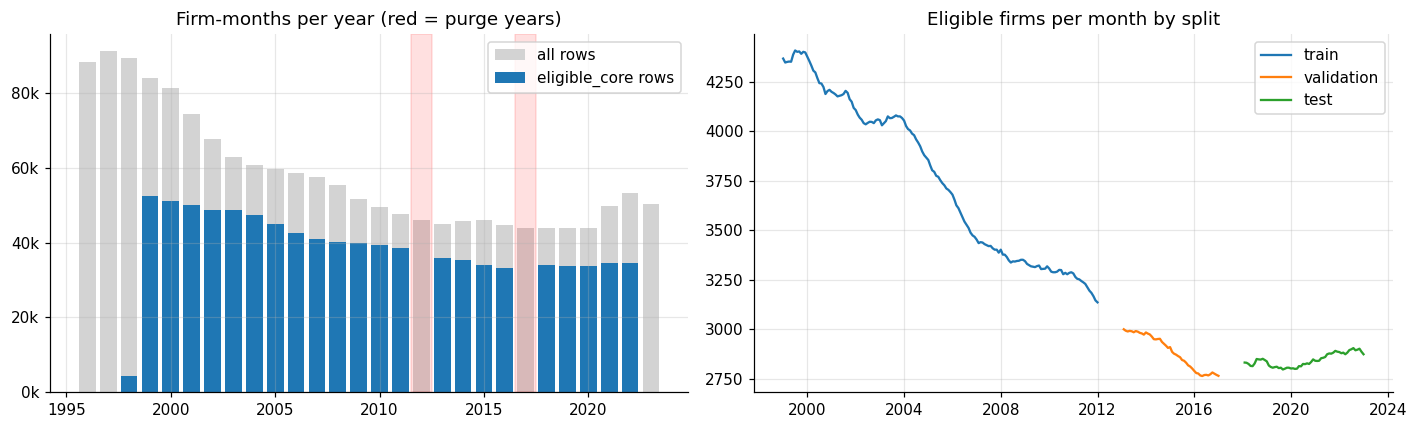

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
per_year = df.groupby(["year", "split"]).size().unstack(fill_value=0)
per_year_core = core.groupby("year").size()
ax[0].bar(per_year.index, per_year.sum(1), color="lightgrey", label="all rows")
ax[0].bar(per_year_core.index, per_year_core, color="#1f77b4", label="eligible_core rows")
for y in (2012, 2017):
    ax[0].axvspan(y - 0.5, y + 0.5, color="red", alpha=0.12)
ax[0].set_title("Firm-months per year (red = purge years)")
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1e3:.0f}k")); ax[0].legend()
firms_m = core.groupby(["date", "split"]).permno.nunique().unstack()
for s in SPLITS:
    ax[1].plot(firms_m.index, firms_m[s], color=SPLIT_COLORS[s], label=s)
ax[1].set_title("Eligible firms per month by split"); ax[1].legend()
plt.tight_layout(); savefig("eda_sample_over_time"); plt.show()

### 0.3 Timing and leakage audit
Predictors are dated at or before month-end $t$ (`date`). The target window starts at $t+1$
and ends at $t+12$. The purge years must stop train and validation labels from overlapping the
next split.

In [9]:
chk = {
    "source_date <= date (all rows)": (df.source_date <= df.date).all(),
    "target_start > date (core rows)": (core.target_start > core.date).all(),
    "target_start = first day of month t+1": (core.target_start == core.date + pd.offsets.Day(1)).all(),
    "target_end = month-end of t+12": (core.target_end == core.date + pd.offsets.MonthEnd(12)).all(),
}
for s in SPLITS:
    chk[f"{s}: last target_end"] = core.loc[core.split == s, "target_end"].max().date()
    chk[f"{s}: first date"] = core.loc[core.split == s, "date"].min().date()
pd.Series(chk, name="check").to_frame()

,check
source_date <= date (all rows),True
target_start > date (core rows),True
target_start = first day of month t+1,True
target_end = month-end of t+12,True
train: last target_end,2012-12-31
train: first date,1998-12-31
validation: last target_end,2017-12-31
validation: first date,2013-01-31
test: last target_end,2023-12-31
test: first date,2018-01-31


In [10]:
# Consistency check on the target definition. beta_fwd_12m at t uses daily returns in t+1..t+12,
# so it should equal the trailing daily beta (beta_daily_12m) recorded 12 months later.
# This confirms the target is future information. It is legitimate for the row at t+12 but must never be an input at t.
lead = df[["permno", "date", "beta_daily_12m"]].copy()
lead["date"] = lead["date"] - pd.offsets.MonthEnd(12)
m = df[["permno", "date", TARGET]].merge(lead, on=["permno", "date"], suffixes=("", "_at_t12")).dropna()
print(f"Matched rows: {len(m):,}; share where beta_fwd_12m(t) == beta_daily_12m(t+12): "
      f"{np.isclose(m[TARGET], m['beta_daily_12m']).mean():.4f}")

Matched rows: 1,413,358; share where beta_fwd_12m(t) == beta_daily_12m(t+12): 1.0000


### 0.4 Missing values
Missing values in the full panel come mostly from warm-up periods. The rolling statistics need
12, 24 or 36 consecutive months of history.

In [11]:
cols = NUM + CAT + [TARGET] + IND_TARGETS + ["return_fwd_1m", "return_fwd_12m", "siccd"]
miss = pd.DataFrame({"full_panel": df[cols].isna().mean()})
for s in SPLITS:
    miss[f"core_{s}"] = core.loc[core.split == s, cols].isna().mean()
print("Share missing. Every predictor is complete in the eligible-core sample (all zeros below).")
miss.round(4)

Share missing. Every predictor is complete in the eligible-core sample (all zeros below).


,full_panel,core_train,core_validation,core_test
ret,0.0321,0.0000,0.0000,0.0000
market_ret,0.0000,0.0000,0.0000,0.0000
log_market_cap,0.0265,0.0000,0.0000,0.0000
mom_12_2,0.1323,0.0000,0.0000,0.0000
ret_3m,0.0520,0.0000,0.0000,0.0000
vol_12m,0.1393,0.0000,0.0000,0.0000
market_vol_12m,0.0493,0.0000,0.0000,0.0000
beta_12m,0.1393,0.0000,0.0000,0.0000
beta_24m,0.2461,0.0000,0.0000,0.0000
beta_36m,0.3367,0.0000,0.0000,0.0000


### 0.5 The target: future 12-month realised market beta

In [12]:
y = core[TARGET]
def dist_stats(s):
    return pd.Series({"n": s.count(), "mean": s.mean(), "std": s.std(), "min": s.min(),
                      "p0.1": s.quantile(.001), "p1": s.quantile(.01), "p25": s.quantile(.25),
                      "median": s.median(), "p75": s.quantile(.75), "p99": s.quantile(.99),
                      "p99.9": s.quantile(.999), "max": s.max(), "skew": s.skew(), "kurtosis": s.kurt(),
                      "share<0": (s < 0).mean(), "share>3": (s > 3).mean()})
target_stats = pd.DataFrame({s: dist_stats(core.loc[core.split == s, TARGET]) for s in SPLITS})
target_stats["all_core"] = dist_stats(y)
target_stats

,train,validation,test,all_core
n,"589,239.0000","138,516.0000","170,650.0000","898,405.0000"
mean,0.8792,1.0691,1.0693,0.9446
std,0.6429,0.5765,0.5361,0.6205
min,-3.5741,-4.8790,-10.8554,-10.8554
p0.1,-0.9130,-1.0465,-0.9855,-0.9392
p1,-0.2879,-0.1953,-0.0351,-0.2469
p25,0.3783,0.7486,0.7348,0.4960
median,0.8369,1.0579,1.0503,0.9334
p75,1.2978,1.3816,1.3684,1.3301
p99,2.5803,2.6701,2.5336,2.5873


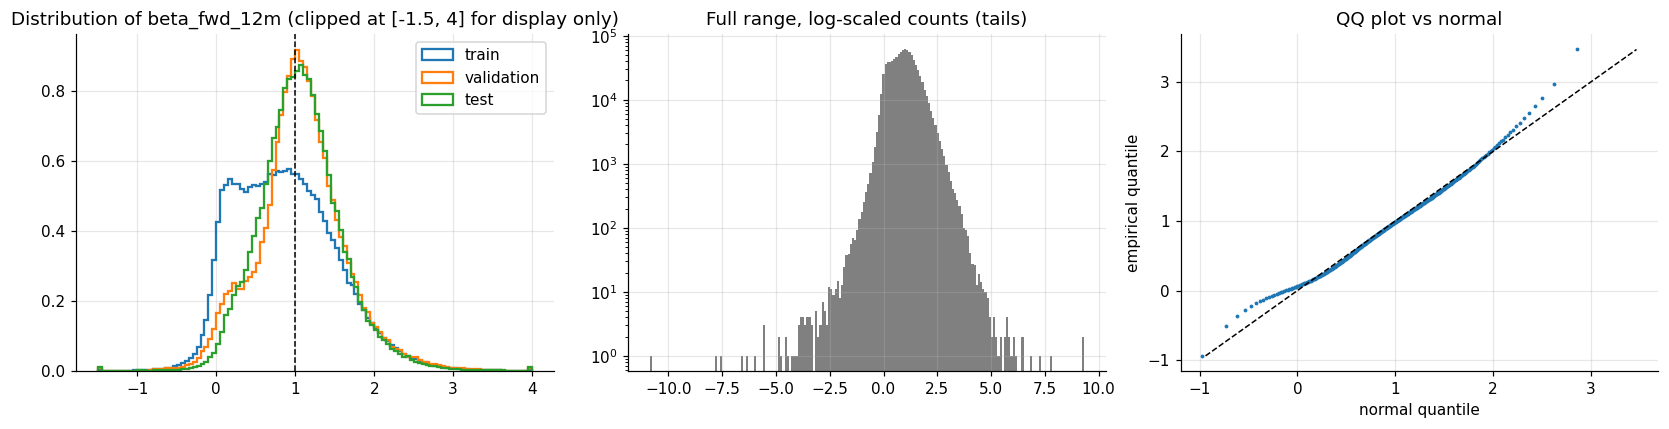

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bins = np.linspace(-1.5, 4, 111)
for s in SPLITS:
    ax[0].hist(core.loc[core.split == s, TARGET].clip(-1.5, 4), bins=bins, density=True,
               histtype="step", lw=1.5, color=SPLIT_COLORS[s], label=s)
ax[0].axvline(1, color="k", ls="--", lw=1); ax[0].legend()
ax[0].set_title("Distribution of beta_fwd_12m (clipped at [-1.5, 4] for display only)")
ax[1].hist(y, bins=200, color="grey", log=True)
ax[1].set_title("Full range, log-scaled counts (tails)")
from scipy import stats
qs = np.linspace(0.001, 0.999, 400)
ax[2].plot(stats.norm.ppf(qs, y.mean(), y.std()), np.quantile(y, qs), ".", ms=3)
lim = [y.quantile(.001), y.quantile(.999)]; ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_title("QQ plot vs normal"); ax[2].set_xlabel("normal quantile"); ax[2].set_ylabel("empirical quantile")
plt.tight_layout(); savefig("eda_target_distribution"); plt.show()

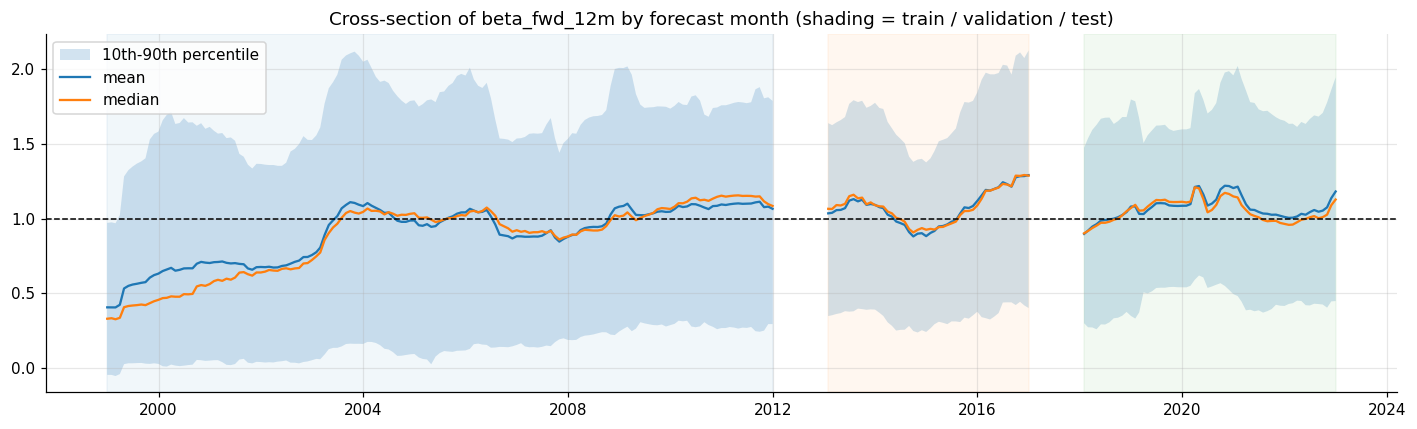

Target cross-sectional mean by split: {'train': 0.879, 'validation': 1.069, 'test': 1.069}


In [14]:
# The target's cross-sectional distribution over time
ts = core.groupby("date")[TARGET].agg(mean="mean", median="median",
                                      p10=lambda s: s.quantile(.1), p90=lambda s: s.quantile(.9),
                                      std="std")
ts = ts.reindex(pd.date_range(ts.index.min(), ts.index.max(), freq="M"))  # leave purge years blank
fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(ts.index, ts.p10, ts.p90, alpha=0.2, label="10th-90th percentile")
ax.plot(ts.index, ts["mean"], label="mean"); ax.plot(ts.index, ts["median"], label="median")
ax.axhline(1, color="k", ls="--", lw=1)
for s in SPLITS:
    d = core.loc[core.split == s, "date"]; ax.axvspan(d.min(), d.max(), color=SPLIT_COLORS[s], alpha=0.06)
ax.set_title("Cross-section of beta_fwd_12m by forecast month (shading = train / validation / test)")
ax.legend(loc="upper left"); plt.tight_layout(); savefig("eda_target_over_time"); plt.show()
print("Target cross-sectional mean by split:", core.groupby("split")[TARGET].mean().reindex(SPLITS).round(3).to_dict())

### 0.6 Predictor distributions
The summary statistics show which predictors are heavy-tailed. This motivates winsorising the
predictors in Step 3, with thresholds fitted on the training sample only.

In [15]:
tr = core[core.split == "train"]
pred_stats = tr[NUM].describe(percentiles=[.001, .01, .5, .99, .999]).T
pred_stats["skew"] = tr[NUM].skew(); pred_stats["kurtosis"] = tr[NUM].kurt()
pred_stats["missing"] = tr[NUM].isna().mean()
pred_stats["group"] = [next(g for g, v in GROUPS.items() if c in v) for c in NUM]
print("Numeric predictors, TRAINING eligible-core sample")
pred_stats

Numeric predictors, TRAINING eligible-core sample


,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max,skew,kurtosis,missing,group
ret,"589,239.0000",0.0133,0.1854,-0.9722,-0.6046,-0.3881,0.0016,0.6000,1.5634,13.4951,5.3082,151.5707,0.0000,returns_and_size
market_ret,"589,239.0000",0.0042,0.0487,-0.1848,-0.1848,-0.1024,0.0109,0.1095,0.1141,0.1141,-0.5309,0.5377,0.0000,returns_and_size
log_market_cap,"589,239.0000",19.5434,2.1195,12.3008,14.2613,15.2647,19.4484,24.8235,26.1741,27.1242,0.2750,-0.1998,0.0000,returns_and_size
mom_12_2,"589,239.0000",0.1581,0.8487,-0.9936,-0.9315,-0.8122,0.0343,3.2085,9.0813,49.9803,9.1293,225.0730,0.0000,returns_and_size
ret_3m,"589,239.0000",0.0421,0.3628,-0.9681,-0.7889,-0.5883,0.0112,1.1887,3.2222,41.4000,11.5819,615.5518,0.0000,returns_and_size
vol_12m,"589,239.0000",0.1475,0.1158,0.0039,0.0186,0.0294,0.1181,0.5720,1.0841,3.9271,4.8087,65.3784,0.0000,risk
market_vol_12m,"589,239.0000",0.0458,0.0176,0.0171,0.0171,0.0178,0.0470,0.0934,0.0941,0.0941,0.2936,-0.4202,0.0000,risk
beta_12m,"589,239.0000",1.1445,1.4735,-29.0429,-5.0025,-1.8862,0.9398,5.9453,10.3583,36.2877,1.5590,15.4297,0.0000,risk
beta_24m,"589,239.0000",1.1584,1.1249,-12.1671,-2.2315,-0.7766,0.9614,4.9003,7.7504,18.8346,1.5563,7.3829,0.0000,risk
beta_36m,"589,239.0000",1.1407,0.9898,-7.0690,-1.4366,-0.4495,0.9566,4.4200,6.5313,15.7317,1.4398,4.9814,0.0000,risk


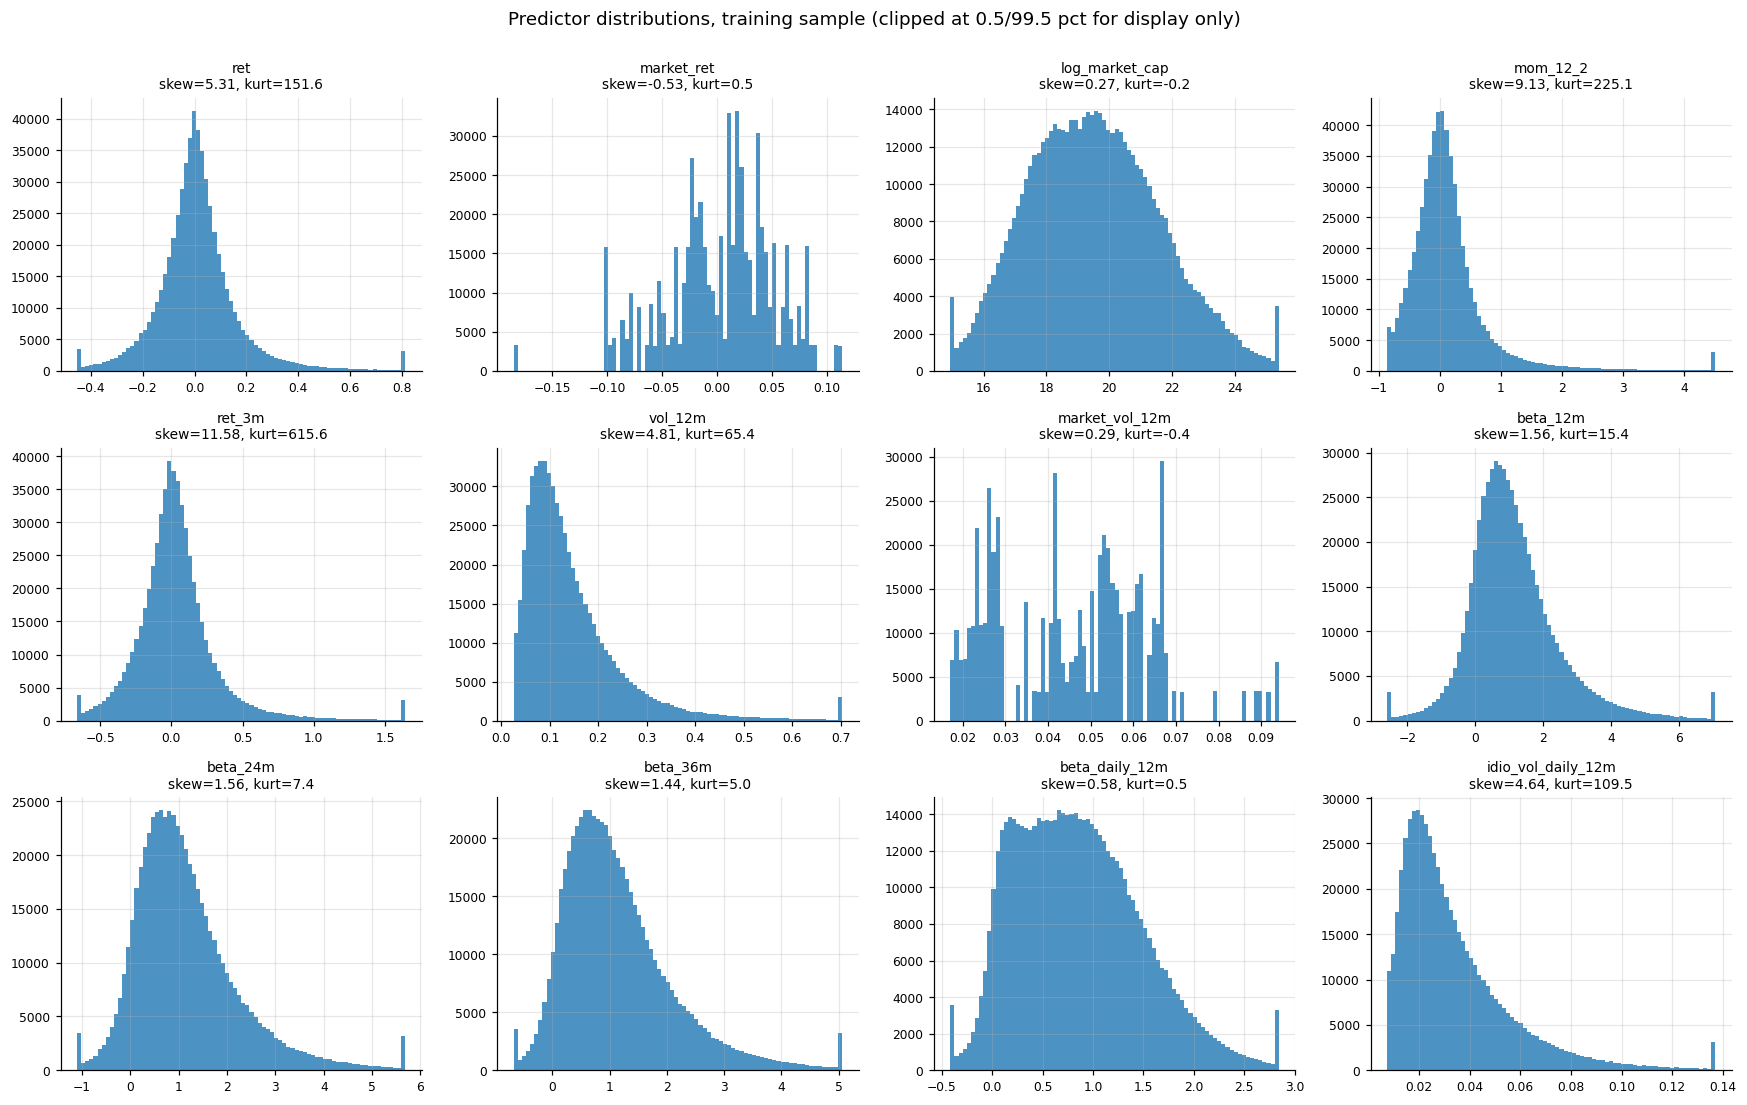

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), NUM):
    s = tr[c].dropna(); lo, hi = s.quantile([.005, .995])
    ax.hist(s.clip(lo, hi), bins=80, color="#1f77b4", alpha=0.8)
    ax.set_title(f"{c}\nskew={s.skew():.2f}, kurt={s.kurt():.1f}", fontsize=9)
    ax.tick_params(labelsize=8)
plt.suptitle("Predictor distributions, training sample (clipped at 0.5/99.5 pct for display only)", y=1.0)
plt.tight_layout(); savefig("eda_predictor_hists"); plt.show()

In [17]:
# Do predictor distributions shift across splits? Medians by split
core.groupby("split")[NUM].median().reindex(SPLITS).T

split,train,validation,test
ret,0.0016,0.0087,0.0000
market_ret,0.0109,0.0117,0.0160
log_market_cap,19.4484,20.4570,20.7593
mom_12_2,0.0343,0.0902,0.0176
ret_3m,0.0112,0.0263,0.0011
vol_12m,0.1181,0.0838,0.1107
market_vol_12m,0.0470,0.0277,0.0476
beta_12m,0.9398,1.0507,1.0317
beta_24m,0.9614,1.0794,1.1453
beta_36m,0.9566,1.1063,1.1784


### 0.7 Industry composition
`industry` is the Fama-French 10 mapping of the firm's historical SIC code, plus `Unknown` where
the SIC code is missing or invalid.

In [18]:
ind = (core.groupby(["industry", "split"]).size().unstack().reindex(columns=SPLITS))
ind_share = ind / ind.sum()
ind_beta = core.groupby("industry")[TARGET].agg(["mean", "median", "std"])
ind_summary = pd.concat([ind, ind_share.add_suffix("_share"), ind_beta.add_prefix("beta_fwd_")], axis=1)
ind_summary.sort_values("train", ascending=False)

,train,validation,test,train_share,validation_share,test_share,beta_fwd_mean,beta_fwd_median,beta_fwd_std
industry,,,,,,,,,
Other,"182,078.0000","49,892.0000","75,983.0000",0.3090,0.3602,0.4453,0.8766,0.8850,0.6178
HiTec,"112,893.0000","21,952.0000","22,271.0000",0.1916,0.1585,0.1305,1.1132,1.0937,0.6649
Manuf,"71,413.0000","16,399.0000","18,051.0000",0.1212,0.1184,0.1058,1.0156,1.0342,0.6133
Shops,"63,930.0000","12,619.0000","14,963.0000",0.1085,0.0911,0.0877,0.9038,0.9102,0.5435
Hlth,"60,031.0000","13,991.0000","15,095.0000",0.1019,0.1010,0.0885,0.9243,0.8809,0.5916
NoDur,"32,640.0000","6,789.0000","7,245.0000",0.0554,0.0490,0.0425,0.7097,0.6607,0.5143
Enrgy,"19,935.0000","5,594.0000","5,287.0000",0.0338,0.0404,0.0310,1.1890,1.1965,0.7267
Utils,"16,918.0000","4,174.0000","4,183.0000",0.0287,0.0301,0.0245,0.6505,0.6326,0.4028
Telcm,"15,062.0000","3,838.0000","3,895.0000",0.0256,0.0277,0.0228,1.0418,1.0223,0.5569


In [19]:
print("Rows labelled 'Unknown' by split:", core.loc[core.industry == "Unknown"].split.value_counts().to_dict())
print("-> 'Unknown' never appears in training, so the one-hot encoder (fit on train) must ignore unseen categories.")

Rows labelled 'Unknown' by split: {'test': 149, 'validation': 5}
-> 'Unknown' never appears in training, so the one-hot encoder (fit on train) must ignore unseen categories.


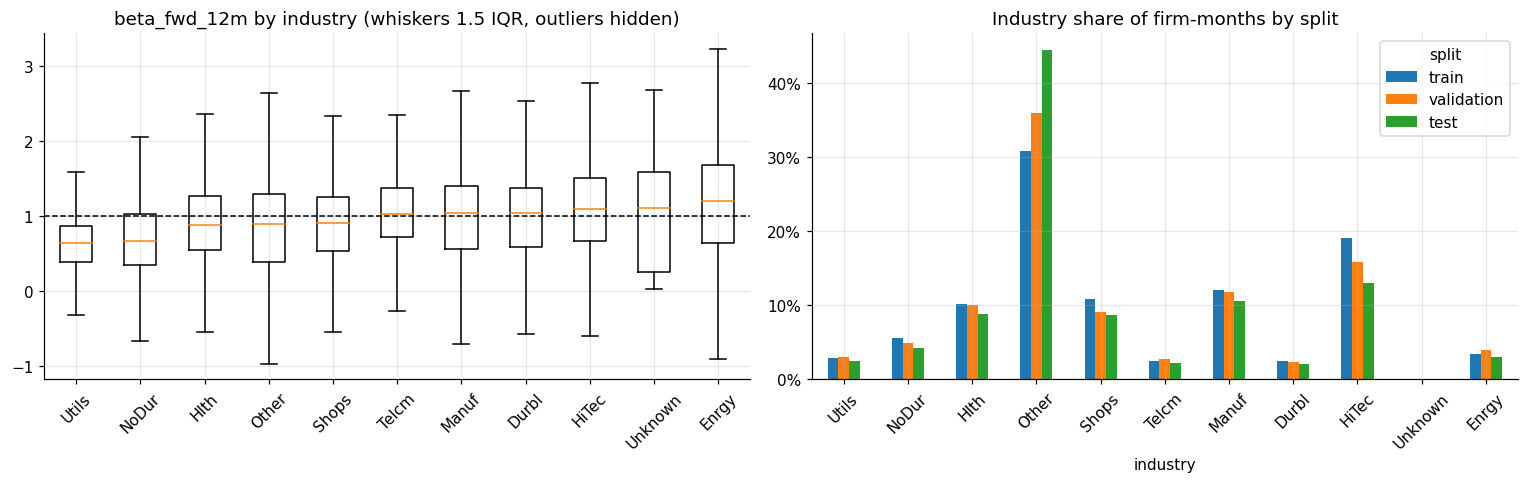

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
order = ind_beta.sort_values("median").index
data = [core.loc[core.industry == i, TARGET].values for i in order]
ax[0].boxplot(data, labels=order, showfliers=False, vert=True)
ax[0].axhline(1, color="k", ls="--", lw=1); ax[0].tick_params(axis="x", rotation=45)
ax[0].set_title("beta_fwd_12m by industry (whiskers 1.5 IQR, outliers hidden)")
ind_share.loc[order].plot.bar(ax=ax[1], color=[SPLIT_COLORS[s] for s in SPLITS])
ax[1].set_title("Industry share of firm-months by split"); ax[1].tick_params(axis="x", rotation=45)
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); savefig("eda_industry"); plt.show()

### 0.8 How informative are historical betas about future beta?
If beta were perfectly persistent, the points would lie on the 45° line. Scatter below
45° shows mean reversion, where extreme historical betas are followed by less extreme betas.

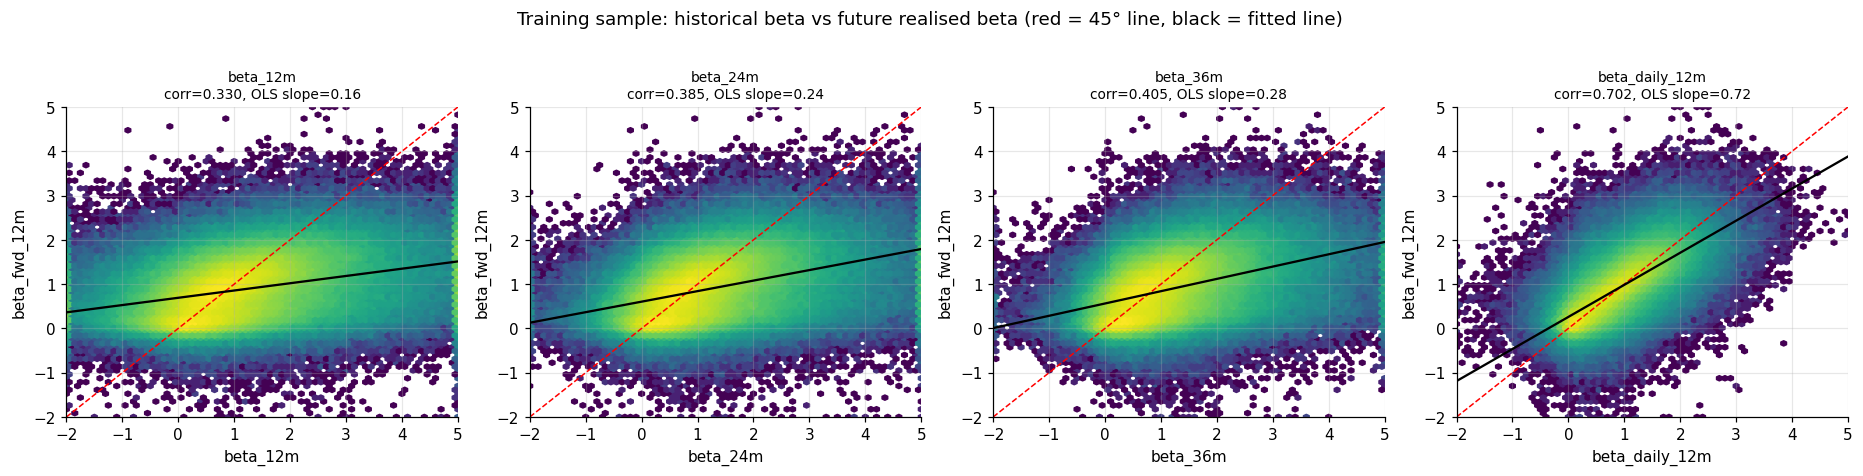

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, c in zip(axes, ["beta_12m", "beta_24m", "beta_36m", "beta_daily_12m"]):
    m = tr[[c, TARGET]].dropna()
    ax.hexbin(m[c].clip(-2, 5), m[TARGET].clip(-2, 5), gridsize=70, bins="log", cmap="viridis", mincnt=1)
    ax.plot([-2, 5], [-2, 5], "r--", lw=1)
    b = np.polyfit(m[c].clip(m[c].quantile(.005), m[c].quantile(.995)), m[TARGET], 1)
    xs = np.array([-2, 5]); ax.plot(xs, b[1] + b[0] * xs, "k-", lw=1.5)
    ax.set_title(f"{c}\ncorr={m[c].corr(m[TARGET]):.3f}, OLS slope={b[0]:.2f}", fontsize=9)
    ax.set_xlabel(c); ax.set_ylabel(TARGET); ax.set_xlim(-2, 5); ax.set_ylim(-2, 5)
plt.suptitle("Training sample: historical beta vs future realised beta (red = 45° line, black = fitted line)", y=1.02)
plt.tight_layout(); savefig("eda_persistence"); plt.show()

In [22]:
# Mean reversion in bins: average future beta within deciles of each historical beta (training)
rows = {}
for c in ["beta_12m", "beta_36m", "beta_daily_12m"]:
    m = tr[[c, TARGET]].dropna()
    dec = pd.qcut(m[c], 10, labels=False)
    rows[c] = pd.DataFrame({"hist_mean": m.groupby(dec)[c].mean(), "fwd_mean": m.groupby(dec)[TARGET].mean()})
pd.concat(rows, axis=1).rename_axis("decile")

beta_12m           beta_36m          beta_daily_12m         
       hist_mean fwd_mean hist_mean fwd_mean      hist_mean fwd_mean
decile                                                              
0        -0.9430   0.5909   -0.1352   0.4505        -0.0685   0.2502
1        -0.0112   0.5544    0.2600   0.5464         0.1838   0.3190
2         0.3054   0.6250    0.4718   0.6415         0.3619   0.4749
3         0.5638   0.7216    0.6637   0.7335         0.5392   0.6297
4         0.8119   0.8101    0.8574   0.8191         0.7123   0.7696
5         1.0744   0.8998    1.0628   0.9133         0.8841   0.9230
6         1.3742   0.9938    1.2995   1.0026         1.0627   1.0801
7         1.7574   1.0953    1.5999   1.1084         1.2632   1.2369
8         2.3498   1.1955    2.0574   1.2128         1.5233   1.4120
9         4.1627   1.3060    3.2702   1.3642         2.0897   1.6967

In [23]:
# Size and the level of daily vs monthly betas (all eligible-core rows, by size quintile)
q = pd.qcut(core.log_market_cap, 5, labels=[f"Q{i} {'(small)' if i==1 else '(large)' if i==5 else ''}" for i in range(1, 6)])
core.groupby(q)[["beta_12m", "beta_36m", "beta_daily_12m", TARGET]].mean().round(3)

,beta_12m,beta_36m,beta_daily_12m,beta_fwd_12m
log_market_cap,,,,
Q1 (small),0.9360,1.0150,0.4360,0.4370
Q2,1.1280,1.1680,0.7580,0.7760
Q3,1.3010,1.3000,1.1650,1.2330
Q4,1.2420,1.2580,1.1720,1.1990
Q5 (large),1.0670,1.1040,1.0700,1.0780


In [24]:
# Average target by forecast year, showing time variation and the level shift between train and later splits
core.groupby("year")[TARGET].agg(["mean", "median", "std"]).round(3).T

year,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2013,2014,2015,2016,2018,2019,2020,2021,2022
mean,0.4070,0.5380,0.6760,0.6930,0.7040,0.9990,1.0280,0.9890,0.9720,0.8810,0.9640,1.0470,1.0830,1.0940,1.0860,0.9650,1.0020,1.2300,0.9880,1.0780,1.1610,1.0640,1.0570
median,0.3310,0.4020,0.5060,0.6140,0.6700,0.9430,1.0380,1.0020,0.9930,0.8970,0.9360,1.0360,1.1220,1.1370,1.1080,0.9830,0.9860,1.2250,0.9790,1.0990,1.1290,1.0160,1.0130
std,0.4660,0.5620,0.6940,0.6090,0.5620,0.7080,0.6750,0.6740,0.6110,0.5480,0.5860,0.6010,0.5530,0.5740,0.5460,0.5070,0.5450,0.6660,0.5170,0.4850,0.5610,0.5540,0.5450


### 0.9 Correlations: predictors with the target, and among predictors

In [25]:
corr_cols = NUM + [TARGET]
pear = tr[corr_cols].corr()[TARGET].drop(TARGET)
spear = tr[corr_cols].corr(method="spearman")[TARGET].drop(TARGET)
corr_tab = pd.DataFrame({"pearson": pear, "spearman": spear}).sort_values("spearman", key=abs, ascending=False)
print("Correlation of each predictor with beta_fwd_12m (training sample)")
corr_tab

Correlation of each predictor with beta_fwd_12m (training sample)


,pearson,spearman
beta_daily_12m,0.7023,0.7336
log_market_cap,0.4091,0.4862
beta_36m,0.4047,0.4388
beta_24m,0.3846,0.4289
beta_12m,0.3302,0.3852
vol_12m,0.1654,0.1733
mom_12_2,0.1749,0.1226
market_vol_12m,-0.0753,-0.1036
ret_3m,0.0818,0.0606
ret,0.0418,0.0371


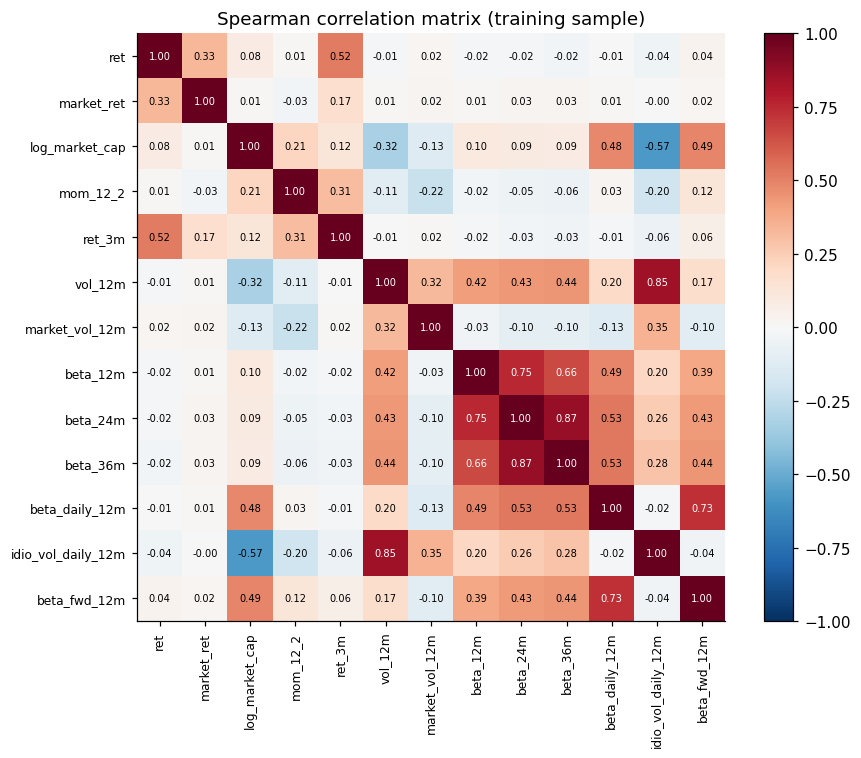

In [26]:
C = tr[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C))); ax.set_xticklabels(C.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(C))); ax.set_yticklabels(C.columns, fontsize=8)
for i in range(len(C)):
    for j in range(len(C)):
        ax.text(j, i, f"{C.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(C.iat[i, j]) > 0.6 else "black")
plt.colorbar(im, fraction=0.046); ax.set_title("Spearman correlation matrix (training sample)"); ax.grid(False)
plt.tight_layout(); savefig("eda_corr_matrix"); plt.show()

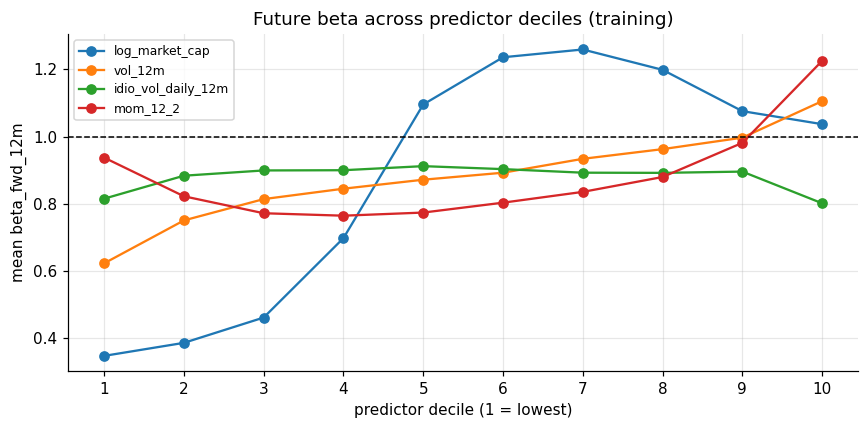

,log_market_cap,vol_12m,idio_vol_daily_12m,mom_12_2
decile,,,,
1,0.3462,0.6221,0.8148,0.9372
2,0.3851,0.7500,0.8833,0.8220
3,0.4605,0.8136,0.8990,0.7714
4,0.6973,0.8446,0.8997,0.7641
5,1.0957,0.8714,0.9118,0.7734
6,1.2364,0.8922,0.9029,0.8029
7,1.2596,0.9336,0.8923,0.8351
8,1.1989,0.9625,0.8918,0.8794
9,1.0758,0.9967,0.8956,0.9812


In [27]:
# Size and volatility relationship with future beta: mean target by decile (training)
out = {}
for c in ["log_market_cap", "vol_12m", "idio_vol_daily_12m", "mom_12_2"]:
    m = tr[[c, TARGET]].dropna(); dec = pd.qcut(m[c], 10, labels=False, duplicates="drop") + 1
    out[c] = m.groupby(dec)[TARGET].mean()
fig, ax = plt.subplots(figsize=(8, 4))
for c, s in out.items():
    ax.plot(s.index, s.values, marker="o", label=c)
ax.axhline(1, color="k", ls="--", lw=1); ax.set_xticks(range(1, 11))
ax.set_xlabel("predictor decile (1 = lowest)"); ax.set_ylabel("mean beta_fwd_12m")
ax.set_title("Future beta across predictor deciles (training)"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("eda_deciles"); plt.show()
pd.DataFrame(out).rename_axis("decile")

### 0.10 The ten industry-beta targets (Step 8 sample)

In [28]:
multi = df[df.eligible_multi]
print("eligible_multi firm-months by split:", multi.split.value_counts().reindex(SPLITS).to_dict())
print("eligible_core rows without full industry targets:", len(core) - len(multi))
ind_t = multi[IND_TARGETS + [TARGET]]
ind_t.describe(percentiles=[.01, .5, .99]).T.assign(skew=ind_t.skew())

eligible_multi firm-months by split: {'train': 589239, 'validation': 138516, 'test': 170650}
eligible_core rows without full industry targets: 0


,count,mean,std,min,1%,50%,99%,max,skew
beta_fwd_12m_nodur,"898,405.0000",0.8537,0.6539,-18.5272,-0.6029,0.8556,2.5227,7.5588,0.0598
beta_fwd_12m_durbl,"898,405.0000",0.5479,0.3943,-5.1938,-0.2297,0.5260,1.5834,4.0795,0.3791
beta_fwd_12m_manuf,"898,405.0000",0.8290,0.5469,-7.9095,-0.2848,0.8289,2.2361,7.3954,0.2475
beta_fwd_12m_enrgy,"898,405.0000",0.4307,0.3910,-9.4406,-0.3180,0.3701,1.6016,4.2522,0.9112
beta_fwd_12m_hitec,"898,405.0000",0.6531,0.4869,-6.7847,-0.1841,0.6121,1.9391,9.8118,0.5275
beta_fwd_12m_telcm,"898,405.0000",0.7394,0.5217,-9.5248,-0.2529,0.7136,2.0988,12.3718,0.4145
beta_fwd_12m_shops,"898,405.0000",0.7737,0.5505,-10.0504,-0.2824,0.7518,2.2019,9.2572,0.3592
beta_fwd_12m_hlth,"898,405.0000",0.7500,0.5776,-13.9751,-0.3411,0.6938,2.2936,7.2087,0.4471
beta_fwd_12m_utils,"898,405.0000",0.5679,0.5309,-12.6028,-0.5965,0.5253,2.0571,22.5346,0.5927
beta_fwd_12m_other,"898,405.0000",0.7711,0.5205,-7.8172,-0.2635,0.7649,2.1255,9.1805,0.2836


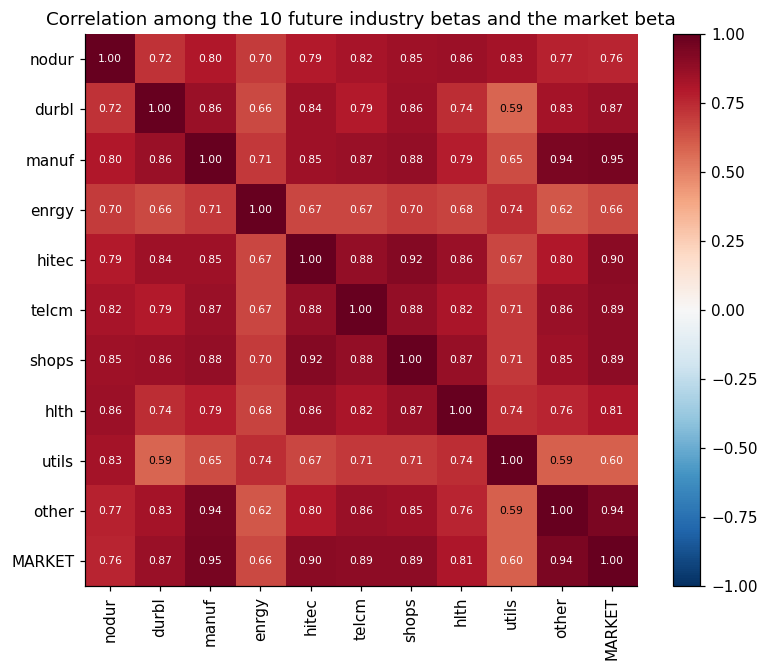

In [29]:
Ct = ind_t.rename(columns=lambda c: c.replace("beta_fwd_12m_", "").replace("beta_fwd_12m", "MARKET")).corr()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(Ct, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(Ct))); ax.set_xticklabels(Ct.columns, rotation=90)
ax.set_yticks(range(len(Ct))); ax.set_yticklabels(Ct.columns)
for i in range(len(Ct)):
    for j in range(len(Ct)):
        ax.text(j, i, f"{Ct.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(Ct.iat[i, j]) > 0.6 else "black")
plt.colorbar(im, fraction=0.046); ax.grid(False)
ax.set_title("Correlation among the 10 future industry betas and the market beta")
plt.tight_layout(); savefig("eda_industry_target_corr"); plt.show()

### 0.11 Outcome used in Step 6: next-month return

In [30]:
r1 = core.groupby("split").return_fwd_1m.agg(n="size", missing=lambda s: s.isna().sum(),
                                             mean="mean", median="median", std="std").reindex(SPLITS)
r1["missing_share"] = r1.missing / r1.n
r1

,n,missing,mean,median,std,missing_share
split,,,,,,
train,589239,59,0.0135,0.0019,0.1845,0.0001
validation,138516,27,0.0114,0.0074,0.1351,0.0002
test,170650,11,0.0102,0.0010,0.2103,0.0001


## Step 1: The Prediction Problem and the Modelling Sample

**Prediction problem.** At the close of month $t$, we use information dated at or before $t$ to forecast
the firm's realised market beta over months $t+1$ to $t+12$:
$$\beta^R_{i,t+12}=\frac{\mathrm{Cov}_{d\in D(t)}(R_{i,d},R_{m,d})}{\mathrm{Var}_{d\in D(t)}(R_{m,d})},\qquad
\widehat\beta^{NN}_{i,t+12}=f_\theta(X_{i,t}).$$
The target (`beta_fwd_12m`) uses **future** daily returns, and every input must be known at $t$.

**Modelling sample.** Rows with `eligible_core == True`, all of which fall in the train (1996–2011),
validation (2013–2016) or test (2018–2022) split. The purge years 2012 and 2017, and the 2023 forecast-only
rows, are never used for fitting or evaluation. The split is chronological; no row is assigned at random.

In [31]:
sample = df.loc[df.eligible_core].copy()
assert set(sample.split.unique()) == set(SPLITS), "eligible_core must only contain train/validation/test"
assert not sample.year.isin([2012, 2017, 2023]).any(), "purge / forecast-only years must be excluded"
assert (sample.split.map({"train": 0, "validation": 1, "test": 2}).groupby(sample.year).nunique() == 1).all()
expected = {"train": 589_239, "validation": 138_516, "test": 170_650}
assert sample.split.value_counts().to_dict() == expected, "counts differ from the expected sample"
print("Modelling sample OK:", {s: f"{n:,}" for s, n in expected.items()})

Modelling sample OK: {'train': '589,239', 'validation': '138,516', 'test': '170,650'}


### 1.1 Inputs, targets and excluded columns
Only the 12 numeric predictors and the `industry` category may enter the model. Every other column is either
an identifier, a future outcome, a target-audit field or a sample-control flag.

In [32]:
FEATURES_NUM = GROUPS["risk"] + GROUPS["returns_and_size"]
FEATURES_CAT = ["industry"]
EXCLUDED = [c for c in df.columns if c not in FEATURES_NUM + FEATURES_CAT]
roles = defs.set_index("variable")[["role", "group"]]
inputs_tab = roles.loc[FEATURES_NUM + FEATURES_CAT].assign(used_as="MODEL INPUT")
excl_tab = roles.reindex(EXCLUDED).assign(used_as="excluded")
pd.concat([inputs_tab, excl_tab])

,role,group,used_as
variable,,,
vol_12m,numeric_predictor,risk,MODEL INPUT
market_vol_12m,numeric_predictor,risk,MODEL INPUT
beta_12m,numeric_predictor,risk,MODEL INPUT
beta_24m,numeric_predictor,risk,MODEL INPUT
beta_36m,numeric_predictor,risk,MODEL INPUT
beta_daily_12m,numeric_predictor,risk,MODEL INPUT
idio_vol_daily_12m,numeric_predictor,risk,MODEL INPUT
ret,numeric_predictor,returns_and_size,MODEL INPUT
market_ret,numeric_predictor,returns_and_size,MODEL INPUT


In [33]:
# Look-ahead guard: none of the forbidden column types may be among the inputs
forbidden = defs.loc[defs.role.str.contains("NEVER|identifier|sample control|audit|auxiliary|categorical source"), "variable"]
assert not set(forbidden) & set(FEATURES_NUM + FEATURES_CAT)
print(f"{len(FEATURES_NUM)} numeric + {len(FEATURES_CAT)} categorical inputs; "
      f"{len(forbidden)} forbidden columns, none of which are inputs.")

12 numeric + 1 categorical inputs; 29 forbidden columns, none of which are inputs.


### 1.2 Verifying that predictors are dated at or before $t$ and the target uses future returns
Three checks:
1. **Timing fields.** `source_date ≤ date`, and the target window starts in month $t+1$ and ends at the end of $t+12$ (done in Step 0.3).
2. **Recomputing the predictors.** For a random sample of 500 firms, we rebuild `beta_12m`, `beta_24m`, `beta_36m`,
   `vol_12m`, `market_vol_12m`, `mom_12_2` and `ret_3m` from the monthly `ret` and `market_ret` of months
   $\le t$ only. If the rebuilt values match the supplied values, the supplied predictors cannot contain
   any information from after $t$.
3. **The target is future information.** `beta_fwd_12m`$(t)$ = `beta_daily_12m`$(t+12)$ (Step 0.3), and the
   target is far less correlated with the *contemporaneous* daily beta than with the one 12 months ahead.

In [34]:
rng = np.random.default_rng(SEED)
firms = rng.choice(df.permno.unique(), 500, replace=False)
recomp = []
for p, g in df[df.permno.isin(firms)].groupby("permno"):
    g = g.set_index(g.date.dt.to_period("M")).sort_index()
    g = g.reindex(pd.period_range(g.index.min(), g.index.max(), freq="M"))  # gaps -> NaN -> window invalid
    r, m = g["ret"], g["market_ret"]
    out = pd.DataFrame(index=g.index)
    for w in (12, 24, 36):  # OLS slope with intercept over t-w+1..t (needs w consecutive complete months)
        out[f"beta_{w}m"] = r.rolling(w).cov(m) / m.rolling(w).var()
    out["vol_12m"] = r.rolling(12).std()
    out["market_vol_12m"] = m.rolling(12).std()
    out["mom_12_2"] = np.expm1(np.log1p(r).shift(1).rolling(11).sum())   # t-11..t-1, skips month t
    out["ret_3m"] = np.expm1(np.log1p(r).rolling(3).sum())              # t-2..t
    out = out.add_suffix("_re").join(g[[c for c in out.columns]]).dropna(how="all")
    recomp.append(out)
recomp = pd.concat(recomp)
ver = []
for c in ["beta_12m", "beta_24m", "beta_36m", "vol_12m", "market_vol_12m", "mom_12_2", "ret_3m"]:
    both = recomp[[c, c + "_re"]].dropna()
    ver.append({"predictor": c, "rows compared": len(both),
                "max |supplied - recomputed|": (both[c] - both[c + "_re"]).abs().max(),
                "share matching (tol 1e-4)": np.isclose(both[c], both[c + "_re"], atol=1e-4).mean()})
verify_tab = pd.DataFrame(ver).set_index("predictor")
verify_tab

,rows compared,max |supplied - recomputed|,share matching (tol 1e-4)
predictor,,,
beta_12m,45225,0.0000,1.0000
beta_24m,39724,0.0000,1.0000
beta_36m,35120,0.0000,1.0000
vol_12m,45225,0.0000,1.0000
market_vol_12m,47149,0.0000,1.0000
mom_12_2,45580,0.0000,1.0000
ret_3m,49745,0.0000,1.0000


In [35]:
# Target vs the same firm's daily beta at t (known) and at t+12 (future), eligible rows
lead = df[["permno", "date", "beta_daily_12m"]].copy()
lead["date"] -= pd.offsets.MonthEnd(12)
tmp = sample[["permno", "date", TARGET, "beta_daily_12m"]].merge(
    lead.rename(columns={"beta_daily_12m": "beta_daily_12m_at_t+12"}), on=["permno", "date"], how="left")
print("corr(target, beta_daily_12m at t)      =", round(tmp[TARGET].corr(tmp["beta_daily_12m"]), 4))
print("corr(target, beta_daily_12m at t + 12) =", round(tmp[TARGET].corr(tmp["beta_daily_12m_at_t+12"]), 4),
      "  <- identical series: the target is the future daily beta")

corr(target, beta_daily_12m at t)      = 0.6702
corr(target, beta_daily_12m at t + 12) = 1.0   <- identical series: the target is the future daily beta


### 1.3 Firms and firm-month observations by split

In [36]:
sample_tab = sample.groupby("split").agg(
    first_month=("date", "min"), last_month=("date", "max"), months=("date", "nunique"),
    firm_months=("permno", "size"), firms=("permno", "nunique")).reindex(SPLITS)
sample_tab["firms_per_month_avg"] = (sample.groupby(["split", "date"]).size().groupby("split").mean()).round(0)
sample_tab["share_of_sample"] = sample_tab.firm_months / len(sample)
sample_tab.loc["total"] = [sample.date.min(), sample.date.max(), sample.date.nunique(), len(sample),
                           sample.permno.nunique(), np.nan, 1.0]
sample_tab.to_csv("results/step1_sample_by_split.csv")
sample_tab

,first_month,last_month,months,firm_months,firms,firms_per_month_avg,share_of_sample
split,,,,,,,
train,1998-12-31,2011-12-31,157,589239,7727,"3,753.0000",0.6559
validation,2013-01-31,2016-12-31,48,138516,3547,"2,886.0000",0.1542
test,2018-01-31,2022-12-31,60,170650,3678,"2,844.0000",0.1899
total,1998-12-31,2022-12-31,265,898405,9378,NaN,1.0000


In [37]:
# The split is by time, so the same firm can appear in several splits (at different dates). This is fine,
# because no future information about any firm enters an earlier split's inputs or labels.
fs = {s: set(sample.loc[sample.split == s, "permno"]) for s in SPLITS}
print(f"Firms in train & validation: {len(fs['train'] & fs['validation']):,}; "
      f"train & test: {len(fs['train'] & fs['test']):,}; test firms never seen in training: "
      f"{len(fs['test'] - fs['train']):,} ({len(fs['test'] - fs['train'])/len(fs['test']):.1%})")

Firms in train & validation: 2,957; train & test: 2,194; test firms never seen in training: 1,484 (40.3%)


### 1.4 Distribution of the target

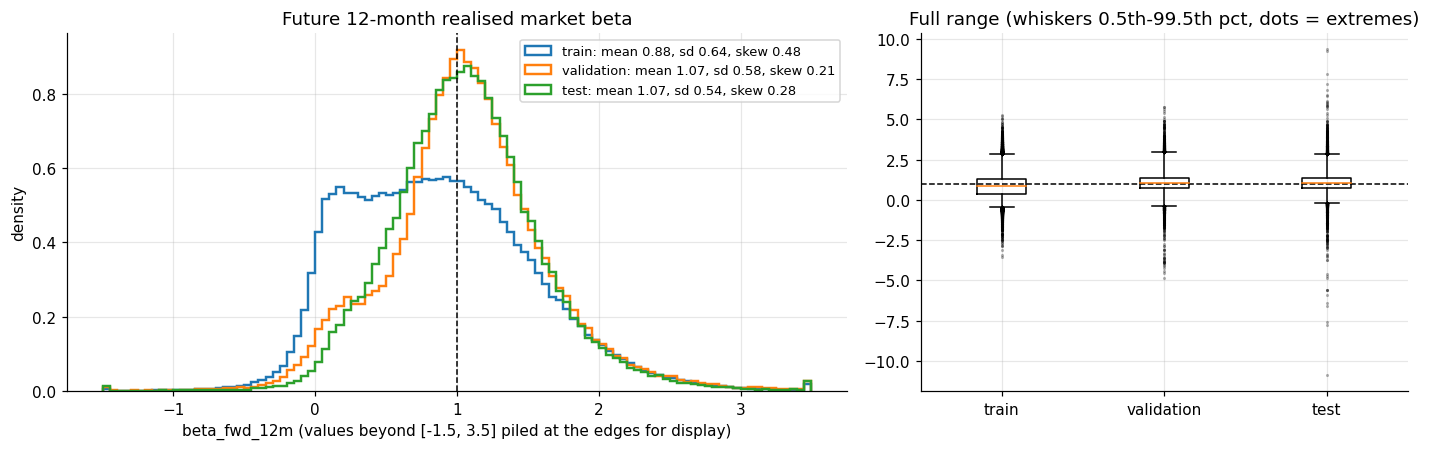

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
bins = np.linspace(-1.5, 3.5, 101)
for s in SPLITS:
    v = sample.loc[sample.split == s, TARGET]
    ax[0].hist(v.clip(-1.5, 3.5), bins=bins, density=True, histtype="step", lw=1.6, color=SPLIT_COLORS[s],
               label=f"{s}: mean {v.mean():.2f}, sd {v.std():.2f}, skew {v.skew():.2f}")
ax[0].axvline(1, color="k", ls="--", lw=1)
ax[0].set_xlabel("beta_fwd_12m (values beyond [-1.5, 3.5] piled at the edges for display)")
ax[0].set_ylabel("density"); ax[0].legend(fontsize=8.5); ax[0].set_title("Future 12-month realised market beta")
ax[1].boxplot([sample.loc[sample.split == s, TARGET] for s in SPLITS], labels=SPLITS, whis=(0.5, 99.5),
              flierprops=dict(marker=".", ms=2, alpha=0.3))
ax[1].axhline(1, color="k", ls="--", lw=1)
ax[1].set_title("Full range (whiskers 0.5th-99.5th pct, dots = extremes)")
plt.tight_layout(); savefig("step1_target_distribution"); plt.show()

In [39]:
tail = pd.DataFrame({s: {
    "n": (v := sample.loc[sample.split == s, TARGET]).size,
    "mean": v.mean(), "median": v.median(), "skew": v.skew(), "excess kurtosis": v.kurt(),
    "share < 0": (v < 0).mean(), "share > 2": (v > 2).mean(), "share > 3": (v > 3).mean(),
    "count |beta| > 5": int((v.abs() > 5).sum()), "min": v.min(), "max": v.max()} for s in SPLITS})
tail.to_csv("results/step1_target_stats.csv")
tail

,train,validation,test
n,"589,239.0000","138,516.0000","170,650.0000"
mean,0.8792,1.0691,1.0693
median,0.8369,1.0579,1.0503
skew,0.4847,0.2111,0.2765
excess kurtosis,0.3747,2.7639,7.2991
share < 0,0.0548,0.0267,0.0119
share > 2,0.0497,0.0528,0.0445
share > 3,0.0030,0.0045,0.0032
count |beta| > 5,4.0000,7.0000,28.0000
min,-3.5741,-4.8790,-10.8554


In [40]:
# Who are the extreme observations? Firm size of |beta| > 4 rows compared with the rest of the sample
ext = sample[TARGET].abs() > 4
print(f"Rows with |beta_fwd_12m| > 4: {ext.sum()} ({ext.mean():.3%})")
print(f"Median market cap: extreme rows ${np.exp(sample.loc[ext, 'log_market_cap'].median())/1e6:,.0f}m "
      f"vs all rows ${np.exp(sample.log_market_cap.median())/1e6:,.0f}m")
print(f"Median trailing idiosyncratic daily vol: extreme {sample.loc[ext, 'idio_vol_daily_12m'].median():.3f} "
      f"vs all {sample.idio_vol_daily_12m.median():.3f}")
sample.loc[ext].groupby("split").size().reindex(SPLITS, fill_value=0).to_frame("n_extreme")

Rows with |beta_fwd_12m| > 4: 212 (0.024%)
Median market cap: extreme rows $225m vs all rows $404m
Median trailing idiosyncratic daily vol: extreme 0.065 vs all 0.026


,n_extreme
split,
train,62
validation,54
test,96


**Discussion of the target distribution.**
- Future beta is centred slightly below 1 in training (mean 0.88) and near 1 in the validation and test years (1.07).
  Median beta rises in step with firm size, which grows from a median of about \$280m to about \$1bn.
- The distribution is **moderately right-skewed** (skew 0.2–0.5). High-beta firms can reach 2.5–3.5, while negative
  betas are uncommon (5.5% of training rows, 1.2% of test rows).
- The tails are **fat, especially in the test period** (excess kurtosis 7.3, range −10.9 to +9.3). The extreme
  values are rare (212 rows with |beta| > 4, 0.02% of the sample). They come disproportionately from the test years
  (96 of the 212) and from smaller, very volatile firms (median cap \$225m vs \$404m; idiosyncratic daily volatility
  2.5 times the sample median). The most extreme cases are micro-caps worth about \$10m. For such stocks, a few very large daily
  moves dominate a 12-month OLS slope, so these labels mostly reflect estimation noise rather than true economic exposure.
- Consequences:
  - squared-error metrics (MSE, RMSE, R²_OOS) will be sensitive to a few rows, so MAE is also reported;
  - by design, **targets are not clipped** for training or scoring.

## Step 2: Classical Rolling-Beta Benchmarks
Before any neural network, we use the supplied historical estimates directly as forecasts of `beta_fwd_12m`
("next year's beta = the beta we measured up to today"):
- `beta_12m`, `beta_24m`, `beta_36m`: rolling OLS betas estimated on 12, 24 and 36 monthly returns;
- `beta_daily_12m`: trailing 12-month daily-return beta. It is a **persistence benchmark**, the same statistic as the target, one year earlier.

Metrics: RMSE, MAE and the Pearson correlation between forecast and realised beta. We also report the mean
forecast error (bias). The best **monthly** benchmark is selected on **validation RMSE only** and then kept fixed.
For context we add two naive references that are *not* candidates for selection: a constant forecast of 1
(the average market beta) and the constant training-sample mean.

In [41]:
def metrics(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    e = yhat - y
    return {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
            "Corr": np.corrcoef(y, yhat)[0, 1] if np.std(yhat) > 0 else np.nan,
            "Bias (mean pred - real)": e.mean(), "N": len(y)}

MONTHLY_BENCH = ["beta_12m", "beta_24m", "beta_36m"]
DAILY_BENCH = "beta_daily_12m"
val = sample[sample.split == "validation"]
test = sample[sample.split == "test"]
train_mean = sample.loc[sample.split == "train", TARGET].mean()

# All benchmarks are scored on identical rows (eligible_core has no missing benchmark values)
assert val[MONTHLY_BENCH + [DAILY_BENCH]].notna().all().all() and test[MONTHLY_BENCH + [DAILY_BENCH]].notna().all().all()

rows = []
for name, part in [("validation", val), ("test", test)]:
    for b in MONTHLY_BENCH + [DAILY_BENCH]:
        rows.append({"split": name, "forecast": b, **metrics(part[TARGET], part[b])})
    rows.append({"split": name, "forecast": "const 1.0 (ref)", **metrics(part[TARGET], np.ones(len(part)))})
    rows.append({"split": name, "forecast": f"train mean {train_mean:.3f} (ref)",
                 **metrics(part[TARGET], np.full(len(part), train_mean))})
bench = pd.DataFrame(rows).set_index(["split", "forecast"])
bench.to_csv("results/step2_benchmarks.csv")
bench

RMSE    MAE    Corr  Bias (mean pred - real)       N
split      forecast                                                                     
validation beta_12m               1.4174 0.9034  0.2622                   0.0632  138516
           beta_24m               0.9667 0.6518  0.3484                   0.0663  138516
           beta_36m               0.7866 0.5479  0.4081                   0.0934  138516
           beta_daily_12m         0.4868 0.3434  0.6177                  -0.0369  138516
           const 1.0 (ref)        0.5806 0.4307     NaN                  -0.0691  138516
           train mean 0.879 (ref) 0.6070 0.4564 -0.0000                  -0.1899  138516
test       beta_12m               1.4390 0.8308  0.2218                   0.0352  170650
           beta_24m               1.0742 0.6747  0.2939                   0.1743  170650
           beta_36m               0.9047 0.5931  0.3549                   0.2018  170650
           beta_daily_12m         0.5300 0.3682  0.5095                  -0.0152  170650
           const 1.0 (ref)        0.5406 0.4035     NaN                  -0.0693  170650
           train mean 0.879 (ref) 0.5688 0.4262  0.0000                  -0.1901  170650

In [42]:
# Select the monthly benchmark on validation RMSE only, then freeze the choice
val_rmse = bench.loc["validation"].loc[MONTHLY_BENCH, "RMSE"]
BEST_BENCH = val_rmse.idxmin()
print("Validation RMSE of monthly benchmarks:", val_rmse.round(4).to_dict())
print(f"==> Selected monthly benchmark (fixed for Step 5): {BEST_BENCH}")

Validation RMSE of monthly benchmarks: {'beta_12m': 1.4174, 'beta_24m': 0.9667, 'beta_36m': 0.7866}
==> Selected monthly benchmark (fixed for Step 5): beta_36m


In [43]:
# Do the rankings persist from validation to test?
rank = pd.DataFrame({f"{s} {m}": bench.loc[s].loc[MONTHLY_BENCH + [DAILY_BENCH], m].rank(ascending=(m != "Corr")).astype(int)
                     for s in ["validation", "test"] for m in ["RMSE", "MAE", "Corr"]})
print("Rank (1 = best) among the four historical-beta forecasts")
rank

Rank (1 = best) among the four historical-beta forecasts


,validation RMSE,validation MAE,validation Corr,test RMSE,test MAE,test Corr
forecast,,,,,,
beta_12m,4,4,4,4,4,4
beta_24m,3,3,3,3,3,3
beta_36m,2,2,2,2,2,2
beta_daily_12m,1,1,1,1,1,1


### 2.1 Responsiveness vs noise
A shorter window reacts faster to a change in a firm's true beta, but it averages fewer observations, so it is noisier.
We measure both sides on the validation + test rows:
- **Dispersion.** The cross-sectional standard deviation of the forecast compared with that of the realised beta. Too much dispersion signals noise.
- **Month-to-month movement.** The average |change| in a firm's forecast from one month to the next (consecutive months only).
- **Slope of the realised on the forecast beta.** Regress realised on forecast. A slope of 1 means well calibrated; a slope below 1 means
  the forecast is too extreme and should be shrunk towards the mean (errors-in-variables attenuation).

In [44]:
vt = sample[sample.split.isin(["validation", "test"])].sort_values(["permno", "date"])
consec = (vt.groupby("permno").date.diff() <= pd.Timedelta(days=31))
resp = []
for b in MONTHLY_BENCH + [DAILY_BENCH]:
    d = vt.groupby("permno")[b].diff().abs()[consec]
    slope = np.polyfit(vt[b], vt[TARGET], 1)[0]
    resp.append({"forecast": b, "sd of forecast": vt[b].std(), "sd of realised beta": vt[TARGET].std(),
                 "mean |monthly change|": d.mean(), "median |monthly change|": d.median(),
                 "slope realised-on-forecast": slope, "1st-99th pct range": vt[b].quantile(.99) - vt[b].quantile(.01)})
resp_tab = pd.DataFrame(resp).set_index("forecast")
resp_tab.to_csv("results/step2_responsiveness.csv")
resp_tab

,sd of forecast,sd of realised beta,mean |monthly change|,median |monthly change|,slope realised-on-forecast,1st-99th pct range
forecast,,,,,,
beta_12m,1.4565,0.5546,0.3118,0.1443,0.0915,7.5628
beta_24m,1.0492,0.5546,0.1501,0.0675,0.1675,5.5783
beta_36m,0.8727,0.5546,0.0924,0.0420,0.2387,4.4519
beta_daily_12m,0.5319,0.5546,0.0721,0.0403,0.5831,2.5846


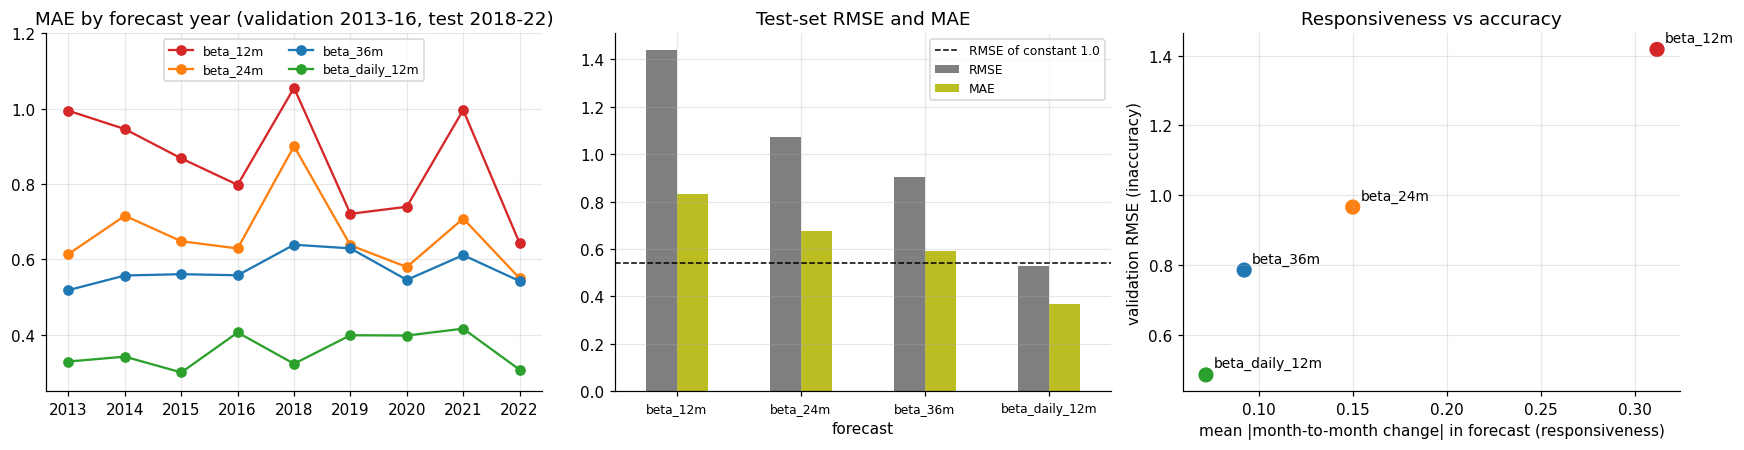

In [45]:
# Error by forecast year (validation + test), showing stability over time
yr = []
for (y_, s), g in vt.groupby(["year", "split"]):
    for b in MONTHLY_BENCH + [DAILY_BENCH]:
        yr.append({"year": y_, "split": s, "forecast": b, "RMSE": np.sqrt(((g[b] - g[TARGET]) ** 2).mean()),
                   "MAE": (g[b] - g[TARGET]).abs().mean()})
yr = pd.DataFrame(yr)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cols_b = {"beta_12m": "#d62728", "beta_24m": "#ff7f0e", "beta_36m": "#1f77b4", "beta_daily_12m": "#2ca02c"}
for b, c in cols_b.items():
    g = yr[yr.forecast == b]
    ax[0].plot(g.year.astype(str), g.MAE, marker="o", color=c, label=b)
ax[0].set_title("MAE by forecast year (validation 2013-16, test 2018-22)")
ax[0].legend(fontsize=8, ncol=2, loc="upper center"); ax[0].set_ylim(0.25, 1.2)
m = bench.xs("test")[["RMSE", "MAE"]].iloc[:4]
m.plot.bar(ax=ax[1], color=["#7f7f7f", "#bcbd22"], rot=0); ax[1].set_title("Test-set RMSE and MAE")
ax[1].axhline(bench.loc[("test", "const 1.0 (ref)"), "RMSE"], color="k", ls="--", lw=1, label="RMSE of constant 1.0")
ax[1].legend(fontsize=8)
ax[1].tick_params(axis="x", labelsize=8)
ax[2].scatter(resp_tab["mean |monthly change|"], bench.xs("validation").loc[resp_tab.index, "RMSE"],
              s=80, c=[cols_b[b] for b in resp_tab.index])
for b in resp_tab.index:
    ax[2].annotate(b, (resp_tab.loc[b, "mean |monthly change|"], bench.xs("validation").loc[b, "RMSE"]),
                   xytext=(5, 5), textcoords="offset points", fontsize=9)
ax[2].set_xlabel("mean |month-to-month change| in forecast (responsiveness)")
ax[2].set_ylabel("validation RMSE (inaccuracy)"); ax[2].set_title("Responsiveness vs accuracy")
plt.tight_layout(); savefig("step2_benchmarks"); plt.show()

In [46]:
# How much of the squared error comes from the few extreme labels? (diagnostic only; scoring is never clipped)
ext_t = test[TARGET].abs() > 4
for b in MONTHLY_BENCH + [DAILY_BENCH]:
    se = (test[b] - test[TARGET]) ** 2
    print(f"{b:>15}: test RMSE {np.sqrt(se.mean()):.4f}; share of SSE from |beta_fwd|>4 rows "
          f"({ext_t.sum()} rows, {ext_t.mean():.2%}): {se[ext_t].sum()/se.sum():.1%}; "
          f"RMSE without them {np.sqrt(se[~ext_t].mean()):.4f}")

       beta_12m: test RMSE 1.4390; share of SSE from |beta_fwd|>4 rows (96 rows, 0.06%): 0.5%; RMSE without them 1.4358
       beta_24m: test RMSE 1.0742; share of SSE from |beta_fwd|>4 rows (96 rows, 0.06%): 0.8%; RMSE without them 1.0703
       beta_36m: test RMSE 0.9047; share of SSE from |beta_fwd|>4 rows (96 rows, 0.06%): 1.1%; RMSE without them 0.9001
 beta_daily_12m: test RMSE 0.5300; share of SSE from |beta_fwd|>4 rows (96 rows, 0.06%): 3.5%; RMSE without them 0.5208


### 2.2 Answers
**Which window is best on validation, and does the ranking persist?**
`beta_36m` has the lowest validation RMSE (0.787, against 0.967 for 24m and 1.417 for 12m), so it is the fixed benchmark
for Step 5. The ranking 36m < 24m < 12m is identical on test (0.905 / 1.074 / 1.439) and holds for MAE and correlation too.
The daily persistence beta beats all three by a wide margin (test RMSE 0.530, correlation 0.51).

**Are shorter windows more responsive but noisier?** Yes, very clearly:
- `beta_12m` changes by 0.31 per month on average, against 0.09 for `beta_36m`, so it reacts faster.
- Its cross-sectional dispersion (sd 1.46) is 2.6 times that of realised beta (0.55).
- The slope of realised on forecast beta is only 0.09, against 0.24 for 36m and 0.58 for the daily beta. Most of
  the variation in the 12-month estimate is estimation noise, which averages out as the window lengthens.
- With 12 monthly observations the extra responsiveness buys nothing. The added noise swamps any gain from tracking
  a changing beta faster. Its year-by-year error is also the least stable (see 2018 and 2021).
- In my earlier CAPM beta study I found the same pattern in-sample: the 12-month beta changed about 3 times as much from year to year as the
  36-month beta (mean |change| 0.71 vs 0.25), and I concluded that neither window was simply better. Scoring the windows against a *realised
  future* beta settles that trade-off: the longer window is clearly more accurate.

**How difficult is the problem?** Hard.
- Every monthly rolling beta is *worse than the naive forecast β = 1* (test RMSE 0.54): the raw estimates are too noisy
  and, in the test years, biased upwards (+0.20 for 36m).
- Even the best historical estimate, the daily beta, cuts RMSE only about 2% below the constant 1.0 on test (0.530 vs 0.541).
  It reaches a correlation of 0.51 with the realised beta, so roughly three quarters of the cross-sectional
  variance is unexplained.
- The extreme labels are not the reason: they account for only 1–4% of the squared error.
- The main reasons are (i) estimation noise and mean reversion in historical betas and (ii) noise in the realised
  target itself. This points to what a better forecast needs: shrink noisy estimates, lean on the precise
  daily beta, and adjust the level using characteristics such as size.

## Step 3: Predictor Selection and Leakage-Free Preprocessing

### 3.1 Predictor groups and their economic rationale
| Group | Variables | Why it should help forecast future beta |
|---|---|---|
| **Historical risk** | `beta_12m`, `beta_24m`, `beta_36m`, `beta_daily_12m`, `vol_12m`, `idio_vol_daily_12m`, `market_vol_12m` | Beta is persistent, so past betas are the direct starting point. Having several windows and frequencies lets the model *combine* and *shrink* them: the daily beta is precise and the monthly betas are robust to thin trading. Total and idiosyncratic volatility show how noisy the historical estimates are, so how much they should be shrunk. They also relate to leverage and distress. Market volatility captures the market regime, since betas behave differently in turbulent markets. |
| **Returns & size** | `ret`, `market_ret`, `mom_12_2`, `ret_3m`, `log_market_cap` | Size is linked to beta through business maturity and diversification, and it corrects the thin-trading bias that pushes small firms' daily betas towards 0 (Step 0.8). Past returns change a firm's leverage: after a price fall, equity is a smaller share of the firm, so equity beta rises. They also mark growth or momentum stocks, whose risk profile is changing. The market return describes the current market state. |
| **Industry** | one-hot `industry` (FF10) | Industries differ in the cyclicality of their cash flows and in operating leverage. Utilities and staples have low betas; energy and tech have high betas (Step 0.7). Industry is also a stable anchor to shrink noisy firm-level estimates towards, like a Bayesian prior. |

### 3.2 Preprocessing rules (all fitted on the **training** split only)
1. **Missing values:** each numeric predictor is filled with its training median, and industry is filled with "Unknown". The eligible sample has
   no missing predictors (Step 0.4), so the imputer is kept only as a safeguard. We show below that it changes 0 values.
2. **Winsorisation (predictors only):** firm-level predictors are clipped at their **training 1st and 99th percentiles**. This limits the
   influence of extreme values such as `beta_12m` = 36 or `ret_3m` = +4,140% on the standardised inputs and on the gradients.
   `market_ret` and `market_vol_12m` are **not** clipped: they are the same for every firm in a month, have no outliers
   (kurtosis < 1), and clipping them would only remove information about crisis months. **Targets and benchmark forecasts are never clipped.**
3. **Standardisation:** subtract the training mean and divide by the training standard deviation (computed after clipping).
4. **Industry:** one-hot encoding fitted on the training categories. `Unknown` never occurs in training, so it maps to all zeros
   (`handle_unknown="ignore"`), meaning "no industry information".
5. **Never inputs:** identifiers, future betas and returns, target dates, observation counts, coverage, split labels and eligibility flags.

In [47]:
from sklearn.preprocessing import OneHotEncoder

MARKET_LEVEL = ["market_ret", "market_vol_12m"]   # identical across firms within a month -> not clipped

class BetaPreprocessor:
    """Impute -> clip (1st/99th pct) -> standardise numeric predictors; one-hot encode industry.
    Every statistic is estimated in .fit() on the training rows only; .transform() only applies them."""
    def __init__(self, num_cols, cat_cols, clip_q=(0.01, 0.99), no_clip=()):
        self.num_cols, self.cat_cols, self.clip_q, self.no_clip = list(num_cols), list(cat_cols), clip_q, set(no_clip)

    def fit(self, train_df):
        X = train_df[self.num_cols]
        self.median_ = X.median()
        Xf = X.fillna(self.median_)
        self.lo_ = Xf.quantile(self.clip_q[0]); self.hi_ = Xf.quantile(self.clip_q[1])
        for c in self.no_clip:
            self.lo_[c], self.hi_[c] = -np.inf, np.inf
        Xc = Xf.clip(self.lo_, self.hi_, axis=1)
        self.mean_, self.std_ = Xc.mean(), Xc.std(ddof=0)
        self.ohe_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
        self.ohe_.fit(train_df[self.cat_cols].fillna("Unknown"))
        self.feature_names_ = self.num_cols + list(self.ohe_.get_feature_names_out(self.cat_cols))
        return self

    def transform(self, d):
        X = d[self.num_cols]
        self.last_imputed_ = int(X.isna().sum().sum())
        Xc = X.fillna(self.median_).clip(self.lo_, self.hi_, axis=1)
        self.last_clip_share_ = ((X < self.lo_) | (X > self.hi_)).mean()
        Z = ((Xc - self.mean_) / self.std_).to_numpy(np.float32)
        return np.hstack([Z, self.ohe_.transform(d[self.cat_cols].fillna("Unknown"))]).astype(np.float32)

train_df = sample[sample.split == "train"]
val_df, test_df = sample[sample.split == "validation"], sample[sample.split == "test"]

prep = BetaPreprocessor(FEATURES_NUM, FEATURES_CAT, no_clip=MARKET_LEVEL).fit(train_df)
X_train = prep.transform(train_df); imp_tr, clip_tr = prep.last_imputed_, prep.last_clip_share_
X_val = prep.transform(val_df);     imp_va, clip_va = prep.last_imputed_, prep.last_clip_share_
X_test = prep.transform(test_df);   imp_te, clip_te = prep.last_imputed_, prep.last_clip_share_
y_train, y_val, y_test = (d[TARGET].to_numpy(np.float32) for d in (train_df, val_df, test_df))
FEATURE_NAMES = prep.feature_names_
P = X_train.shape[1]
print(f"Input dimension p = {P}  (12 numeric + {P - 12} industry dummies)")
print("Industry categories learned from training:", list(prep.ohe_.categories_[0]))
print(f"Shapes: train {X_train.shape}, validation {X_val.shape}, test {X_test.shape}")
print(f"Values imputed: train {imp_tr}, validation {imp_va}, test {imp_te}")

Input dimension p = 22  (12 numeric + 10 industry dummies)
Industry categories learned from training: ['Durbl', 'Enrgy', 'HiTec', 'Hlth', 'Manuf', 'NoDur', 'Other', 'Shops', 'Telcm', 'Utils']
Shapes: train (589239, 22), validation (138516, 22), test (170650, 22)
Values imputed: train 0, validation 0, test 0


In [48]:
# Fitted preprocessing parameters (all estimated on the training split) and the share of rows clipped in each split
params = pd.DataFrame({"group": [next(g for g, v in GROUPS.items() if c in v) for c in FEATURES_NUM],
                       "train median (imputation)": prep.median_, "clip low (train p1)": prep.lo_,
                       "clip high (train p99)": prep.hi_, "train mean (after clip)": prep.mean_,
                       "train sd (after clip)": prep.std_,
                       "clipped % train": 100 * clip_tr, "clipped % validation": 100 * clip_va,
                       "clipped % test": 100 * clip_te}, index=FEATURES_NUM)
params.to_csv("results/step3_preprocessing_params.csv")
params

,group,train median (imputation),clip low (train p1),clip high (train p99),train mean (after clip),train sd (after clip),clipped % train,clipped % validation,clipped % test
vol_12m,risk,0.1181,0.0294,0.5720,0.1452,0.0988,2.0002,1.9081,1.7562
market_vol_12m,risk,0.0470,-inf,inf,0.0458,0.0176,0.0000,0.0000,0.0000
beta_12m,risk,0.9398,-1.8862,5.9453,1.1380,1.3252,2.0002,2.2445,2.1149
beta_24m,risk,0.9614,-0.7766,4.9003,1.1521,1.0493,2.0002,2.3643,2.4155
beta_36m,risk,0.9566,-0.4495,4.4200,1.1355,0.9375,2.0002,1.7269,1.9801
beta_daily_12m,risk,0.7974,-0.2694,2.5819,0.8541,0.6191,2.0002,1.2266,1.2763
idio_vol_daily_12m,risk,0.0280,0.0081,0.1178,0.0341,0.0215,2.0002,4.0436,1.8230
ret,returns_and_size,0.0016,-0.3881,0.6000,0.0102,0.1530,1.9990,0.7631,2.0000
market_ret,returns_and_size,0.0109,-inf,inf,0.0042,0.0487,0.0000,0.0000,0.0000
log_market_cap,returns_and_size,19.4484,15.2647,24.8235,19.5411,2.0916,2.0002,2.4199,3.8746


In [49]:
# Sanity checks on the transformed data
Ztr = pd.DataFrame(X_train[:, :12], columns=FEATURES_NUM)
chk3 = pd.DataFrame({"train mean": Ztr.mean(), "train sd": Ztr.std(ddof=0),
                     "val mean": X_val[:, :12].mean(0), "test mean": X_test[:, :12].mean(0),
                     "raw kurtosis (train)": train_df[FEATURES_NUM].kurt().values,
                     "kurtosis after clip (train)": Ztr.kurt().values})
assert np.allclose(chk3["train mean"], 0, atol=1e-4) and np.allclose(chk3["train sd"], 1, atol=1e-3)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()
chk3

,train mean,train sd,val mean,test mean,raw kurtosis (train),kurtosis after clip (train)
vol_12m,-0.0000,1.0000,-0.4213,-0.0615,65.3784,4.3202
market_vol_12m,-0.0000,1.0000,-0.9096,0.1037,-0.4202,-0.4202
beta_12m,0.0000,1.0000,0.0005,-0.0186,15.4297,1.8787
beta_24m,-0.0000,1.0000,-0.0052,0.0922,7.3829,1.6095
beta_36m,-0.0000,1.0000,0.0354,0.1491,4.9814,1.4105
beta_daily_12m,0.0000,1.0000,0.2882,0.3232,0.5393,-0.2265
idio_vol_daily_12m,-0.0000,1.0000,-0.5054,-0.1438,109.4751,2.6290
ret,-0.0000,1.0000,0.0095,-0.0349,151.5707,2.6989
market_ret,0.0000,1.0000,0.1272,0.0707,0.5377,0.5377
log_market_cap,0.0000,1.0000,0.4266,0.5449,-0.1998,-0.4133


In [50]:
# Industry dummies: each row has exactly one 1, except 'Unknown' rows (all zeros)
D_te = X_test[:, 12:]
print("Row sums of industry dummies (test):", pd.Series(D_te.sum(1)).value_counts().to_dict(),
      "| Unknown rows in test:", int((test_df.industry == "Unknown").sum()))
assert ((D_te.sum(1) == 0) == (test_df.industry == "Unknown").to_numpy()).all()

# Leakage guard: the model inputs are exactly the 12 numeric predictors + industry dummies
assert FEATURE_NAMES[:12] == FEATURES_NUM and all(f.startswith("industry_") for f in FEATURE_NAMES[12:])
assert not set(FEATURE_NAMES) & set(forbidden)

# Column indices for each predictor group (used by the permutation importance in Step 7)
GROUP_IDX = {"historical risk": [FEATURE_NAMES.index(c) for c in GROUPS["risk"]],
             "returns & size": [FEATURE_NAMES.index(c) for c in GROUPS["returns_and_size"]],
             "industry": list(range(12, P))}
print({g: [FEATURE_NAMES[i] for i in idx] for g, idx in GROUP_IDX.items()})

Row sums of industry dummies (test): {1.0: 170501, 0.0: 149} | Unknown rows in test: 149
{'historical risk': ['vol_12m', 'market_vol_12m', 'beta_12m', 'beta_24m', 'beta_36m', 'beta_daily_12m', 'idio_vol_daily_12m'], 'returns & size': ['ret', 'market_ret', 'log_market_cap', 'mom_12_2', 'ret_3m'], 'industry': ['industry_Durbl', 'industry_Enrgy', 'industry_HiTec', 'industry_Hlth', 'industry_Manuf', 'industry_NoDur', 'industry_Other', 'industry_Shops', 'industry_Telcm', 'industry_Utils']}


**Observations on preprocessing.**
- p = 22: 12 standardised numeric predictors plus 10 industry dummies. `Unknown` gets no column; its 149 test and 5 validation rows are all zeros.
- The imputer changed 0 values in every split, because the eligibility filter already requires complete histories.
- Clipping affects about 2% of training rows per firm-level variable by construction (1% in each tail). It cuts kurtosis sharply,
  e.g. `ret_3m` from 616 to 3.5 and `ret` from 152 to 2.7, without discarding any rows.
- Validation and test rows are clipped at the *training* thresholds, so their clipped shares differ. The largest difference is
  `log_market_cap` in test, clipped in 3.9% of rows, almost all at the top: firms above the training p99 of about \$60bn. Mega-caps grew
  after 2011. Those firms' future beta averages 0.96, so treating them as "\$60bn firms" loses little information.
- The shifts in standardised means reflect the regime differences described in Step 0:
  - validation `market_vol_12m` is 0.9 sd below the training mean, because 2013–16 was calm;
  - validation and test firms are larger (+0.4 to +0.5 sd) and have higher trailing daily betas (+0.3 sd).
  The network must extrapolate somewhat, which is a realistic feature of forecasting over time.

## Step 4: Neural Market-Beta Model (PyTorch MLP)

**Model.** A feed-forward multilayer perceptron maps the $p=22$ preprocessed inputs to one forecast of future beta:
$p \rightarrow 32 \rightarrow 16 \rightarrow 1$, with ReLU hidden activations, a linear output, and dropout of 0.05 after each hidden layer.

**Training.**
- Loss and optimiser: MSE loss with Adam.
- Minibatches: 512 rows, reshuffled every epoch. Shuffling happens only *within* the training period.
- Epochs and early stopping: at most 100 epochs. Validation MSE is recorded after every epoch. Training stops after 10 epochs without improvement,
  and the weights from the **best validation epoch** are restored.
- Seeds are fixed for reproducibility.

**Model selection (validation only).** A deliberately small grid of four configurations:
{one hidden layer (32), two hidden layers (32→16)} × learning rate {1e-3, 3e-4}. The configuration with the lowest
validation MSE is selected. The test set is not touched in this step.

In [51]:
import copy, time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, BatchSampler, RandomSampler

torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() // 2))
DEVICE = torch.device("cpu")    # a small MLP trains fastest (and deterministically) on the CPU
BATCH, MAX_EPOCHS, PATIENCE, DROPOUT = 512, 100, 10, 0.05
print("torch", torch.__version__, "| device", DEVICE, "| threads", torch.get_num_threads())

def make_mlp(p, hidden, out_dim=1, dropout=DROPOUT):
    layers, d = [], p
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    layers.append(nn.Linear(d, out_dim))          # linear output layer
    return nn.Sequential(*layers)

@torch.no_grad()
def predict(model, X, batch=65536):
    model.eval()
    X = torch.as_tensor(X)
    return torch.cat([model(X[i:i + batch]) for i in range(0, len(X), batch)]).numpy()

def train_mlp(Xtr, Ytr, Xva, Yva, hidden, lr, seed=SEED, max_epochs=MAX_EPOCHS, patience=PATIENCE,
              batch=BATCH, verbose=False):
    """Adam + MSE; early stopping on validation MSE; returns the model restored to its best validation epoch.
    Y can be (n,) or (n, k). For k > 1 the loss is the mean MSE across the k outputs."""
    torch.manual_seed(seed); np.random.seed(seed)
    Ytr, Yva = np.asarray(Ytr, np.float32).reshape(len(Ytr), -1), np.asarray(Yva, np.float32).reshape(len(Yva), -1)
    model = make_mlp(Xtr.shape[1], hidden, Ytr.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ds = TensorDataset(torch.as_tensor(Xtr), torch.as_tensor(Ytr))
    sampler = BatchSampler(RandomSampler(ds, generator=torch.Generator().manual_seed(seed)), batch, drop_last=False)
    loader = DataLoader(ds, sampler=sampler, batch_size=None)   # fetches whole minibatches at once (fast)
    best, best_state, best_epoch, wait, hist = np.inf, None, 0, 0, []
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train(); run, n = 0.0, 0
        for xb, yb in loader:
            opt.zero_grad()
            loss = nn.functional.mse_loss(model(xb), yb)
            loss.backward(); opt.step()
            run += loss.item() * len(xb); n += len(xb)
        tr_mse = float(((predict(model, Xtr) - Ytr) ** 2).mean())    # full training MSE, dropout off
        va_mse = float(((predict(model, Xva) - Yva) ** 2).mean())
        hist.append({"epoch": epoch, "train_loss_batches": run / n, "train_mse": tr_mse, "val_mse": va_mse})
        if va_mse < best - 1e-6:
            best, best_epoch, wait, best_state = va_mse, epoch, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
        if verbose and epoch % 10 == 0:
            print(f"  epoch {epoch:3d}  train {tr_mse:.5f}  val {va_mse:.5f}")
        if wait >= patience:
            break
    model.load_state_dict(best_state)                 # restore best validation checkpoint
    return model, pd.DataFrame(hist), {"best_epoch": best_epoch, "epochs_run": epoch, "best_val_mse": best,
                                       "train_mse_at_best": hist[best_epoch - 1]["train_mse"],
                                       "seconds": time.time() - t0}

torch 2.6.0 | device cpu | threads 7


In [52]:
GRID = [{"name": "1 layer (32), lr 1e-3", "hidden": [32], "lr": 1e-3},
        {"name": "1 layer (32), lr 3e-4", "hidden": [32], "lr": 3e-4},
        {"name": "2 layers (32-16), lr 1e-3", "hidden": [32, 16], "lr": 1e-3},
        {"name": "2 layers (32-16), lr 3e-4", "hidden": [32, 16], "lr": 3e-4}]
runs = {}
for cfg in GRID:
    model, hist, info = train_mlp(X_train, y_train, X_val, y_val, cfg["hidden"], cfg["lr"])
    runs[cfg["name"]] = {"cfg": cfg, "model": model, "hist": hist, **info}
    print(f"{cfg['name']:<28} best epoch {info['best_epoch']:3d} / run {info['epochs_run']:3d} | "
          f"val MSE {info['best_val_mse']:.5f} (RMSE {np.sqrt(info['best_val_mse']):.4f}) | "
          f"train MSE {info['train_mse_at_best']:.5f} | {info['seconds']:.0f}s")

1 layer (32), lr 1e-3        best epoch   8 / run  18 | val MSE 0.18156 (RMSE 0.4261) | train MSE 0.15074 | 7s


1 layer (32), lr 3e-4        best epoch  11 / run  21 | val MSE 0.18085 (RMSE 0.4253) | train MSE 0.15221 | 10s


2 layers (32-16), lr 1e-3    best epoch   8 / run  18 | val MSE 0.17971 (RMSE 0.4239) | train MSE 0.14529 | 11s


2 layers (32-16), lr 3e-4    best epoch   8 / run  18 | val MSE 0.18244 (RMSE 0.4271) | train MSE 0.14803 | 10s


In [53]:
grid_tab = pd.DataFrame([{"config": k, "hidden layers": str(v["cfg"]["hidden"]), "learning rate": v["cfg"]["lr"],
                          "parameters": sum(p.numel() for p in v["model"].parameters()),
                          "best epoch": v["best_epoch"], "epochs run": v["epochs_run"],
                          "train MSE @best": v["train_mse_at_best"], "val MSE @best": v["best_val_mse"],
                          "val RMSE @best": np.sqrt(v["best_val_mse"])} for k, v in runs.items()]).set_index("config")
BEST_CFG = grid_tab["val MSE @best"].idxmin()
nn_model = runs[BEST_CFG]["model"]
SEL = runs[BEST_CFG]["cfg"]
grid_tab.to_csv("results/step4_grid.csv")
print(f"==> Selected on validation MSE: {BEST_CFG}")
print(f"    For reference, validation RMSE of beta_daily_12m = {bench.loc[('validation', 'beta_daily_12m'), 'RMSE']:.4f}, "
      f"{BEST_BENCH} = {bench.loc[('validation', BEST_BENCH), 'RMSE']:.4f}")
grid_tab

==> Selected on validation MSE: 2 layers (32-16), lr 1e-3
    For reference, validation RMSE of beta_daily_12m = 0.4868, beta_36m = 0.7866


,hidden layers,learning rate,parameters,best epoch,epochs run,train MSE @best,val MSE @best,val RMSE @best
config,,,,,,,,
"1 layer (32), lr 1e-3",[32],0.0010,769,8,18,0.1507,0.1816,0.4261
"1 layer (32), lr 3e-4",[32],0.0003,769,11,21,0.1522,0.1809,0.4253
"2 layers (32-16), lr 1e-3","[32, 16]",0.0010,1281,8,18,0.1453,0.1797,0.4239
"2 layers (32-16), lr 3e-4","[32, 16]",0.0003,1281,8,18,0.1480,0.1824,0.4271


In [54]:
# Robustness of the selection to the random seed (validation data only; test data is not used).
# Each configuration is retrained with two further seeds. This checks whether the differences between configurations exceed
# the run-to-run noise from weight initialisation and minibatch order. The selection rule itself (seed 42) is unchanged.
seed_rows = []
for cfg in GRID:
    for sd in (1, 2):
        _, _, inf_ = train_mlp(X_train, y_train, X_val, y_val, cfg["hidden"], cfg["lr"], seed=sd)
        seed_rows.append({"config": cfg["name"], "seed": sd, "val MSE": inf_["best_val_mse"]})
    seed_rows.append({"config": cfg["name"], "seed": SEED, "val MSE": runs[cfg["name"]]["best_val_mse"]})
seed_tab = pd.DataFrame(seed_rows).groupby("config")["val MSE"].agg(["mean", "std", "min", "max"]).reindex(grid_tab.index)
seed_tab.to_csv("results/step4_seed_robustness.csv")
print("Validation MSE across 3 seeds (42, 1, 2)")
seed_tab

Validation MSE across 3 seeds (42, 1, 2)


,mean,std,min,max
config,,,,
"1 layer (32), lr 1e-3",0.1817,0.0008,0.1809,0.1826
"1 layer (32), lr 3e-4",0.1814,0.0007,0.1809,0.1822
"2 layers (32-16), lr 1e-3",0.1792,0.0024,0.1766,0.1813
"2 layers (32-16), lr 3e-4",0.1806,0.0017,0.1790,0.1824


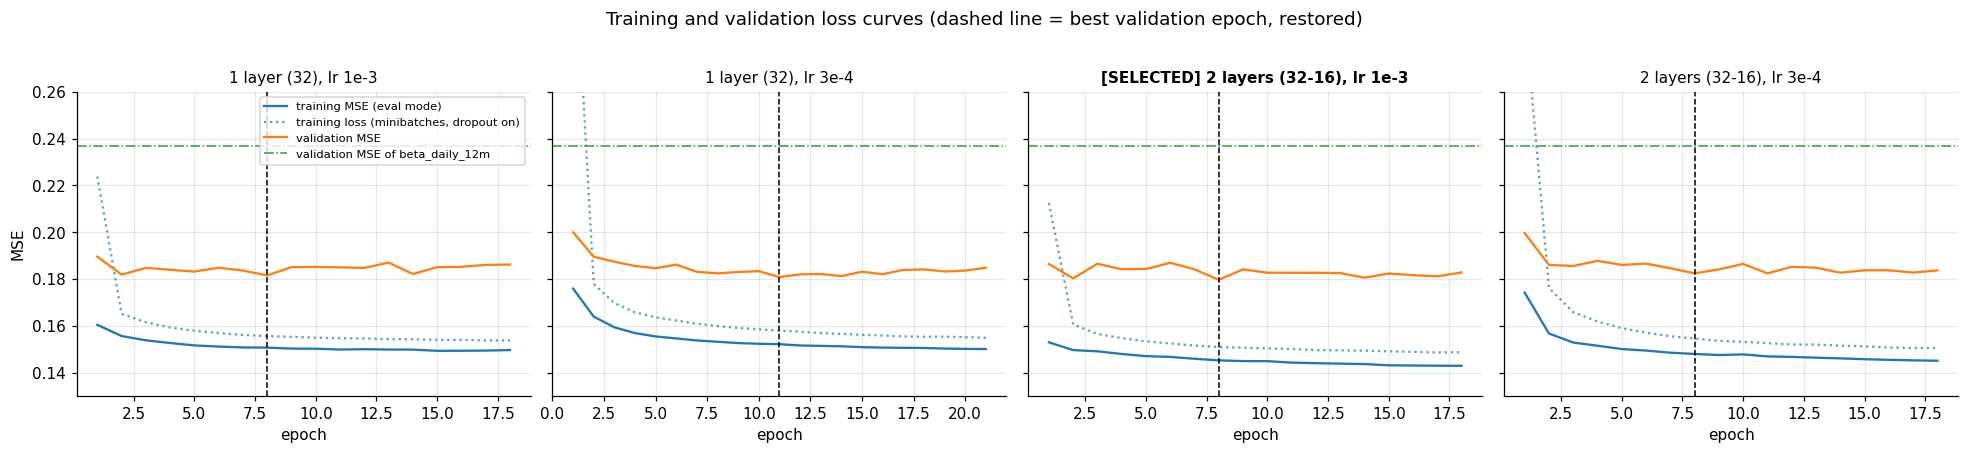

In [55]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (k, v) in zip(axes, runs.items()):
    h = v["hist"]
    ax.plot(h.epoch, h.train_mse, label="training MSE (eval mode)", color="#1f77b4")
    ax.plot(h.epoch, h.train_loss_batches, label="training loss (minibatches, dropout on)", color="#1f77b4", ls=":", alpha=0.7)
    ax.plot(h.epoch, h.val_mse, label="validation MSE", color="#ff7f0e")
    ax.axvline(v["best_epoch"], color="k", ls="--", lw=1)
    ax.axhline(bench.loc[("validation", "beta_daily_12m"), "RMSE"] ** 2, color="#2ca02c", lw=1, ls="-.",
               label="validation MSE of beta_daily_12m")
    ax.set_title(("[SELECTED] " if k == BEST_CFG else "") + k, fontsize=10, fontweight="bold" if k == BEST_CFG else None)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("MSE"); axes[0].legend(fontsize=7.5, loc="upper right")
axes[0].set_ylim(0.13, 0.26)
plt.suptitle("Training and validation loss curves (dashed line = best validation epoch, restored)", y=1.02)
plt.tight_layout(); savefig("step4_loss_curves"); plt.show()
pd.concat({k: v["hist"] for k, v in runs.items()}).to_csv("results/step4_loss_history.csv")

In [56]:
# Overfitting diagnostics for the selected model
h = runs[BEST_CFG]["hist"]; be = runs[BEST_CFG]["best_epoch"]
print(f"Selected: {BEST_CFG}; architecture: p={P} -> {' -> '.join(map(str, SEL['hidden']))} -> 1, ReLU, dropout {DROPOUT}, "
      f"Adam lr {SEL['lr']}, batch {BATCH}, early-stopping patience {PATIENCE}")
print(nn_model)
print(f"Best epoch {be}: train MSE {h.train_mse[be-1]:.5f}, validation MSE {h.val_mse[be-1]:.5f} "
      f"(gap {h.val_mse[be-1] - h.train_mse[be-1]:+.5f})")
print(f"Last epoch {len(h)}: train MSE {h.train_mse.iloc[-1]:.5f}, validation MSE {h.val_mse.iloc[-1]:.5f}")
print(f"Train MSE improvement from best epoch to last: {h.train_mse[be-1] - h.train_mse.iloc[-1]:+.5f}; "
      f"validation change: {h.val_mse.iloc[-1] - h.val_mse[be-1]:+.5f}")

Selected: 2 layers (32-16), lr 1e-3; architecture: p=22 -> 32 -> 16 -> 1, ReLU, dropout 0.05, Adam lr 0.001, batch 512, early-stopping patience 10
Sequential(
  (0): Linear(in_features=22, out_features=32, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.05, inplace=False)
  (3): Linear(in_features=32, out_features=16, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.05, inplace=False)
  (6): Linear(in_features=16, out_features=1, bias=True)
)
Best epoch 8: train MSE 0.14529, validation MSE 0.17971 (gap +0.03441)
Last epoch 18: train MSE 0.14298, validation MSE 0.18283
Train MSE improvement from best epoch to last: +0.00232; validation change: +0.00312


In [57]:
# Is the train/validation gap overfitting, or a difference between the periods? Compare with benchmarks that have NO fitted parameters.
gap = pd.DataFrame({
    "train MSE": [((predict(nn_model, X_train).ravel() - y_train) ** 2).mean(),
                  ((train_df.beta_daily_12m - train_df[TARGET]) ** 2).mean(), ((1 - train_df[TARGET]) ** 2).mean()],
    "validation MSE": [runs[BEST_CFG]["best_val_mse"],
                       ((val_df.beta_daily_12m - val_df[TARGET]) ** 2).mean(), ((1 - val_df[TARGET]) ** 2).mean()]},
    index=["selected MLP", "beta_daily_12m (no fitting)", "constant 1.0 (no fitting)"])
gap["val / train"] = gap["validation MSE"] / gap["train MSE"]
gap["R2 train (1 - MSE/var)"] = 1 - gap["train MSE"] / train_df[TARGET].var(ddof=0)
gap["R2 validation (1 - MSE/var)"] = 1 - gap["validation MSE"] / val_df[TARGET].var(ddof=0)
gap

,train MSE,validation MSE,val / train,R2 train (1 - MSE/var),R2 validation (1 - MSE/var)
selected MLP,0.1453,0.1797,1.2368,0.6484,0.4593
beta_daily_12m (no fitting),0.2444,0.2370,0.9698,0.4088,0.2869
constant 1.0 (no fitting),0.4279,0.3371,0.7879,-0.0353,-0.0144


**Selected model and overfitting assessment.**
- **Selected:** two hidden layers, 22 → 32 → 16 → 1 (1,281 parameters). ReLU, dropout 0.05, Adam with learning rate 1e-3, batch size 512.
  Best validation epoch 8 (restored); training stopped at epoch 18. Validation RMSE is 0.424, against 0.487 for `beta_daily_12m` and 0.787 for `beta_36m`.
- **Robustness:** the four configurations differ by at most 0.003 in validation MSE, which is the same size as the run-to-run noise across
  seeds (sd 0.001–0.002). The choice matters little. The two-layer model with learning rate 1e-3 also has the best *average* across three seeds, so the selection is not a lucky draw.
- **Overfitting: mild within training, plus some loss of generalisation to a new period.**
  - *Within-sample overfitting is small and handled by early stopping.* After epoch 8 training MSE falls only another 0.002, while validation
    MSE drifts up by 0.003. This is the classic onset of overfitting, and restoring the best checkpoint removes it. The model is tiny
    (1,281 parameters for 589k rows) and learns most of what it can in 1–2 epochs, so it cannot memorise individual observations.
  - *The gap between periods is real.* Validation MSE is 24% above training MSE (0.180 vs 0.145). The parameter-free daily-beta forecast does *not* show
    this: its validation MSE is 3% *below* its training MSE. So part of the MLP's in-sample fit comes from relationships specific to 1998–2011
    (e.g. the thin-trading pattern among the many small firms of that era) that carry over only partly to 2013–16.
    The MLP's advantage over the daily beta shrinks from 41% lower MSE in training to 24% lower in validation.
  - Conclusion: the out-of-sample gain is substantial but smaller than the in-sample fit suggests. This is why selection and evaluation must use later,
    unseen periods. Stronger regularisation might narrow the gap, but the grid above shows it is not driven by model capacity:
    the one-layer models have the same validation error.

## Step 5: Out-of-Sample Evaluation (test period 2018–2022)
The selected MLP (fixed in Step 4) is applied **once** to the untouched test sample. Every forecast is scored on the same
170,650 eligible rows. The $R^2_{OOS}$ denominator is the monthly benchmark selected on validation in Step 2 (`beta_36m`):
$$R^2_{OOS}=1-\frac{\sum_{\mathcal T}(\beta^R-\widehat\beta^{NN})^2}{\sum_{\mathcal T}(\beta^R-\widehat\beta^{36m})^2}.$$
As an **extra reference** (not part of the main model set), we also fit an ordinary least-squares regression on the same 22 inputs,
using the training data only. The comparison MLP vs OLS shows how much of the gain comes from non-linearity rather than from simply combining the inputs.

In [58]:
from sklearn.linear_model import LinearRegression
ols = LinearRegression().fit(X_train, y_train)          # training data only; OLS has no hyperparameters to tune

preds_test = {"MLP (neural net)": predict(nn_model, X_test).ravel(),
              "OLS on same inputs (ref)": ols.predict(X_test),
              "beta_12m": test_df.beta_12m.to_numpy(), "beta_24m": test_df.beta_24m.to_numpy(),
              "beta_36m": test_df.beta_36m.to_numpy(), "beta_daily_12m": test_df.beta_daily_12m.to_numpy(),
              "constant 1.0 (ref)": np.ones(len(test_df))}
preds_val = {"MLP (neural net)": predict(nn_model, X_val).ravel(), "OLS on same inputs (ref)": ols.predict(X_val)}
assert all(len(v) == len(y_test) and np.isfinite(v).all() for v in preds_test.values())

bench_pred = preds_test[BEST_BENCH]
sse_bench = ((y_test - bench_pred) ** 2).sum()
sse_daily = ((y_test - preds_test["beta_daily_12m"]) ** 2).sum()
res = []
for k, p_ in preds_test.items():
    sse = ((y_test - p_) ** 2).sum()
    res.append({"forecast": k, **metrics(y_test, p_),
                f"R2_OOS vs {BEST_BENCH} (main)": 1 - sse / sse_bench,
                "R2_OOS vs beta_daily_12m (suppl.)": 1 - sse / sse_daily})
test_tab = pd.DataFrame(res).set_index("forecast")
test_tab.to_csv("results/step5_test_metrics.csv")
print(f"Test sample: {len(y_test):,} firm-months, {test_df.date.nunique()} months, identical for all forecasts. "
      f"R2_OOS denominator = {BEST_BENCH} (chosen on validation in Step 2).")
test_tab

Test sample: 170,650 firm-months, 60 months, identical for all forecasts. R2_OOS denominator = beta_36m (chosen on validation in Step 2).


,RMSE,MAE,Corr,Bias (mean pred - real),N,R2_OOS vs beta_36m (main),R2_OOS vs beta_daily_12m (suppl.)
forecast,,,,,,,
MLP (neural net),0.4429,0.3157,0.5951,-0.0134,170650,0.7603,0.3015
OLS on same inputs (ref),0.4553,0.3292,0.5565,-0.0053,170650,0.7467,0.2618
beta_12m,1.4390,0.8308,0.2218,0.0352,170650,-1.5298,-6.3727
beta_24m,1.0742,0.6747,0.2939,0.1743,170650,-0.4097,-3.1084
beta_36m,0.9047,0.5931,0.3549,0.2018,170650,0.0000,-1.9144
beta_daily_12m,0.5300,0.3682,0.5095,-0.0152,170650,0.6569,0.0000
constant 1.0 (ref),0.5406,0.4035,NaN,-0.0693,170650,0.6429,-0.0406


In [59]:
# Validation vs test for the fitted models (consistency check; validation was used for selection)
vt_tab = pd.DataFrame({f"{s} {m}": {k: metrics(y, p_[k])[m] for k in preds_val}
                       for s, y, p_ in [("validation", y_val, preds_val), ("test", y_test, preds_test)]
                       for m in ["RMSE", "MAE", "Corr"]})
vt_tab

,validation RMSE,validation MAE,validation Corr,test RMSE,test MAE,test Corr
MLP (neural net),0.4239,0.2973,0.6858,0.4429,0.3157,0.5951
OLS on same inputs (ref),0.4456,0.3168,0.6446,0.4553,0.3292,0.5565


### 5.1 Is the improvement statistically reliable?
Rows in the same month share market shocks, and consecutive months have overlapping 12-month target windows, so the errors are not independent.
We therefore use a Diebold–Mariano-style test on **monthly** loss differentials:
$d_t=\overline{e^2_{bench}}-\overline{e^2_{MLP}}$ (the cross-sectional mean in month $t$), with a Newey–West standard error using 12 lags.

In [60]:
def dm_test(y, p_model, p_bench, dates, loss="se", lags=12):
    e_m, e_b = (y - p_model), (y - p_bench)
    l = (e_b ** 2 - e_m ** 2) if loss == "se" else (np.abs(e_b) - np.abs(e_m))
    d = pd.Series(l).groupby(np.asarray(dates)).mean().to_numpy()
    T, dbar = len(d), d.mean()
    u = d - dbar
    lrv = u @ u / T + 2 * sum((1 - k / (lags + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, lags + 1))
    return dbar, dbar / np.sqrt(lrv / T), (d > 0).mean()

dm = []
for b in ["beta_36m", "beta_daily_12m", "OLS on same inputs (ref)", "constant 1.0 (ref)"]:
    for loss in ["se", "ae"]:
        dbar, t, share = dm_test(y_test, preds_test["MLP (neural net)"], preds_test[b], test_df.date, loss)
        dm.append({"MLP vs": b, "loss": "squared error" if loss == "se" else "absolute error",
                   "mean monthly loss reduction": dbar, "NW t-stat": t, "share of months MLP better": share})
dm_tab = pd.DataFrame(dm).set_index(["MLP vs", "loss"])
dm_tab.to_csv("results/step5_dm_tests.csv")
dm_tab

mean monthly loss reduction  NW t-stat  share of months MLP better
MLP vs                   loss                                                                              
beta_36m                 squared error                        0.6226    11.3419                      1.0000
                         absolute error                       0.2774    11.1662                      1.0000
beta_daily_12m           squared error                        0.0847     9.3878                      1.0000
                         absolute error                       0.0525    12.3315                      1.0000
OLS on same inputs (ref) squared error                        0.0112     3.8974                      0.7333
                         absolute error                       0.0135     4.2695                      0.8167
constant 1.0 (ref)       squared error                        0.0957     5.5086                      1.0000
                         absolute error                       0.0874     5.6918                      0.9500

### 5.2 Predicted vs realised beta

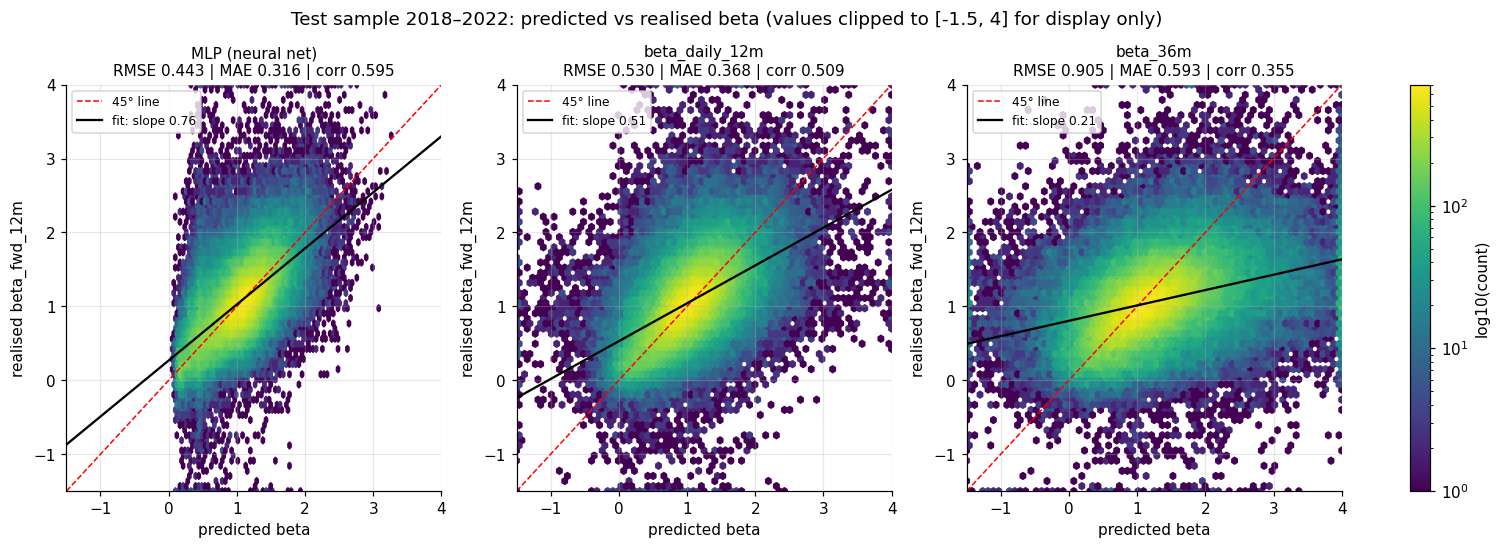

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, k in zip(axes, ["MLP (neural net)", "beta_daily_12m", "beta_36m"]):
    p_ = preds_test[k]
    hb = ax.hexbin(np.clip(p_, -1.5, 4), np.clip(y_test, -1.5, 4), gridsize=70, bins="log", cmap="viridis", mincnt=1)
    ax.plot([-1.5, 4], [-1.5, 4], "r--", lw=1, label="45° line")
    b1, b0 = np.polyfit(p_, y_test, 1)
    ax.plot([-1.5, 4], [b0 - 1.5 * b1, b0 + 4 * b1], "k-", lw=1.5, label=f"fit: slope {b1:.2f}")
    m = test_tab.loc[k]
    ax.set_title(f"{k}\nRMSE {m.RMSE:.3f} | MAE {m.MAE:.3f} | corr {m.Corr:.3f}", fontsize=10)
    ax.set_xlabel("predicted beta"); ax.set_ylabel("realised beta_fwd_12m")
    ax.set_xlim(-1.5, 4); ax.set_ylim(-1.5, 4); ax.legend(loc="upper left", fontsize=8)
plt.colorbar(hb, ax=axes, fraction=0.015, label="log10(count)")
plt.suptitle("Test sample 2018–2022: predicted vs realised beta (values clipped to [-1.5, 4] for display only)", y=1.02)
savefig("step5_scatter"); plt.show()

### 5.3 Cross-sectional average predicted and realised beta over time

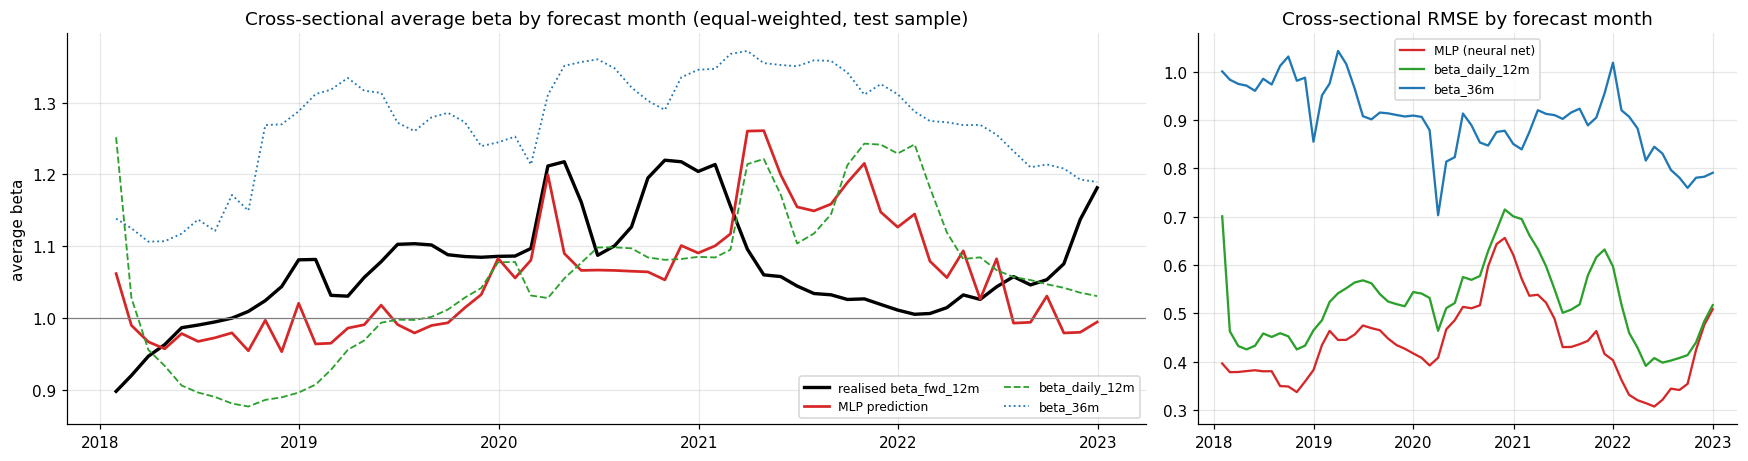

Average level and bias by forecast year (means of the monthly cross-sectional averages)


,realised,MLP,beta_daily_12m,beta_36m,MLP bias,daily bias,36m bias
year,,,,,,,
2018,0.9880,0.9830,0.9410,1.1670,-0.0050,-0.0470,0.1790
2019,1.0780,1.0000,0.9920,1.2870,-0.0770,-0.0850,0.2100
2020,1.1600,1.0830,1.0750,1.3160,-0.0770,-0.0860,0.1550
2021,1.0650,1.1730,1.1730,1.3460,0.1090,0.1090,0.2810
2022,1.0570,1.0380,1.0870,1.2400,-0.0190,0.0300,0.1830


In [62]:
ts5 = pd.DataFrame({"date": test_df.date.to_numpy(), "realised": y_test,
                    "MLP": preds_test["MLP (neural net)"], "beta_daily_12m": preds_test["beta_daily_12m"],
                    "beta_36m": preds_test["beta_36m"]}).groupby("date").mean()
fig, ax = plt.subplots(1, 2, figsize=(16, 4.3), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(ts5.index, ts5.realised, color="k", lw=2.2, label="realised beta_fwd_12m")
ax[0].plot(ts5.index, ts5.MLP, color="#d62728", lw=1.8, label="MLP prediction")
ax[0].plot(ts5.index, ts5.beta_daily_12m, color="#2ca02c", lw=1.2, ls="--", label="beta_daily_12m")
ax[0].plot(ts5.index, ts5.beta_36m, color="#1f77b4", lw=1.2, ls=":", label="beta_36m")
ax[0].axhline(1, color="grey", lw=0.8)
ax[0].set_title("Cross-sectional average beta by forecast month (equal-weighted, test sample)")
ax[0].legend(fontsize=8, ncol=2); ax[0].set_ylabel("average beta")
# month-by-month cross-sectional RMSE
cs = pd.DataFrame({"date": test_df.date.to_numpy(), **{k: (preds_test[k] - y_test) ** 2
                   for k in ["MLP (neural net)", "beta_daily_12m", "beta_36m"]}}).groupby("date").mean() ** 0.5
for k, c in [("MLP (neural net)", "#d62728"), ("beta_daily_12m", "#2ca02c"), ("beta_36m", "#1f77b4")]:
    ax[1].plot(cs.index, cs[k], color=c, label=k)
ax[1].set_title("Cross-sectional RMSE by forecast month"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("step5_timeseries"); plt.show()
yr5 = ts5.assign(year=ts5.index.year).groupby("year").mean()
yr5["MLP bias"] = yr5.MLP - yr5.realised; yr5["daily bias"] = yr5.beta_daily_12m - yr5.realised
yr5["36m bias"] = yr5.beta_36m - yr5.realised
print("Average level and bias by forecast year (means of the monthly cross-sectional averages)")
yr5.round(3)

### 5.4 Error by industry and by firm size

In [63]:
err = pd.DataFrame({"industry": test_df.industry.to_numpy(), "size_q": pd.qcut(test_df.log_market_cap, 5, labels=[
    "Q1 small", "Q2", "Q3", "Q4", "Q5 large"]).to_numpy(), "y": y_test,
    **{k: preds_test[k] for k in ["MLP (neural net)", "OLS on same inputs (ref)", "beta_daily_12m", "beta_36m"]}})
def grp_rmse(g, key):
    out = g.groupby(key, observed=True).apply(lambda d: pd.Series(
        {"N": len(d), **{f"RMSE {k}": np.sqrt(((d[k] - d.y) ** 2).mean()) for k in
                         ["MLP (neural net)", "OLS on same inputs (ref)", "beta_daily_12m", "beta_36m"]},
         "MAE MLP": (d["MLP (neural net)"] - d.y).abs().mean(), "MAE daily": (d["beta_daily_12m"] - d.y).abs().mean(),
         "mean realised": d.y.mean(), "MLP bias": (d["MLP (neural net)"] - d.y).mean()}))
    out["MLP RMSE gain vs daily %"] = 100 * (1 - out["RMSE MLP (neural net)"] / out["RMSE beta_daily_12m"])
    out["MLP RMSE gain vs 36m %"] = 100 * (1 - out["RMSE MLP (neural net)"] / out["RMSE beta_36m"])
    return out
ind_err = grp_rmse(err, "industry").sort_values("RMSE MLP (neural net)")
ind_err.to_csv("results/step5_error_by_industry.csv")
ind_err

,N,RMSE MLP (neural net),RMSE OLS on same inputs (ref),RMSE beta_daily_12m,RMSE beta_36m,MAE MLP,MAE daily,mean realised,MLP bias,MLP RMSE gain vs daily %,MLP RMSE gain vs 36m %
industry,,,,,,,,,,,
NoDur,"7,245.0000",0.3583,0.3904,0.4296,0.6994,0.2650,0.2958,0.8014,-0.0261,16.5881,48.7696
Manuf,"18,051.0000",0.3719,0.3821,0.4223,0.7395,0.2700,0.2998,1.1220,0.0340,11.9292,49.7138
Utils,"4,183.0000",0.3750,0.3638,0.4211,0.5003,0.3046,0.3344,0.6410,0.0024,10.9593,25.0534
HiTec,"22,271.0000",0.4121,0.4354,0.5132,0.7654,0.2971,0.3611,1.1623,-0.0294,19.6980,46.1588
Shops,"14,963.0000",0.4291,0.4544,0.5080,0.8828,0.3080,0.3552,1.0764,-0.0354,15.5219,51.3917
Telcm,"3,895.0000",0.4412,0.4732,0.5189,0.7953,0.3169,0.3760,1.0283,-0.0168,14.9723,44.5235
Other,"75,983.0000",0.4509,0.4514,0.5312,0.9121,0.3292,0.3797,1.0668,-0.0081,15.1266,50.5672
Durbl,"3,528.0000",0.4720,0.4896,0.6458,0.9647,0.2712,0.3321,1.0915,0.0659,26.9174,51.0762
Hlth,"15,095.0000",0.5018,0.5285,0.6216,1.1539,0.3354,0.4241,1.0374,-0.0714,19.2806,56.5163


In [64]:
size_err = grp_rmse(err, "size_q")
size_err.to_csv("results/step5_error_by_size.csv")
size_err

,N,RMSE MLP (neural net),RMSE OLS on same inputs (ref),RMSE beta_daily_12m,RMSE beta_36m,MAE MLP,MAE daily,mean realised,MLP bias,MLP RMSE gain vs daily %,MLP RMSE gain vs 36m %
size_q,,,,,,,,,,,
Q1 small,"34,130.0000",0.6087,0.6234,0.7649,1.3775,0.4073,0.5315,0.7908,-0.1819,20.4192,55.8134
Q2,"34,130.0000",0.4753,0.4805,0.5751,0.9777,0.3634,0.4172,1.1108,0.0629,17.3580,51.3891
Q3,"34,130.0000",0.4084,0.4106,0.4608,0.7682,0.3101,0.3442,1.2069,0.0422,11.3735,46.8420
Q4,"34,130.0000",0.3554,0.3548,0.3978,0.6400,0.2692,0.2984,1.1880,0.0107,10.6620,44.4716
Q5 large,"34,130.0000",0.3023,0.3503,0.3435,0.4892,0.2284,0.2497,1.0501,-0.0010,11.9902,38.2086


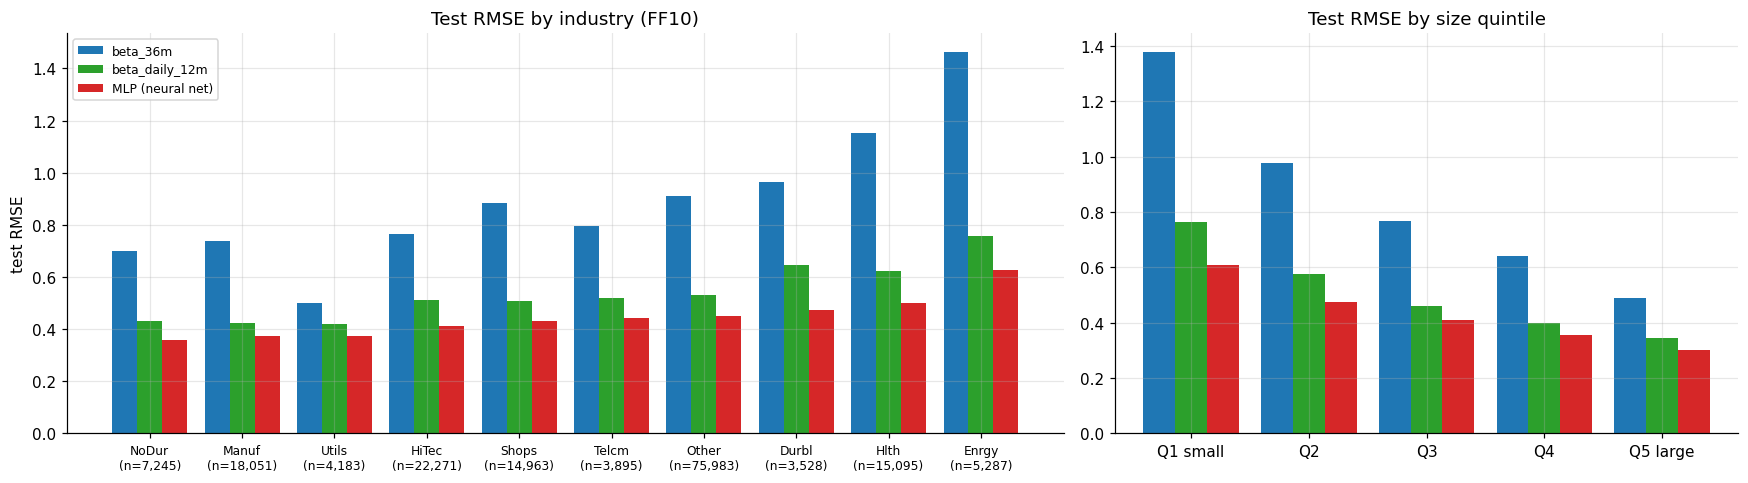

In [65]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
order = ind_err.drop(index="Unknown", errors="ignore").index
w = 0.27; x = np.arange(len(order))
for j, (k, c) in enumerate([("beta_36m", "#1f77b4"), ("beta_daily_12m", "#2ca02c"), ("MLP (neural net)", "#d62728")]):
    ax[0].bar(x + (j - 1) * w, ind_err.loc[order, f"RMSE {k}"], w, color=c, label=k)
ax[0].set_xticks(x); ax[0].set_xticklabels([f"{i}\n(n={int(ind_err.loc[i, 'N']):,})" for i in order], fontsize=8)
ax[0].set_ylabel("test RMSE"); ax[0].set_title("Test RMSE by industry (FF10)"); ax[0].legend(fontsize=8)
xs = np.arange(5)
for j, (k, c) in enumerate([("beta_36m", "#1f77b4"), ("beta_daily_12m", "#2ca02c"), ("MLP (neural net)", "#d62728")]):
    ax[1].bar(xs + (j - 1) * w, size_err[f"RMSE {k}"], w, color=c, label=k)
ax[1].set_xticks(xs); ax[1].set_xticklabels(size_err.index); ax[1].set_title("Test RMSE by size quintile")
plt.tight_layout(); savefig("step5_error_groups"); plt.show()

### 5.5 Discussion: where the neural model improves and where it does not
**Headline (test 2018–2022, 170,650 identical rows).**
- The MLP has RMSE 0.443, MAE 0.316 and correlation 0.595. **$R^2_{OOS}$ relative to `beta_36m` is 0.760**: the MLP's squared error is 76% below the benchmark's.
- It improves on *every* benchmark on every metric, and the ranking from validation holds on test.
- The MLP's loss is lower than both `beta_36m` and `beta_daily_12m` in **all 60 test months** (Newey–West t = 11.3 and 9.4).

**Gains relative to the monthly rolling betas and to the daily-beta persistence forecast are two different things.**
- *Against the monthly betas (12/24/36m) the gain is large (R² 0.76), but it is an easy bar.* A constant forecast of 1.0 already achieves R² 0.64 against `beta_36m`.
  Most of this gain comes from replacing noisy, upward-biased monthly estimates (bias +0.20) with a precise, well-centred forecast (bias −0.01).
  Better *measurement* (daily data) and *shrinkage* do the work.
- *Against the daily-beta persistence forecast, which is also an input to the model, the gain is the genuinely informative one.*
  - MSE falls by **30%** (supplementary R² vs daily = 0.30; RMSE 0.443 vs 0.530; MAE 0.316 vs 0.368).
  - The daily beta is too dispersed: realised beta rises only 0.51 for each unit of daily beta. The MLP pulls extreme values back towards the mean
    (fit slope 0.76, predictions stay between about 0 and 3).
  - It also conditions that shrinkage on size, volatility, past returns and industry.
- *Non-linearity adds a smaller but significant part.* An OLS regression on the same inputs already captures most of the gain (R² vs daily 0.26).
  The MLP improves on OLS further (RMSE 0.443 vs 0.455; t = 3.9; better in 73% of months). The gain is largest among **large firms**, where OLS is
  *worse* than the daily beta but the MLP is 12% better, and among small firms.

**Where it improves most.**
- **By industry:** the MLP beats both benchmarks in every industry.
  - The largest gains over the daily beta are in Durables (27%), HiTec (20%), Health (19%) and Energy (17%). These are volatile, heterogeneous industries
    where the daily beta is noisiest and shrinkage pays off most.
  - Errors remain highest in Energy (0.63) and Health (0.50), whose betas move with commodity prices and biotech-specific news.
- **By size:** the gain over the daily beta is largest for small firms (Q1: 20%) and falls to about 11–12% for mid-to-large firms.
  This is consistent with the thin-trading correction that size provides.

**Where it does not improve, or has limits.**
- **Small firms are under-predicted** (bias −0.18 in Q1).
  - Small test firms have higher realised betas (0.79) than the training-era pattern implies.
  - This is the non-stationarity found in Step 4: the strong thin-trading discount learned from 1998–2002 is too strong for 2018–22.
- **Market-wide shifts in beta are not anticipated.**
  - The average MLP forecast tracks the trailing daily beta with a lag. It under-predicts the COVID-era jump in realised betas in 2019–20 (bias −0.08)
    and over-predicts in 2021 (+0.11), when trailing windows still contained the crash.
  - The gain is in **ranking firms within each month**, not in timing the average level. That is expected given the few market-level inputs.
- **Utilities:** the linear model is slightly better than the MLP (0.364 vs 0.375). With a low and stable beta, the extra flexibility buys nothing.
- **Noise in the realised target itself** caps achievable accuracy. Even the best model explains only about 35% of the cross-sectional variance
  (correlation 0.595). Most of the remaining error is probably measurement noise in 12-month realised betas rather than forecastable signal.

## Step 6: Economic Interpretation of the Neural Beta Forecasts (Quintile Sorts)
In each test month, firms are sorted into five equal-sized portfolios by their **predicted** neural beta. Ties are broken
deterministically: rows are ordered by `permno` first, and `rank(method="first")` then gives tied predictions consecutive ranks in `permno` order.
For each month and quintile we compute equal-weighted averages of predicted beta, realised future beta (`beta_fwd_12m`)
and the subsequent **one-month** return (`return_fwd_1m`), then average those monthly portfolio statistics over the 60 test months.
Missing next-month returns are excluded **only** from the return averages (not filled with 0), and their count is reported.
These are descriptive sorts, not an implementable trading strategy.

For comparison, the same sort is repeated with `beta_36m` (the classical rolling beta from my earlier CAPM study) and `beta_daily_12m`.

In [66]:
def nw_t(x, lags=12):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; T = len(x); u = x - x.mean()
    lrv = u @ u / T + 2 * sum((1 - k / (lags + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, lags + 1))
    return x.mean() / np.sqrt(lrv / T)

def quintile_sort(frame, sort_col):
    d = frame.sort_values(["date", "permno"]).copy()                       # permno order breaks ties
    d["rank"] = d.groupby("date")[sort_col].rank(method="first")
    d["n_month"] = d.groupby("date")["rank"].transform("size")
    d["Q"] = np.ceil(d["rank"] * 5 / d["n_month"]).astype(int)             # 1 = lowest predicted beta
    monthly = d.groupby(["date", "Q"]).agg(pred=(sort_col, "mean"), realised=(TARGET, "mean"),
                                           ret_1m=("return_fwd_1m", "mean"),   # NaNs skipped, not filled
                                           n=("permno", "size"), n_ret_missing=("return_fwd_1m", lambda s: s.isna().sum()))
    return d, monthly

q_frame = test_df[["permno", "date", TARGET, "return_fwd_1m", "beta_36m", "beta_daily_12m"]].copy()
q_frame["beta_NN"] = preds_test["MLP (neural net)"]
q_rows, q_monthly = q_frame, {}
for col in ["beta_NN", "beta_36m", "beta_daily_12m"]:
    q_rows_col, q_monthly[col] = quintile_sort(q_frame, col)
    if col == "beta_NN":
        q_rows = q_rows_col
assert q_rows.groupby(["date", "Q"]).size().groupby("date").agg(lambda s: s.max() - s.min()).max() <= 1  # equal sizes

m = q_monthly["beta_NN"]
qt = m.groupby("Q").agg(avg_predicted_beta=("pred", "mean"), avg_realised_beta=("realised", "mean"),
                        avg_next_month_return=("ret_1m", "mean"), avg_firms_per_month=("n", "mean"),
                        total_missing_returns=("n_ret_missing", "sum"))
qt["return NW t-stat"] = [nw_t(m.xs(q, level="Q").ret_1m) for q in qt.index]
spread = m.ret_1m.unstack()[5] - m.ret_1m.unstack()[1]
bspread = m.realised.unstack()[5] - m.realised.unstack()[1]
qt.loc["Q5 - Q1"] = [qt.avg_predicted_beta[5] - qt.avg_predicted_beta[1], bspread.mean(), spread.mean(),
                     np.nan, np.nan, nw_t(spread)]
qt.to_csv("results/step6_quintiles_nn.csv")
print(f"Test months: {m.index.get_level_values('date').nunique()}; missing return_fwd_1m excluded from return "
      f"averages only: {int(m.n_ret_missing.sum())} of {int(m.n.sum()):,} firm-months")
qt

Test months: 60; missing return_fwd_1m excluded from return averages only: 11 of 170,650 firm-months


,avg_predicted_beta,avg_realised_beta,avg_next_month_return,avg_firms_per_month,total_missing_returns,return NW t-stat
Q,,,,,,
1,0.4645,0.6291,0.0156,568.4667,7.0000,1.1276
2,0.8479,0.9073,0.0070,568.7833,2.0000,0.8533
3,1.0717,1.0637,0.0091,568.9000,0.0000,1.1668
4,1.2706,1.2169,0.0087,568.7833,0.0000,0.9374
5,1.6225,1.5298,0.0107,569.2333,2.0000,0.7065
Q5 - Q1,1.1580,0.9007,-0.0048,NaN,NaN,-1.1178


In [67]:
# Monotonicity checks
real = m.realised.unstack(); pred_ = m.pred.unstack(); ret_ = m.ret_1m.unstack()
mono_avg = bool(np.all(np.diff(qt.loc[[1, 2, 3, 4, 5], "avg_realised_beta"]) > 0))
mono_month = (real.diff(axis=1).iloc[:, 1:] > 0).all(axis=1)
print(f"Average realised beta increases monotonically Q1->Q5: {mono_avg}")
print(f"Share of test months in which realised beta is monotone across all five quintiles: {mono_month.mean():.1%}")
print(f"Q5-Q1 realised-beta spread: mean {bspread.mean():.3f}, min {bspread.min():.3f}, positive in {(bspread > 0).mean():.0%} of months")
print(f"Q5-Q1 next-month return spread: {spread.mean():.4f} per month (NW t = {nw_t(spread):.2f}); "
      f"positive in {(spread > 0).mean():.0%} of months")
print(f"Realised/predicted ratio by quintile: {(qt.avg_realised_beta / qt.avg_predicted_beta).loc[[1,2,3,4,5]].round(3).to_dict()}")

Average realised beta increases monotonically Q1->Q5: True
Share of test months in which realised beta is monotone across all five quintiles: 100.0%
Q5-Q1 realised-beta spread: mean 0.901, min 0.563, positive in 100% of months
Q5-Q1 next-month return spread: -0.0048 per month (NW t = -1.12); positive in 43% of months
Realised/predicted ratio by quintile: {1: 1.354, 2: 1.07, 3: 0.993, 4: 0.958, 5: 0.943}


In [68]:
# The same sort with the classical and daily historical betas
comp = {}
for col in ["beta_NN", "beta_36m", "beta_daily_12m"]:
    mm = q_monthly[col]
    comp[col] = pd.DataFrame({"avg sort beta": mm.pred.groupby("Q").mean(), "avg realised beta": mm.realised.groupby("Q").mean(),
                              "avg next-month return": mm.ret_1m.groupby("Q").mean()})
comp_tab = pd.concat(comp, axis=1)
summ = pd.DataFrame({col: {
    "realised-beta spread Q5-Q1": q_monthly[col].realised.unstack().pipe(lambda u: (u[5] - u[1]).mean()),
    "sort-beta spread Q5-Q1": q_monthly[col].pred.unstack().pipe(lambda u: (u[5] - u[1]).mean()),
    "realised / sorted spread": q_monthly[col].realised.unstack().pipe(lambda u: (u[5] - u[1]).mean())
                                / q_monthly[col].pred.unstack().pipe(lambda u: (u[5] - u[1]).mean()),
    "% months realised beta monotone": 100 * (q_monthly[col].realised.unstack().diff(axis=1).iloc[:, 1:] > 0).all(axis=1).mean(),
    "within-quintile sd of realised beta (avg)": q_frame.assign(Q=quintile_sort(q_frame, col)[0]["Q"])
                                                     .groupby(["date", "Q"])[TARGET].std().mean(),
    "return spread Q5-Q1 (per month)": q_monthly[col].ret_1m.unstack().pipe(lambda u: (u[5] - u[1]).mean()),
    "return spread NW t": nw_t(q_monthly[col].ret_1m.unstack().pipe(lambda u: u[5] - u[1]))} for col in comp})
comp_tab.to_csv("results/step6_quintiles_comparison.csv"); summ.to_csv("results/step6_sort_summary.csv")
display(comp_tab.round(4))
summ.round(4)

beta_NN                                              beta_36m                                         beta_daily_12m                                        
  avg sort beta avg realised beta avg next-month return avg sort beta avg realised beta avg next-month return  avg sort beta avg realised beta avg next-month return
Q                                                                                                                                                                   
1        0.4645            0.6291                0.0156        0.2308            0.7543                0.0054         0.3588            0.6569                0.0164
2        0.8479            0.9073                0.0070        0.8362            0.9296                0.0082         0.8053            0.9232                0.0093
3        1.0717            1.0637                0.0091        1.1770            1.0789                0.0118         1.0452            1.0738                0.0079
4        1.2706            1.2169                0.0087        1.5628            1.2107                0.0109         1.2887            1.2190                0.0082
5        1.6225            1.5298                0.0107        2.5472            1.3736                0.0149         1.7691            1.4740                0.0095

,beta_NN,beta_36m,beta_daily_12m
realised-beta spread Q5-Q1,0.9007,0.6193,0.8171
sort-beta spread Q5-Q1,1.1580,2.3164,1.4103
realised / sorted spread,0.7778,0.2673,0.5794
% months realised beta monotone,100.0000,91.6667,100.0000
within-quintile sd of realised beta (avg),0.4159,0.4747,0.4343
return spread Q5-Q1 (per month),-0.0048,0.0094,-0.0069
return spread NW t,-1.1178,0.8094,-1.0290


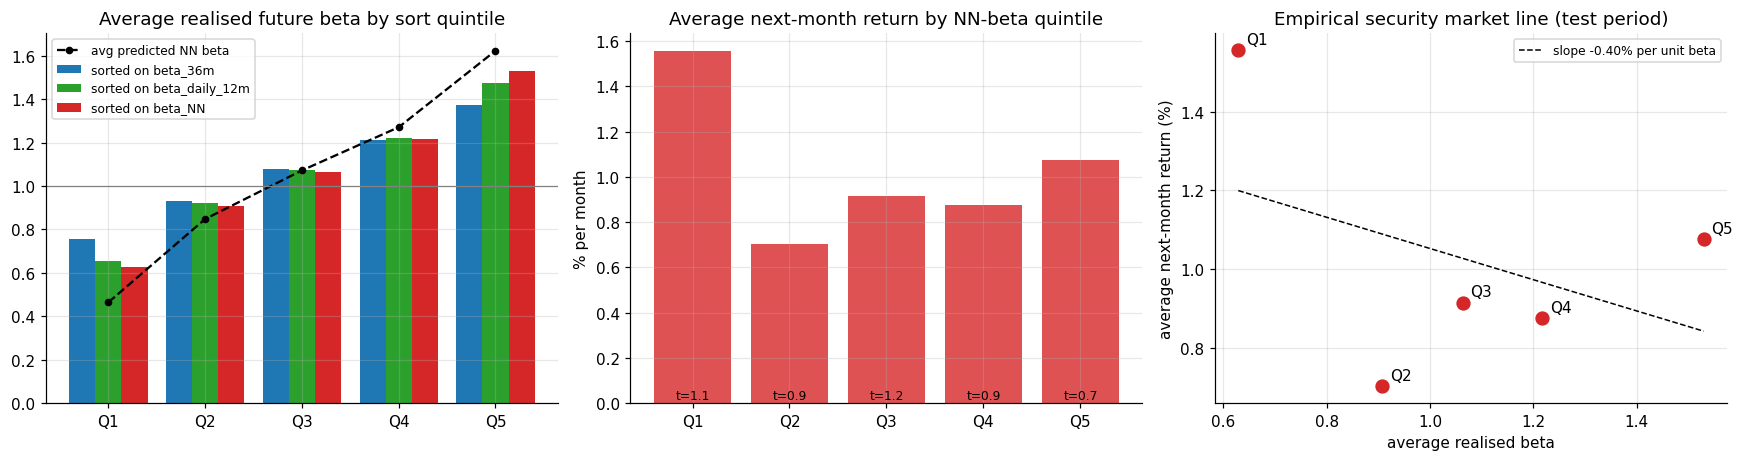

In [69]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
x = np.arange(1, 6); w = 0.27
for j, (col, c) in enumerate([("beta_36m", "#1f77b4"), ("beta_daily_12m", "#2ca02c"), ("beta_NN", "#d62728")]):
    ax[0].bar(x + (j - 1) * w, comp[col]["avg realised beta"], w, color=c, label=f"sorted on {col}")
ax[0].plot(x, qt.loc[[1, 2, 3, 4, 5], "avg_predicted_beta"], "k--o", ms=4, label="avg predicted NN beta")
ax[0].set_xticks(x); ax[0].set_xticklabels([f"Q{i}" for i in x]); ax[0].axhline(1, color="grey", lw=0.8)
ax[0].set_title("Average realised future beta by sort quintile"); ax[0].legend(fontsize=8)
ax[1].bar(x, 100 * qt.loc[[1, 2, 3, 4, 5], "avg_next_month_return"], color="#d62728", alpha=0.8)
for xi, t in zip(x, qt.loc[[1, 2, 3, 4, 5], "return NW t-stat"]):
    ax[1].annotate(f"t={t:.1f}", (xi, 0), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"Q{i}" for i in x]); ax[1].set_ylabel("% per month")
ax[1].set_title("Average next-month return by NN-beta quintile")
ax[2].scatter(qt.loc[[1, 2, 3, 4, 5], "avg_realised_beta"], 100 * qt.loc[[1, 2, 3, 4, 5], "avg_next_month_return"],
              s=70, color="#d62728")
for q in x:
    ax[2].annotate(f"Q{q}", (qt.loc[q, "avg_realised_beta"], 100 * qt.loc[q, "avg_next_month_return"]),
                   xytext=(5, 4), textcoords="offset points")
b_, a_ = np.polyfit(qt.loc[[1, 2, 3, 4, 5], "avg_realised_beta"], 100 * qt.loc[[1, 2, 3, 4, 5], "avg_next_month_return"], 1)
xx = np.linspace(qt.avg_realised_beta.loc[[1, 5]].min(), qt.avg_realised_beta.loc[[1, 5]].max(), 10)
ax[2].plot(xx, a_ + b_ * xx, "k--", lw=1, label=f"slope {b_:.2f}% per unit beta")
ax[2].set_xlabel("average realised beta"); ax[2].set_ylabel("average next-month return (%)")
ax[2].set_title("Empirical security market line (test period)"); ax[2].legend(fontsize=8)
plt.tight_layout(); savefig("step6_quintiles"); plt.show()

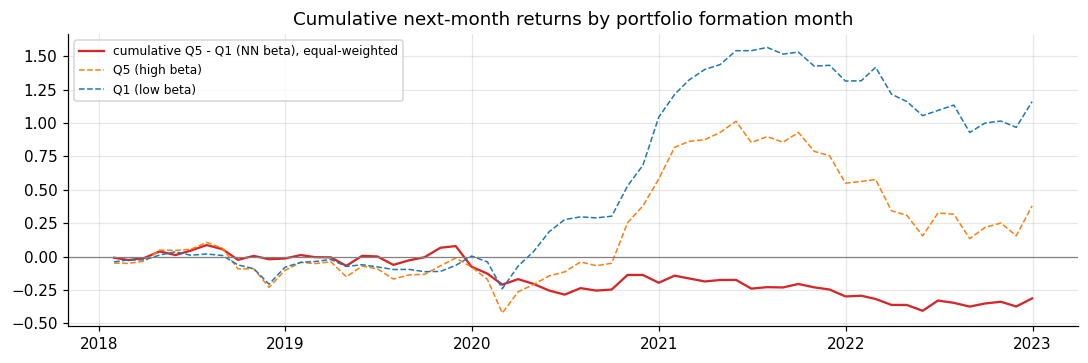

In [70]:
# Return spread over time (cumulative Q5 - Q1, descriptive only)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(spread.index, (1 + spread).cumprod() - 1, color="#d62728", label="cumulative Q5 - Q1 (NN beta), equal-weighted")
ax.plot(ret_.index, (1 + ret_[5]).cumprod() - 1, color="#ff7f0e", lw=1, ls="--", label="Q5 (high beta)")
ax.plot(ret_.index, (1 + ret_[1]).cumprod() - 1, color="#1f77b4", lw=1, ls="--", label="Q1 (low beta)")
ax.axhline(0, color="grey", lw=0.8); ax.legend(fontsize=8); ax.set_title("Cumulative next-month returns by portfolio formation month")
plt.tight_layout(); savefig("step6_cumulative"); plt.show()

In [71]:
# Who is in each NN-beta quintile? (characteristics at formation, averaged over months)
chars = q_rows.merge(test_df[["permno", "date", "log_market_cap", "idio_vol_daily_12m", "industry", "beta_daily_12m"]]
                     .rename(columns={"beta_daily_12m": "bd"}), on=["permno", "date"])
char_tab = chars.groupby("Q").agg(median_mcap_musd=("log_market_cap", lambda s: np.exp(s.median()) / 1e6),
                                  mean_idio_vol_daily=("idio_vol_daily_12m", "mean"),
                                  mean_daily_beta=("bd", "mean"))
ind_mix = pd.crosstab(chars.Q, chars.industry, normalize="index")
char_tab["top industries"] = [", ".join(f"{i} {v:.0%}" for i, v in ind_mix.loc[q].nlargest(3).items()) for q in char_tab.index]
ret_by_year = ret_.assign(year=ret_.index.year).groupby("year").mean()
char_tab

,median_mcap_musd,mean_idio_vol_daily,mean_daily_beta,top industries
Q,,,,
1,66.3048,0.0377,0.4889,"Other 41%, Hlth 11%, HiTec 10%"
2,"1,259.6680",0.0300,0.8329,"Other 44%, Hlth 12%, Shops 11%"
3,"1,778.7923",0.0255,1.0236,"Other 49%, HiTec 14%, Manuf 10%"
4,"1,515.2814",0.0280,1.2509,"Other 47%, HiTec 15%, Manuf 14%"
5,"1,286.8092",0.0385,1.6734,"Other 42%, HiTec 16%, Manuf 15%"


In [72]:
print("Average next-month return (per month) by NN quintile and formation year")
(100 * ret_by_year).round(2)

Average next-month return (per month) by NN quintile and formation year


Q,1,2,3,4,5
year,,,,,
2018,-0.4800,0.0300,-0.2000,-0.0700,-0.5400
2019,0.7900,0.6100,1.0000,0.7700,0.4400
2020,6.8100,3.2900,2.6000,3.0100,5.8700
2021,1.1100,-0.1200,0.9100,0.5000,0.0500
2022,-0.4300,-0.3000,0.2700,0.1600,-0.4400


### 6.1 Discussion
**Risk separation: strong, and monotone in every month.**
- Average realised future beta rises monotonically from Q1 to Q5 (0.63 → 0.91 → 1.06 → 1.22 → 1.53). The ordering is monotone in **all 60 test months**,
  and the Q5–Q1 spread is never below 0.56.
- The neural forecast separates future risk better than the historical estimates:
  - realised-beta spread 0.90, against 0.82 for sorting on the daily beta and 0.62 on `beta_36m`;
  - `beta_36m` is monotone in only 92% of months;
  - the within-quintile dispersion of realised beta is lowest for the NN sort (0.42, against 0.43 and 0.47).
- `beta_36m` sorts are dominated by estimation noise. Its sort-beta spread is 2.32, but only 27% of it shows up in realised beta. For the NN the figure is 78%.
- **Calibration:** in Q3–Q5, realised betas are within about 6% of the predictions. The lowest quintile is under-predicted (0.46 predicted vs 0.63 realised).
  It is dominated by micro-caps (median size \$66m against \$1.3–1.8bn in the other quintiles), whose low trailing daily betas partly reflect thin trading.
  This is the same small-firm bias as in Step 5.

**Relationship with subsequent returns: flat or even negative.**
- Next-month returns do not rise with beta: 1.56% (Q1), 0.70%, 0.91%, 0.87%, 1.07% (Q5) per month. The Q5–Q1 spread is −0.48% per month
  (Newey–West t = −1.1, positive in only 43% of months).
- None of the quintile means or the spread is statistically significant. Five years (60 months, including the COVID crash and rebound) is far too short
  to estimate expected returns precisely.
- The high Q1 average comes almost entirely from **2020**, when micro-caps rebounded (6.8% per month). It reflects size, illiquidity and market-timing effects,
  not a reward for low beta.
- Economically, the CAPM predicts that higher beta should earn higher expected returns (a positive security-market-line slope, about the market premium).
  The test period shows the well-known **flat security market line** (Black, Jensen & Scholes 1972; Fama & French 1992; Frazzini & Pedersen 2014,
  "betting against beta"). Better beta *forecasts* do not create a positive beta–return relation that the data do not contain.

**Comparison with my earlier CAPM beta study.**
- There I sorted the largest ten firms per industry on 12-month historical betas (quintile averages 0.00 to 2.12). Next-year excess returns
  were not monotonic, with a 5–1 spread of only 0.13 pp per month (0.11 value-weighted), which I read as the beta anomaly.
- Step 2 shows that a 12-month beta passes only about 9% of its deviation into next year's beta, so much of that 0.00 to 2.12 spread was
  estimation noise, and the true risk gap between those portfolios was far smaller than it appeared.
- Here the MLP sort produces a genuine realised-beta gap (0.90), and returns are *still* flat. The beta anomaly is therefore not just an
  artifact of noisy beta estimates. The samples differ (largest firms and excess returns in 1.2; all eligible firms and raw returns here),
  so the comparison is qualitative.
- The earlier study estimated betas from historical rolling windows. Here those historical estimates are the weakest forecasts: `beta_36m` quintiles
  separate future beta far less well, because most of their spread is estimation noise.
- The neural forecast (and even the trailing daily beta) produces much cleaner risk-sorted portfolios. For risk management and portfolio construction,
  e.g. building a low-beta or beta-neutral portfolio, the forward-looking beta is the better input.
- On the pricing side, the conclusion is the same as in the classical analysis: beta, however well measured, does not explain the cross-section of
  average returns in this sample.
- Caveats: these are equal-weighted descriptive sorts on an ex-post-selected sample (no delisting returns, and survival over the next 12 months
  is required), not an implementable trading strategy.

## Step 7: Predictor Importance (Group Permutation on the Test Data)
1. Compute the fitted MLP's test RMSE on the unaltered test inputs.
2. Shuffle **one predictor group** across the test observations, using the **same row permutation for every column in the group**
   (including all 10 industry dummies, so every row still has a valid one-hot industry). The other groups are left unchanged.
3. Recompute the RMSE with the *same* fitted model. There is no refitting and nothing is tuned on these results.
4. Repeat with 5 different permutations and report the mean and standard deviation of the RMSE increase.

Shuffling breaks the link between that group and the target while keeping the group's distribution (and the correlations *within* the group) intact.
A large RMSE increase means the model relies on that group. This measures how much the *fitted model* uses the information,
which is not a causal effect of the underlying characteristic.

In [73]:
N_REP = 5
base_pred = predict(nn_model, X_test).ravel()
base_rmse = np.sqrt(np.mean((base_pred - y_test) ** 2)); base_mae = np.mean(np.abs(base_pred - y_test))
print(f"Original test RMSE {base_rmse:.4f} (MAE {base_mae:.4f})")

def permute_cols(X, idx, rng):
    Xp = X.copy()
    perm = rng.permutation(len(X))                      # ONE permutation shared by all columns in the group
    Xp[:, idx] = X[perm][:, idx]
    return Xp

imp_rows = []
for g, idx in GROUP_IDX.items():
    rng = np.random.default_rng(SEED)
    for r in range(N_REP):
        pp = predict(nn_model, permute_cols(X_test, idx, rng)).ravel()
        imp_rows.append({"group": g, "rep": r, "RMSE": np.sqrt(np.mean((pp - y_test) ** 2)),
                         "MAE": np.mean(np.abs(pp - y_test))})
imp = pd.DataFrame(imp_rows)
imp["dRMSE"] = imp.RMSE - base_rmse; imp["dMAE"] = imp.MAE - base_mae
imp_tab = imp.groupby("group").agg(n_columns=("group", lambda s: len(GROUP_IDX[s.iloc[0]])),
                                   mean_RMSE_permuted=("RMSE", "mean"), mean_RMSE_increase=("dRMSE", "mean"),
                                   sd_RMSE_increase=("dRMSE", "std"), min_increase=("dRMSE", "min"),
                                   max_increase=("dRMSE", "max"), mean_MAE_increase=("dMAE", "mean"))
imp_tab["% increase in RMSE"] = 100 * imp_tab.mean_RMSE_increase / base_rmse
imp_tab = imp_tab.sort_values("mean_RMSE_increase", ascending=False)
imp_tab.to_csv("results/step7_group_importance.csv")
imp_tab

Original test RMSE 0.4429 (MAE 0.3157)


,n_columns,mean_RMSE_permuted,mean_RMSE_increase,sd_RMSE_increase,min_increase,max_increase,mean_MAE_increase,% increase in RMSE
group,,,,,,,,
historical risk,7,0.5961,0.1532,0.0007,0.1526,0.1541,0.1408,34.5927
returns & size,5,0.5183,0.0754,0.0005,0.0749,0.0762,0.0697,17.0273
industry,10,0.4472,0.0043,0.0001,0.0041,0.0044,0.0042,0.9600


In [74]:
# Supplementary: permuting each numeric predictor on its own (industry block kept as one unit), same procedure.
# Shows which variables inside each group drive its importance.
var_rows = []
singles = {c: [FEATURE_NAMES.index(c)] for c in FEATURES_NUM} | {"industry (all dummies)": GROUP_IDX["industry"]}
for v, idx in singles.items():
    rng = np.random.default_rng(SEED)
    d_ = []
    for r in range(N_REP):
        pp = predict(nn_model, permute_cols(X_test, idx, rng)).ravel()
        d_.append(np.sqrt(np.mean((pp - y_test) ** 2)) - base_rmse)
    grp = "industry" if v.startswith("industry") else ("historical risk" if v in GROUPS["risk"] else "returns & size")
    var_rows.append({"variable": v, "group": grp, "mean_RMSE_increase": np.mean(d_), "sd": np.std(d_, ddof=1)})
var_tab = pd.DataFrame(var_rows).set_index("variable").sort_values("mean_RMSE_increase", ascending=False)
var_tab["% increase"] = 100 * var_tab.mean_RMSE_increase / base_rmse
var_tab.to_csv("results/step7_variable_importance.csv")
print("Sum of single-variable increases within historical risk:",
      round(var_tab.loc[var_tab.group == "historical risk", "mean_RMSE_increase"].sum(), 4),
      "vs group permutation:", round(imp_tab.loc["historical risk", "mean_RMSE_increase"], 4))
var_tab

Sum of single-variable increases within historical risk: 0.1479 vs group permutation: 0.1532


,group,mean_RMSE_increase,sd,% increase
variable,,,,
beta_daily_12m,historical risk,0.1217,0.0007,27.4703
log_market_cap,returns & size,0.0663,0.0007,14.9744
idio_vol_daily_12m,historical risk,0.0101,0.0002,2.2874
ret_3m,returns & size,0.0082,0.0001,1.8587
beta_36m,historical risk,0.0078,0.0001,1.7634
vol_12m,historical risk,0.0050,0.0001,1.1180
industry (all dummies),industry,0.0043,0.0001,0.9600
mom_12_2,returns & size,0.0033,0.0001,0.7529
ret,returns & size,0.0016,0.0001,0.3581


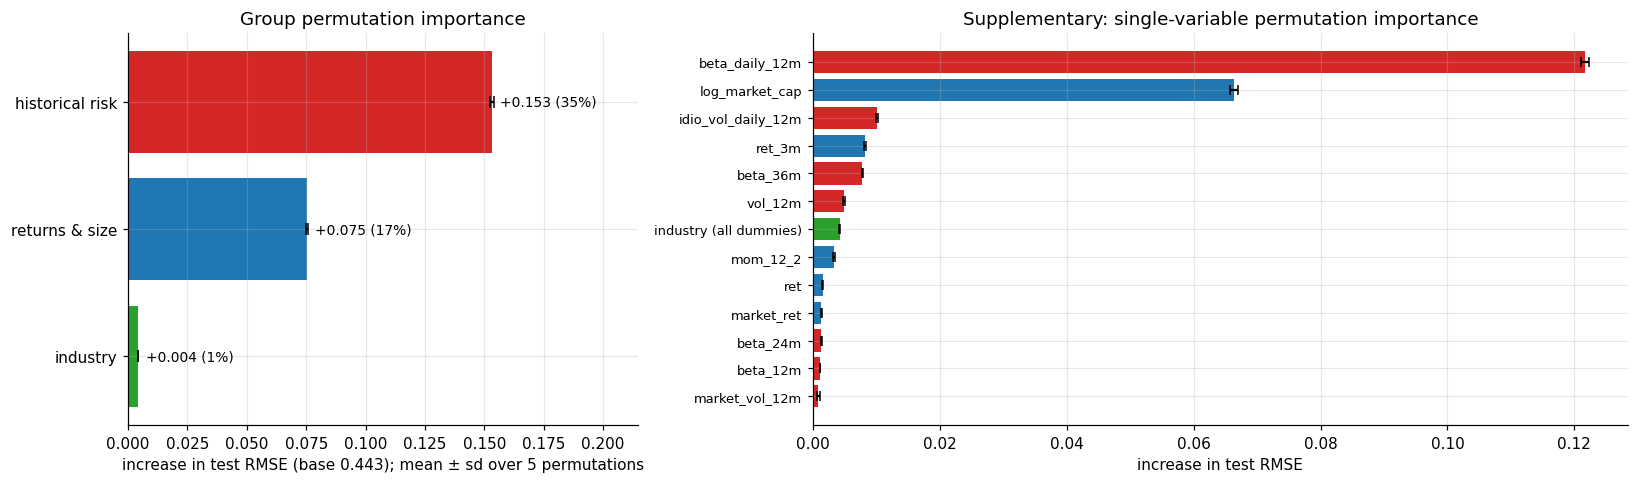

In [75]:
gcol = {"historical risk": "#d62728", "returns & size": "#1f77b4", "industry": "#2ca02c"}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].barh(imp_tab.index[::-1], imp_tab.mean_RMSE_increase[::-1], xerr=imp_tab.sd_RMSE_increase[::-1],
           color=[gcol[g] for g in imp_tab.index[::-1]], capsize=4)
for i, (g, r) in enumerate(imp_tab.iloc[::-1].iterrows()):
    ax[0].annotate(f"+{r.mean_RMSE_increase:.3f} ({r['% increase in RMSE']:.0f}%)", (r.mean_RMSE_increase, i),
                   xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
ax[0].set_xlabel(f"increase in test RMSE (base {base_rmse:.3f}); mean ± sd over {N_REP} permutations")
ax[0].set_title("Group permutation importance"); ax[0].set_xlim(0, imp_tab.mean_RMSE_increase.max() * 1.4)
vt_ = var_tab.iloc[::-1]
ax[1].barh(vt_.index, vt_.mean_RMSE_increase, xerr=vt_.sd, color=[gcol[g] for g in vt_.group], capsize=3)
ax[1].set_xlabel("increase in test RMSE"); ax[1].set_title("Supplementary: single-variable permutation importance")
ax[1].tick_params(axis="y", labelsize=8.5)
plt.tight_layout(); savefig("step7_importance"); plt.show()

### 7.1 Discussion
**Ranking of groups** (test RMSE 0.443 without any shuffling):
- **Historical risk:** +0.153 (+35%).
- **Returns & size:** +0.075 (+17%).
- **Industry:** +0.004 (+1%).

The ranking is identical for MAE. It is extremely stable across permutations (sd ≤ 0.001), so the differences are not random-draw noise.

**Economic plausibility.**
- **Historical risk matters most, and almost all of it is `beta_daily_12m`** (+0.122 on its own). This is exactly what economics and Steps 0–2 lead us to expect:
  beta is persistent, and the trailing daily beta is the most precise estimate of the same quantity we are forecasting. Idiosyncratic volatility is next in the group (+0.010).
  It tells the network how noisy that estimate is, and so how much to shrink it. The monthly betas add little once the daily beta is known
  (`beta_36m` +0.008; 12m/24m about +0.001). They are noisy and largely redundant.
- **Returns & size is driven by `log_market_cap`** (+0.066, the second most important variable overall). Size is how the model corrects the
  thin-trading bias of small firms' daily betas and captures the hump-shaped size–beta relation (Step 0.8). This is also where the MLP beats a linear model (Step 5).
  Recent returns (`ret_3m`, `mom_12_2`) add a little, in line with a leverage effect: after a price fall a firm's equity beta tends to rise.
  The market-wide variables (`market_ret`, `market_vol_12m`) contribute almost nothing. They are the same for every firm in a month, so they cannot help rank firms,
  and the model does not use them to time the market level (Step 5.3).
- **Industry adds little *once firm-level history is known*.** A firm's industry exposure is already reflected in its own trailing daily beta, and "Other" (the least
  informative category) makes up 45% of test rows. This does **not** mean industry is irrelevant to beta (Step 0.7 shows large industry differences). It means the
  information is redundant given the other inputs.

**Caveats: permutation importance is not causal.**
- It measures how much *this fitted model* relies on a group, not the effect of changing a firm's characteristics.
- Correlated predictors share credit. The single-variable importances within historical risk add up to about the group total (0.148 vs 0.153), but a variable can look
  unimportant simply because a correlated variable carries the same information. The monthly betas are an example.
- Shuffling creates combinations that don't occur in reality (e.g. a micro-cap with a mega-cap's volatility), so the network is evaluated partly outside its training distribution.
- The results describe the 2018–22 test period, and they were not used to tune or refit anything.

## Step 8: Multi-Output Industry-Beta Extension
For each firm-month, the target is now the vector of ten future **industry betas**,
$\beta^R_{i,t+12}=[\beta^R_{i,1,t+12},\dots,\beta^R_{i,10,t+12}]$. Each element is a *separate univariate* daily-return slope of the firm's return on one
FF10 value-weighted industry portfolio over months $t+1..t+12$. They are neither joint multifactor coefficients nor the industries' market betas.

**Sample:** `eligible_multi == True` with the same chronological splits. **Inputs:** the same 12 numeric predictors plus industry dummies. Preprocessing
is refit on the multi-output training sample, again on training data only. **Architecture and optimiser:** the market model selected in Step 4
(22 → 32 → 16, ReLU, dropout 0.05, Adam, the selected learning rate, batch 512, at most 100 epochs, early stopping with patience 10, best checkpoint restored).
There is no separate hyperparameter search for any industry.
- **Separate-output benchmark ("sep")**: ten single-output MLPs, one per industry target.
- **Multi-output model ("sim")**: one MLP whose final layer has ten outputs, trained on the **mean MSE across the ten unscaled targets**.

In [76]:
IND_NAMES = ["NoDur", "Durbl", "Manuf", "Enrgy", "HiTec", "Telcm", "Shops", "Hlth", "Utils", "Other"]  # FF10 labels, same order as IND_SUFFIX
multi = df.loc[df.eligible_multi].copy()
assert multi[IND_TARGETS].notna().all().all()
print("eligible_multi rows by split:", multi.split.value_counts().reindex(SPLITS).to_dict())
print("Identical to the eligible_core sample:", multi.index.equals(sample.index))

mtr, mva, mte = (multi[multi.split == s] for s in SPLITS)
prep_m = BetaPreprocessor(FEATURES_NUM, FEATURES_CAT, no_clip=MARKET_LEVEL).fit(mtr)    # training rows only
Xm_tr, Xm_va, Xm_te = prep_m.transform(mtr), prep_m.transform(mva), prep_m.transform(mte)
Ym_tr, Ym_va, Ym_te = (d[IND_TARGETS].to_numpy(np.float32) for d in (mtr, mva, mte))
assert prep_m.feature_names_ == FEATURE_NAMES
print(f"X shapes {Xm_tr.shape} / {Xm_va.shape} / {Xm_te.shape}; Y shapes {Ym_tr.shape} / {Ym_va.shape} / {Ym_te.shape}")
print(f"Selected market-model settings reused: hidden {SEL['hidden']}, lr {SEL['lr']}, dropout {DROPOUT}, batch {BATCH}, patience {PATIENCE}")

eligible_multi rows by split: {'train': 589239, 'validation': 138516, 'test': 170650}
Identical to the eligible_core sample: True


X shapes (589239, 22) / (138516, 22) / (170650, 22); Y shapes (589239, 10) / (138516, 10) / (170650, 10)
Selected market-model settings reused: hidden [32, 16], lr 0.001, dropout 0.05, batch 512, patience 10


In [77]:
def fit_sep_and_sim(seed):
    """Ten single-output models + one ten-output model with identical settings. Returns test predictions and training info."""
    sep_pred, sep_info = np.zeros_like(Ym_te), []
    for k, tname in enumerate(IND_TARGETS):
        mdl, _, inf = train_mlp(Xm_tr, Ym_tr[:, k], Xm_va, Ym_va[:, k], SEL["hidden"], SEL["lr"], seed=seed)
        sep_pred[:, k] = predict(mdl, Xm_te).ravel()
        sep_info.append({"target": IND_NAMES[k], **{c: inf[c] for c in ["best_epoch", "epochs_run", "best_val_mse"]}})
    sim_model, sim_hist, sim_inf = train_mlp(Xm_tr, Ym_tr, Xm_va, Ym_va, SEL["hidden"], SEL["lr"], seed=seed)
    return sep_pred, pd.DataFrame(sep_info).set_index("target"), predict(sim_model, Xm_te), sim_hist, sim_inf, sim_model

t0 = time.time()
sep_pred, sep_info, sim_pred, sim_hist, sim_info, sim_model = fit_sep_and_sim(SEED)
print(f"Trained 10 separate models + 1 multi-output model in {time.time() - t0:.0f}s")
print(f"Multi-output model: best epoch {sim_info['best_epoch']} of {sim_info['epochs_run']}, "
      f"validation mean MSE {sim_info['best_val_mse']:.5f}; "
      f"separate models: mean validation MSE {sep_info.best_val_mse.mean():.5f}")
sep_info

Trained 10 separate models + 1 multi-output model in 72s
Multi-output model: best epoch 3 of 13, validation mean MSE 0.15178; separate models: mean validation MSE 0.14902


,best_epoch,epochs_run,best_val_mse
target,,,
NoDur,1,11,0.2619
Durbl,2,12,0.0777
Manuf,2,12,0.1435
Enrgy,1,11,0.1024
HiTec,2,12,0.1151
Telcm,1,11,0.1321
Shops,4,14,0.1382
Hlth,11,21,0.1860
Utils,1,11,0.2197


In [78]:
def multi_scores(Y, P_sep, P_sim):
    mse_sep, mse_sim = ((P_sep - Y) ** 2).mean(0), ((P_sim - Y) ** 2).mean(0)
    t = pd.DataFrame({"test MSE sep": mse_sep, "test MSE sim": mse_sim,
                      "test RMSE sep": np.sqrt(mse_sep), "test RMSE sim": np.sqrt(mse_sim)}, index=IND_NAMES)
    t["MSE change sim vs sep %"] = 100 * (t["test MSE sim"] / t["test MSE sep"] - 1)
    t["sim better"] = t["test MSE sim"] < t["test MSE sep"]
    return t

m8 = multi_scores(Ym_te, sep_pred, sim_pred)
mean_sep, mean_sim = m8["test MSE sep"].mean(), m8["test MSE sim"].mean()
summary8 = pd.Series({"mean MSE across industries (sep)": mean_sep, "mean MSE across industries (sim)": mean_sim,
                      "pooled RMSE = sqrt(mean MSE) (sep)": np.sqrt(mean_sep),
                      "pooled RMSE = sqrt(mean MSE) (sim)": np.sqrt(mean_sim),
                      "change in mean MSE, sim vs sep (%)": 100 * (mean_sim / mean_sep - 1),
                      "industries where sim improves on sep": f"{int(m8['sim better'].sum())} of 10"}, name="test")
m8.to_csv("results/step8_per_industry.csv"); summary8.to_csv("results/step8_summary.csv")
print(f"Identical test rows for both approaches: {len(Ym_te):,}")
display(m8.round(4))
summary8.to_frame()

Identical test rows for both approaches: 170,650


,test MSE sep,test MSE sim,test RMSE sep,test RMSE sim,MSE change sim vs sep %,sim better
NoDur,0.2172,0.2170,0.4661,0.4659,-0.0912,True
Durbl,0.1520,0.1344,0.3899,0.3666,-11.6185,True
Manuf,0.1404,0.1469,0.3748,0.3833,4.6037,False
Enrgy,0.1124,0.1032,0.3352,0.3213,-8.1320,True
HiTec,0.1637,0.1492,0.4046,0.3863,-8.8429,True
Telcm,0.1736,0.1692,0.4166,0.4113,-2.5359,True
Shops,0.1886,0.1846,0.4342,0.4296,-2.1196,True
Hlth,0.2408,0.2382,0.4907,0.4880,-1.0738,True
Utils,0.2322,0.2188,0.4819,0.4677,-5.7780,True
Other,0.1604,0.1581,0.4005,0.3977,-1.4241,True


,test
mean MSE across industries (sep),0.1781
mean MSE across industries (sim),0.1720
pooled RMSE = sqrt(mean MSE) (sep),0.4220
pooled RMSE = sqrt(mean MSE) (sim),0.4147
"change in mean MSE, sim vs sep (%)",-3.4634
industries where sim improves on sep,9 of 10


In [79]:
# Reliability: monthly pooled loss differential (sep - sim, mean over firms and the 10 targets), Newey-West t with 12 lags
dl = pd.Series(((sep_pred - Ym_te) ** 2 - (sim_pred - Ym_te) ** 2).mean(1)).groupby(mte.date.to_numpy()).mean()
print(f"Mean monthly reduction in pooled MSE from sim: {dl.mean():+.5f} (NW t = {nw_t(dl.to_numpy()):.2f}); "
      f"sim better in {(dl > 0).mean():.0%} of the {len(dl)} test months")
per_ind_t = {IND_NAMES[k]: nw_t(pd.Series((sep_pred[:, k] - Ym_te[:, k]) ** 2 - (sim_pred[:, k] - Ym_te[:, k]) ** 2)
                                 .groupby(mte.date.to_numpy()).mean().to_numpy()) for k in range(10)}
m8["NW t (sep - sim)"] = pd.Series(per_ind_t)
m8.to_csv("results/step8_per_industry.csv")
summary8["pooled NW t (sep - sim)"] = nw_t(dl.to_numpy()); summary8["share of months sim better"] = (dl > 0).mean()
summary8.to_csv("results/step8_summary.csv")
m8[["MSE change sim vs sep %", "NW t (sep - sim)"]].round(2).T

Mean monthly reduction in pooled MSE from sim: +0.00613 (NW t = 3.83); sim better in 85% of the 60 test months


,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
MSE change sim vs sep %,-0.0900,-11.6200,4.6000,-8.1300,-8.8400,-2.5400,-2.1200,-1.0700,-5.7800,-1.4200
NW t (sep - sim),0.0400,2.6000,-2.4300,2.1800,2.9300,1.4700,0.6200,0.3800,2.4500,1.1500


In [80]:
# Context: how each industry target relates to the market beta and to the other industry betas (training sample)
corr_tr = pd.DataFrame(Ym_tr, columns=IND_NAMES).assign(MARKET=mtr[TARGET].to_numpy()).corr()
ctx = pd.DataFrame({"corr with market beta": corr_tr["MARKET"].drop("MARKET"),
                    "avg corr with other 9 industry betas": (corr_tr.loc[IND_NAMES, IND_NAMES].sum() - 1) / 9,
                    "target sd (test)": Ym_te.std(0), "MSE change sim vs sep %": m8["MSE change sim vs sep %"]})
print("Correlation across industries between 'avg corr with other betas' and the sim-vs-sep MSE change:",
      round(ctx["avg corr with other 9 industry betas"].corr(ctx["MSE change sim vs sep %"]), 3))
ctx.sort_values("MSE change sim vs sep %").round(3)

Correlation across industries between 'avg corr with other betas' and the sim-vs-sep MSE change: 0.388


,corr with market beta,avg corr with other 9 industry betas,target sd (test),MSE change sim vs sep %
Durbl,0.9200,0.8320,0.3020,-11.6190
HiTec,0.9080,0.8550,0.4020,-8.8430
Enrgy,0.6620,0.7260,0.3230,-8.1320
Utils,0.6950,0.7810,0.4200,-5.7780
Telcm,0.9290,0.8460,0.4700,-2.5360
Shops,0.8890,0.8770,0.4570,-2.1200
Other,0.9560,0.8110,0.4770,-1.4240
Hlth,0.8190,0.8490,0.5020,-1.0740
NoDur,0.8080,0.8490,0.4970,-0.0910
Manuf,0.9570,0.8500,0.4800,4.6040


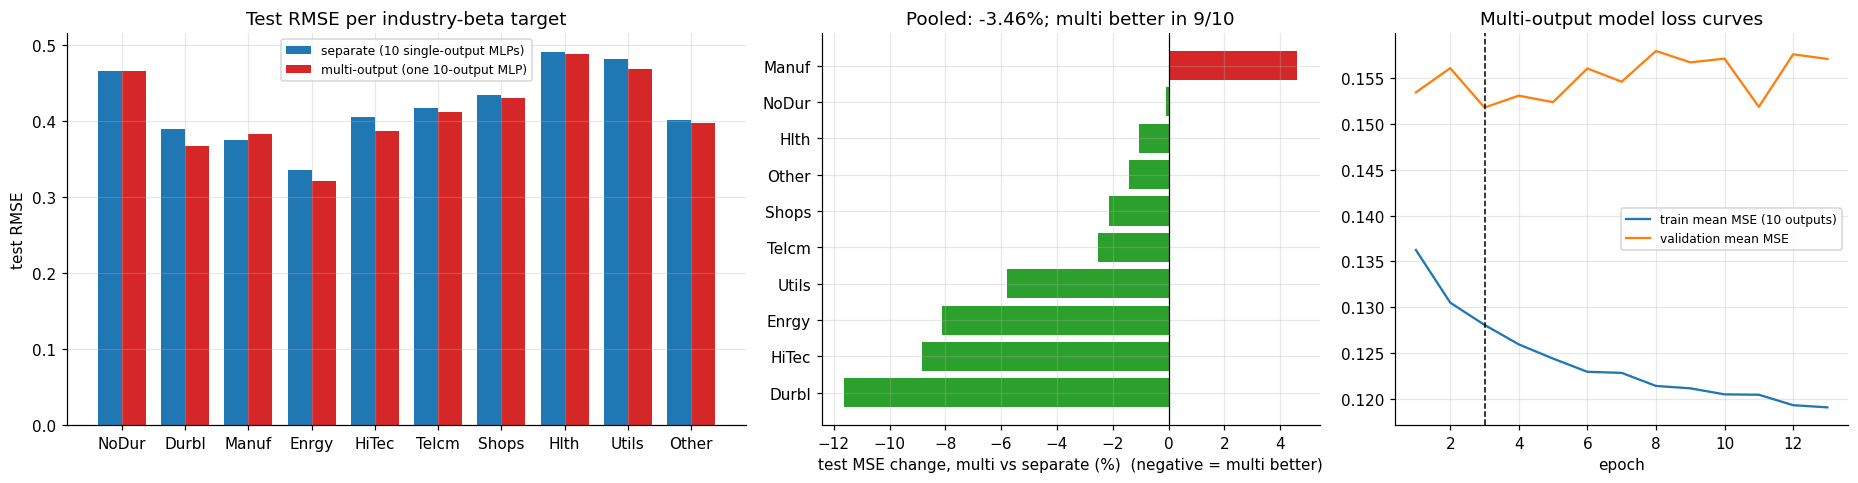

In [81]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.5, 1.1, 1]})
x = np.arange(10); w = 0.38
ax[0].bar(x - w / 2, m8["test RMSE sep"], w, color="#1f77b4", label="separate (10 single-output MLPs)")
ax[0].bar(x + w / 2, m8["test RMSE sim"], w, color="#d62728", label="multi-output (one 10-output MLP)")
ax[0].set_xticks(x); ax[0].set_xticklabels(IND_NAMES); ax[0].set_ylabel("test RMSE")
ax[0].set_title("Test RMSE per industry-beta target"); ax[0].legend(fontsize=8)
o = m8["MSE change sim vs sep %"].sort_values()
ax[1].barh(o.index, o.values, color=["#2ca02c" if v < 0 else "#d62728" for v in o.values])
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlabel("test MSE change, multi vs separate (%)  (negative = multi better)")
ax[1].set_title(f"Pooled: {summary8['change in mean MSE, sim vs sep (%)']:+.2f}%; multi better in {int(m8['sim better'].sum())}/10")
ax[2].plot(sim_hist.epoch, sim_hist.train_mse, label="train mean MSE (10 outputs)")
ax[2].plot(sim_hist.epoch, sim_hist.val_mse, label="validation mean MSE")
ax[2].axvline(sim_info["best_epoch"], color="k", ls="--", lw=1); ax[2].legend(fontsize=8)
ax[2].set_xlabel("epoch"); ax[2].set_title("Multi-output model loss curves")
plt.tight_layout(); savefig("step8_multi_output"); plt.show()

### 8.1 Discussion
**Does joint prediction help? Yes, modestly.**
- On identical test rows, the multi-output model lowers the mean MSE across the ten industry betas by **3.5%** (pooled RMSE 0.422 → 0.415).
- It improves on the separate models for **9 of 10 industries**.
- The pooled gain is statistically reliable: it is positive in 85% of test months, with Newey–West t = 3.8.
- The size is similar to what Cramer, Drobetz & Otto (2026) report (gains of up to 4.8% value-weighted and 6.3% equal-weighted), in a much smaller setting.

**Caveats.**
- In the *validation* period, the separate models were slightly better (mean validation MSE 0.149 vs 0.152), so the advantage is not visible in every period.
- The seed check in **Appendix A** shows that the pooled gain appears for all three seeds (−3.5%, −2.9%, −0.3%), but its size, and especially the
  *per-industry* ranking, varies considerably from run to run. Conclusions about individual industries should be read cautiously.

**Which industries benefit most and least.**
- With seed 42, the largest gains are in **Durables (−11.6%)**, HiTec (−8.8%), Energy (−8.1%) and Utilities (−5.8%).
- **Manufacturing is the one loser (+4.6%)**, and NoDur is unchanged.
- Across seeds, Durables has the largest average gain (−5.8%). NoDur, Durbl, Telcm and Hlth improve under all three seeds. Manufacturing averages about 0.

**Possible reasons.**
1. *A shared common factor.* The ten targets are highly correlated (0.59–0.94) because each largely reflects the firm's general market sensitivity.
   The shared hidden layers learn this common structure from ten targets at once. Each target is a noisy one-year regression slope, so pooling them
   averages out label noise and acts as a regulariser (the classic multi-task learning argument, and the paper's "cross-sectional interdependencies").
   Seven of the ten separate models reach their best validation loss after only 1–2 epochs, so the single-target problems are noisy and overfit quickly.
2. *Noisier, smaller-industry targets gain most.* The Durables portfolio (autos and appliances) is small and idiosyncratic, so a firm's slope on it
   is estimated noisily. Borrowing strength from the other nine targets helps most there.
3. *Targets that already look like the market gain least.* The Manufacturing beta is almost the market beta (correlation 0.96), and a separate model
   already captures that common factor well. In the shared model, the 16 hidden units must also serve nine other outputs, which can slightly compromise its fit.
4. The pattern is **not** simply "more correlated → more gain". Distinctive industries such as Energy and Utilities also benefit, and across the ten industries
   the correlation between co-movement and gain is weak (0.39, with only 10 points). With seed variation this large, finer explanations are not supported.

Limits: the paper uses a richer predictor set (firm characteristics and macro variables), log returns, beta-change targets, rolling re-estimation and portfolio
applications. This classroom version only tests whether sharing hidden layers helps with the same inputs.

---
## Appendix A: Seed Robustness of the Multi-Output Comparison
The differences between separate and multi-output models in Step 8 are small. The Step 4 seed check showed that run-to-run noise from weight initialisation
and minibatch order is about 1% of MSE. To see whether the Step 8 conclusion is robust, the complete Step 8 procedure (10 separate models + 1 multi-output model,
identical settings) is repeated with seeds 1 and 2 and combined with the main run (seed 42). This is a robustness check only. The main results remain those of Step 8,
and nothing is tuned on these test results.

In [82]:
seed_res = {SEED: m8[["test MSE sep", "test MSE sim"]]}
for sd in (1, 2):
    sp, _, smp, _, _, _ = fit_sep_and_sim(sd)
    seed_res[sd] = multi_scores(Ym_te, sp, smp)[["test MSE sep", "test MSE sim"]]
    print(f"seed {sd} done")
sr = pd.concat(seed_res, names=["seed", "industry"])
sr["change %"] = 100 * (sr["test MSE sim"] / sr["test MSE sep"] - 1)

pooled = sr.groupby("seed")[["test MSE sep", "test MSE sim"]].mean()
pooled["pooled RMSE sep"] = np.sqrt(pooled["test MSE sep"]); pooled["pooled RMSE sim"] = np.sqrt(pooled["test MSE sim"])
pooled["change in mean MSE %"] = 100 * (pooled["test MSE sim"] / pooled["test MSE sep"] - 1)
pooled["industries sim better"] = sr.groupby("seed")["change %"].apply(lambda s: int((s < 0).sum()))
pooled.to_csv("results/appendixA_seed_pooled.csv")
print("Pooled results by seed")
display(pooled.round(5))

per_ind = sr["change %"].unstack("seed")
per_ind["mean change %"] = per_ind.mean(1); per_ind["sd"] = per_ind[[SEED, 1, 2]].std(1)
per_ind["seeds with sim better"] = (per_ind[[SEED, 1, 2]] < 0).sum(1)
# Seed-averaged forecasts' MSE (averaging sep and sim over their 3 seeds reduces run-to-run noise)
per_ind = per_ind.reindex(IND_NAMES)
per_ind.to_csv("results/appendixA_seed_per_industry.csv")
print("Per-industry MSE change (multi vs separate, %) by seed")
per_ind.round(2)

seed 1 done


seed 2 done
Pooled results by seed


,test MSE sep,test MSE sim,pooled RMSE sep,pooled RMSE sim,change in mean MSE %,industries sim better
seed,,,,,,
1,0.1796,0.1791,0.4238,0.4232,-0.3184,6
2,0.1812,0.1759,0.4256,0.4193,-2.9347,9
42,0.1781,0.1719,0.4220,0.4147,-3.4634,9


Per-industry MSE change (multi vs separate, %) by seed


seed,42,1,2,mean change %,sd,seeds with sim better
industry,,,,,,
NoDur,-0.0900,-1.6600,-1.7000,-1.1500,0.9200,3
Durbl,-11.6200,-1.6400,-4.0800,-5.7800,5.2000,3
Manuf,4.6000,-0.4600,-4.8500,-0.2400,4.7300,2
Enrgy,-8.1300,-2.0400,0.2300,-3.3100,4.3300,2
HiTec,-8.8400,2.6100,-0.7800,-2.3400,5.8800,2
Telcm,-2.5400,-1.8200,-0.6500,-1.6700,0.9500,3
Shops,-2.1200,0.8700,-6.9100,-2.7200,3.9300,2
Hlth,-1.0700,-1.4600,-2.6800,-1.7400,0.8400,3
Utils,-5.7800,1.6200,-5.0000,-3.0500,4.0700,2


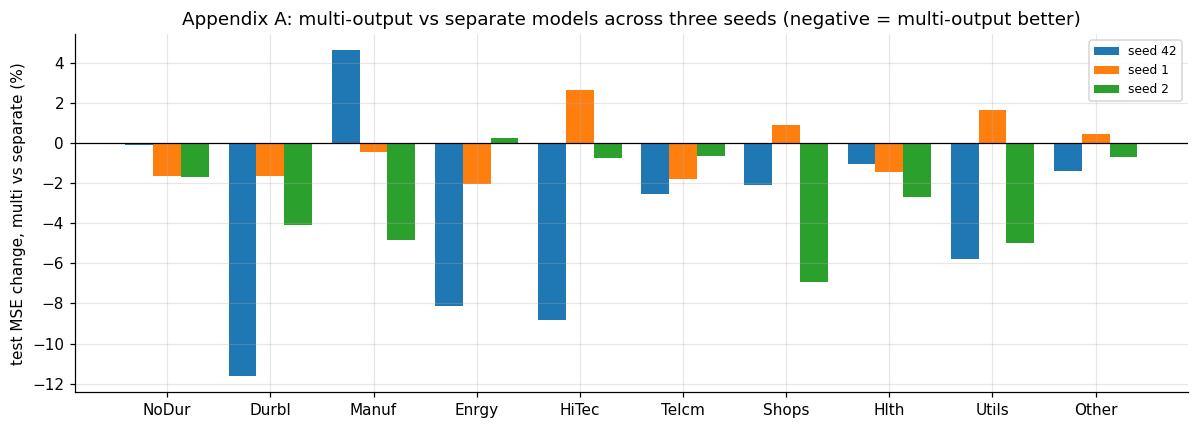

In [83]:
fig, ax = plt.subplots(figsize=(11, 4))
for j, sd in enumerate([SEED, 1, 2]):
    ax.bar(np.arange(10) + (j - 1) * 0.27, per_ind[sd], 0.27, label=f"seed {sd}")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(10)); ax.set_xticklabels(IND_NAMES)
ax.set_ylabel("test MSE change, multi vs separate (%)"); ax.legend(fontsize=8)
ax.set_title("Appendix A: multi-output vs separate models across three seeds (negative = multi-output better)")
plt.tight_layout(); savefig("appendixA_seeds"); plt.show()

**Appendix A conclusion.**
- The multi-output model has a lower pooled test MSE than the separate models for **all three seeds** (−3.5%, −2.9%, −0.3%).
  It wins in 9, 9 and 6 of 10 industries, so the direction of the Step 8 result is robust.
- The size varies a lot, and seed 42 happens to show the largest gain. A fair summary is "about 2% lower pooled MSE on average, and never worse".
- Per-industry differences swing by up to about ±6 percentage points across seeds. Only NoDur, Durbl, Telcm and Hlth improve under every seed.
- So the industry-level ranking in Step 8 should be read as indicative. The pooled comparison is the reliable one.
- Averaging several seeds (an ensemble) would reduce this noise for both approaches. The paper also averages over many estimations.

---
## Appendix B: Page-width figures
The figures above are sized for the notebook. This section redraws the main ones at page width with larger fonts.
No new computation is done here. Every value comes from the objects created in Steps 1–8 and Appendix A.

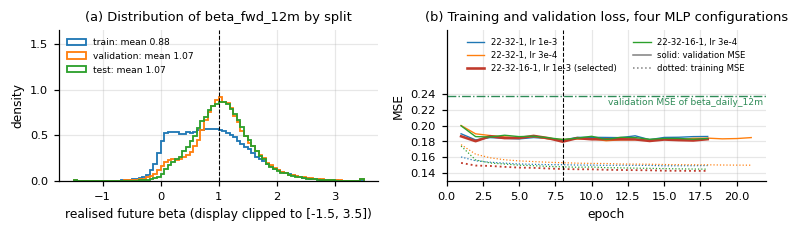

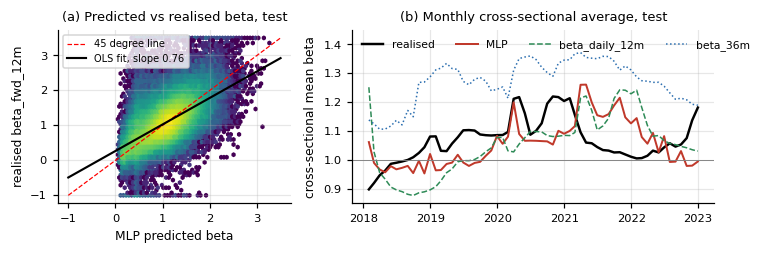

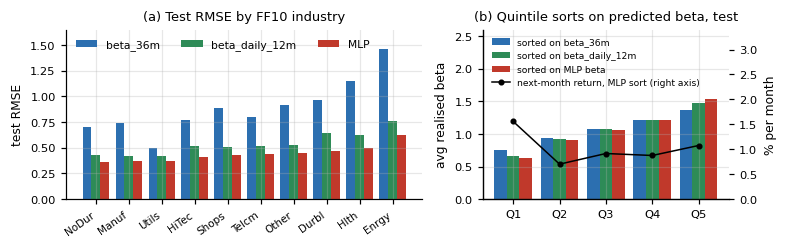

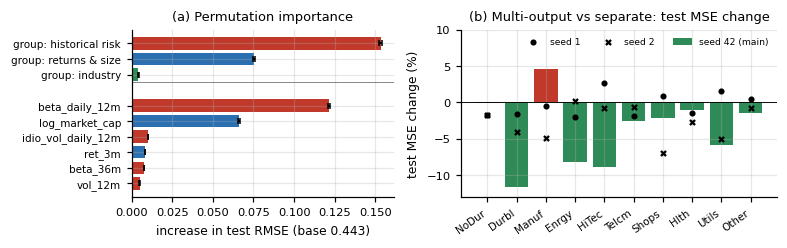

In [84]:
RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
      "legend.fontsize": 7, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": 0.3}
C_NN, C_D, C_36, C_OLS = "#c0392b", "#2e8b57", "#2c6fb0", "#7f7f7f"

with plt.rc_context(RC):
    # R1: target distribution + loss curves
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.15))
    bins = np.linspace(-1.5, 3.5, 81)
    for s in SPLITS:
        v = sample.loc[sample.split == s, TARGET]
        ax[0].hist(v.clip(-1.5, 3.5), bins=bins, density=True, histtype="step", lw=1.2, color=SPLIT_COLORS[s],
                   label=f"{s}: mean {v.mean():.2f}")
    ax[0].axvline(1, color="k", ls="--", lw=0.7); ax[0].set_xlabel("realised future beta (display clipped to [-1.5, 3.5])")
    ax[0].set_ylabel("density"); ax[0].set_title("(a) Distribution of beta_fwd_12m by split")
    ax[0].set_ylim(0, 1.65); ax[0].legend(frameon=False, fontsize=6, loc="upper left")
    cfg_cols = ["#1f77b4", "#ff7f0e", C_NN, "#2ca02c"]
    for (k, v), cc in zip(runs.items(), cfg_cols):
        h = v["hist"]; sel = k == BEST_CFG
        short = k.replace("1 layer (32)", "22-32-1").replace("2 layers (32-16)", "22-32-16-1")
        ax[1].plot(h.epoch, h.val_mse, color=cc, lw=1.7 if sel else 0.9, label=short + (" (selected)" if sel else ""))
        ax[1].plot(h.epoch, h.train_mse, color=cc, lw=1.2 if sel else 0.8, ls=":")
    ax[1].plot([], [], color="grey", lw=1, label="solid: validation MSE")
    ax[1].plot([], [], color="grey", lw=1, ls=":", label="dotted: training MSE")
    ax[1].axvline(runs[BEST_CFG]["best_epoch"], color="k", ls="--", lw=0.7)
    dmse = bench.loc[("validation", "beta_daily_12m"), "RMSE"] ** 2
    ax[1].axhline(dmse, color=C_D, ls="-.", lw=0.9)
    ax[1].text(ax[1].get_xlim()[1], dmse - 0.002, "validation MSE of beta_daily_12m ", color=C_D, fontsize=6, ha="right", va="top")
    ax[1].set_ylim(0.13, 0.32); ax[1].set_yticks([0.14, 0.16, 0.18, 0.20, 0.22, 0.24]); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("MSE")
    ax[1].set_title("(b) Training and validation loss, four MLP configurations"); ax[1].legend(frameon=False, fontsize=5.6, ncol=2, loc="upper center")
    plt.tight_layout(); plt.savefig("figures/report_fig1.png", bbox_inches="tight"); plt.savefig("figures/report_fig1.pdf", bbox_inches="tight"); plt.show()

    # R2: scatter + time series
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.35), gridspec_kw={"width_ratios": [1, 1.55]})
    p_ = preds_test["MLP (neural net)"]
    ax[0].hexbin(np.clip(p_, -1, 3.5), np.clip(y_test, -1, 3.5), gridsize=55, bins="log", cmap="viridis", mincnt=1)
    ax[0].plot([-1, 3.5], [-1, 3.5], "r--", lw=0.8, label="45 degree line")
    b1, b0 = np.polyfit(p_, y_test, 1)
    ax[0].plot([-1, 3.5], [b0 - b1, b0 + 3.5 * b1], "k-", lw=1.4, label=f"OLS fit, slope {b1:.2f}")
    ax[0].set_xlabel("MLP predicted beta"); ax[0].set_ylabel("realised beta_fwd_12m")
    ax[0].set_title("(a) Predicted vs realised beta, test"); ax[0].legend(frameon=True, loc="upper left", fontsize=6.5)
    ax[1].plot(ts5.index, ts5.realised, color="k", lw=1.6, label="realised")
    ax[1].plot(ts5.index, ts5.MLP, color=C_NN, lw=1.3, label="MLP")
    ax[1].plot(ts5.index, ts5.beta_daily_12m, color=C_D, lw=1, ls="--", label="beta_daily_12m")
    ax[1].plot(ts5.index, ts5.beta_36m, color=C_36, lw=1, ls=":", label="beta_36m")
    ax[1].axhline(1, color="grey", lw=0.6); ax[1].set_ylabel("cross-sectional mean beta")
    ax[1].set_title("(b) Monthly cross-sectional average, test"); ax[1].legend(frameon=False, ncol=4, loc="upper left")
    ax[1].set_ylim(0.85, 1.45)
    plt.tight_layout(); plt.savefig("figures/report_fig2.png", bbox_inches="tight"); plt.savefig("figures/report_fig2.pdf", bbox_inches="tight"); plt.show()

    # R3: RMSE by industry + quintiles
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.3), gridspec_kw={"width_ratios": [1.45, 1]})
    order = ind_err.drop(index="Unknown", errors="ignore").sort_values("RMSE MLP (neural net)").index
    x = np.arange(len(order)); w = 0.27
    for j, (k, c, lab) in enumerate([("beta_36m", C_36, "beta_36m"), ("beta_daily_12m", C_D, "beta_daily_12m"),
                                     ("MLP (neural net)", C_NN, "MLP")]):
        ax[0].bar(x + (j - 1) * w, ind_err.loc[order, f"RMSE {k}"], w, color=c, label=lab)
    ax[0].set_xticks(x); ax[0].set_xticklabels(order, rotation=35, fontsize=6.8, ha="right"); ax[0].set_ylabel("test RMSE")
    ax[0].set_title("(a) Test RMSE by FF10 industry"); ax[0].legend(frameon=False, ncol=3, loc="upper left"); ax[0].set_ylim(0, 1.65)
    xq = np.arange(1, 6)
    for j, (col, c, lab) in enumerate([("beta_36m", C_36, "sorted on beta_36m"), ("beta_daily_12m", C_D, "sorted on beta_daily_12m"),
                                       ("beta_NN", C_NN, "sorted on MLP beta")]):
        ax[1].bar(xq + (j - 1) * w, comp[col]["avg realised beta"], w, color=c, label=lab)
    ax[1].set_xticks(xq); ax[1].set_xticklabels([f"Q{i}" for i in xq]); ax[1].set_ylabel("avg realised beta")
    ax[1].set_ylim(0, 2.6)
    ax2 = ax[1].twinx(); ax2.plot(xq, 100 * qt.loc[[1, 2, 3, 4, 5], "avg_next_month_return"], "ko-", ms=3, lw=1,
                                  label="next-month return, MLP sort (right axis)")
    ax2.set_ylabel("% per month"); ax2.set_ylim(0, 3.4); ax2.grid(False)
    h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax[1].legend(h1 + h2, l1 + l2, frameon=False, fontsize=6, loc="upper left")
    ax[1].set_title("(b) Quintile sorts on predicted beta, test")
    plt.tight_layout(); plt.savefig("figures/report_fig3.png", bbox_inches="tight"); plt.savefig("figures/report_fig3.pdf", bbox_inches="tight"); plt.show()

    # R4: permutation importance + multi-output
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.3), gridspec_kw={"width_ratios": [1, 1.2]})
    top = var_tab.head(6).iloc[::-1]
    labels = [f"group: {g}" for g in imp_tab.index[::-1]] + list(top.index)
    vals = list(imp_tab.mean_RMSE_increase[::-1]) + list(top.mean_RMSE_increase)
    errs = list(imp_tab.sd_RMSE_increase[::-1]) + list(top.sd)
    gc = {"historical risk": C_NN, "returns & size": C_36, "industry": C_D}
    cols = [gc[g] for g in imp_tab.index[::-1]] + [gc[g] for g in top.group]
    ypos = [7, 8, 9] + list(range(6))          # groups on top, separated from the single variables
    ax[0].barh(ypos, vals, xerr=errs, color=cols, capsize=2)
    ax[0].set_yticks(ypos); ax[0].set_yticklabels(labels, fontsize=6.8)
    ax[0].axhline(6.5, color="grey", lw=0.6)
    ax[0].set_xlabel(f"increase in test RMSE (base {base_rmse:.3f})")
    ax[0].set_title("(a) Permutation importance")
    o = per_ind.reindex(IND_NAMES)
    xi = np.arange(10)
    ax[1].bar(xi, o[SEED], color=[C_D if v < 0 else C_NN for v in o[SEED]], label="seed 42 (main)")
    ax[1].scatter(xi, o[1], color="k", s=9, marker="o", label="seed 1", zorder=3)
    ax[1].scatter(xi, o[2], color="k", s=11, marker="x", label="seed 2", zorder=3)
    ax[1].axhline(0, color="k", lw=0.6); ax[1].set_xticks(xi); ax[1].set_xticklabels(IND_NAMES, fontsize=6.8, rotation=35, ha="right")
    ax[1].set_ylabel("test MSE change (%)")
    ax[1].set_title("(b) Multi-output vs separate: test MSE change")
    ax[1].set_ylim(-13, 10)
    ax[1].legend(frameon=False, fontsize=6, loc="upper right", ncol=3)
    plt.tight_layout(); plt.savefig("figures/report_fig4.png", bbox_inches="tight"); plt.savefig("figures/report_fig4.pdf", bbox_inches="tight"); plt.show()